<center>
    <h2 style="font-size: 48px; margin-bottom: 5px;"><b>PROJECT A&CO</b></h2>
</center>

<center>
    <h3 style="font-size: 36px; margin-top: 0px; margin-bottom: 5px;">- DELIVERABLE  -</h3>
</center>

<br> <br>

<center> <img src="https://www.alsacetech.org/wp-content/uploads/2017/05/cesi_CMJN-e1673249263164.png" alt="logo" width="200"></center>

<br> <br>

## Group 2 :
- ACACHA Elie
- PALE Kharice
- DEMIRHINDI Sude
- MERKICHE Isak
- LOUACHE Manyl

<br> <br>


# **CONTEXT**

Since the 1990s reducing energy consumption and greenhouse gas emissions have become a global objective. Transportation and delivery services contribute to these emissions, and improving delivery routes can help reduce the environmental impact. In this context ADEME (the French Environment and Energy Management Agency) promotes the development of mobility solutions for people and goods. CesiCDP wants to respond to this initiative by developing a method for managing delivery routes. Optimizing delivery routes can help companies reduce fuel consumption, travel time and operating costs.

# **PROBLEM**

Here we want to develop a method to manage delivery routes. Our main goal is to optimize those routes to reduce the company's fuel consumption, travel time and operating costs. The main problem of this project is to optimize the delivery routes on a road network. The objective is to find efficient delivery routes for a convoy of delivering trucks that go to different customers and return to the starting point while minimizing travel time and respecting each delivery time window. This problem is known as the Capacitated Vehicle Routing Problem with Time Windows (CVRPTW). Each truck has a capacity, and every customer must receive their deliveries in their time window and at each customer we must verify a certain service time duration. The algorithm must decide which customers each truck should visit and in which order. The main challenges are the number of possible delivery routes, the capacity limits of the trucks and the differences in traffic conditions and the different time constraints. As the number of customers increases finding the best delivery routes becomes more difficult. This problem therefore requires efficient algorithms.

# **OVERALL OBJECTIVES**
The main objective is to develop an algorithm that finds efficient delivery routes for realistic situations, which can involve several thousand customers. In this project we test instances of up to 1000 customers.
The project has specific objectives:
- Model the delivery problem mathematically.
-	Develop an algorithm in Python to calculate delivery routes.
-	Respect the capacity limits of the trucks.
-	Minimize the travel time.
-	Evaluate the algorithm's performance in terms of computation time and solution quality.
-	Test the algorithm on instances and compare its results with known reference solutions.
-	Respect the time windows: each customer must be served during a specific period.

# **Concrete Examples and Use Cases**

A typical example is a delivery company that must deliver packages to 100 customers using trucks. Each truck has a carrying capacity and every customer must be visited. A simple solution would be to visit customers in the order in which their addresses are received. However, this could create long delivery routes, unnecessary travel and higher fuel consumption. With delivery route optimization the algorithm assigns customers to trucks and determines the order of visits to reduce the total travel time while respecting vehicle capacities. Another example is supermarket delivery service. Some customers may only be available to receive their orders between 10 a.m. and noon. In this version the algorithm must organize the delivery routes so that deliveries take place within these time windows. These applications show how delivery route optimization can improve delivery efficiency, reduce operating costs and support sustainable transportation.


# **Modeling and solution methods**


## Data Formalization

### 1. Benchmark instances and file formats

We test our methods on the **Solomon benchmark** (100 customers) and its extension by **Gehring & Homberger** (200 to 1000 customers), the standard benchmarks for the CVRPTW. All files come from the [PyVRP/VRPLIB](https://github.com/PyVRP/VRPLIB) repository (the Solomon files and their `.sol` solutions are in `tests/data/cvrplib/Vrp-Set-Solomon`). We read them with the Python package `vrplib`, which returns every instance as the same Python dictionary, whatever its file format.

The instances come in two file formats.

#### 1.1 Solomon format (`.txt`)

This is the original format of the benchmark. The file has a short header with the fleet, followed by a table with one row per node. Row `0` is the depot.

```
C101

VEHICLE
NUMBER     CAPACITY
  25         200

CUSTOMER
CUST NO.  XCOORD.   YCOORD.    DEMAND   READY TIME  DUE DATE   SERVICE   TIME
    0      40         50          0          0       1236          0
    1      45         68         10        912        967         90
    2      45         70         30        825        870         90
```

| Column | Meaning |
|---|---|
| `NUMBER` | number of available vehicles |
| `CAPACITY` | capacity of each vehicle (all vehicles are identical) |
| `CUST NO.` | node index (0 = depot) |
| `XCOORD.`, `YCOORD.` | coordinates of the node |
| `DEMAND` | quantity to deliver to the customer |
| `READY TIME`, `DUE DATE` | time window: earliest and latest start of service |
| `SERVICE TIME` | duration of the service at the customer |

The file contains **no distances**: `vrplib` computes them from the coordinates as real-valued Euclidean distances. It is read with `vrplib.read_instance(path, instance_format="solomon")`.

#### 1.2 VRPLIB / LKH-3 format (`.vrptw`)

This format follows the TSPLIB convention: a header of `KEY : value` lines, then one section per type of data.

```
NAME : C102
TYPE : CVRPTW
DIMENSION : 101          <- number of nodes (depot + 100 customers)
VEHICLES : 10
CAPACITY : 200
SERVICE_TIME : 90        <- one value for every customer
EDGE_WEIGHT_TYPE : EXACT_2D
NODE_COORD_SECTION       <- "node x y"
1 40 50
2 45 68
...
DEMAND_SECTION           <- "node demand"
TIME_WINDOW_SECTION      <- "node ready due"
DEPOT_SECTION            <- depot index, ended by -1
1
-1
EOF
```

Differences with the Solomon format:

- Nodes are numbered from **1** in the file; `vrplib` shifts them so that the depot is node **0**, as in the Solomon files.
- The service time is a **single value** for all customers. The depot has no service, so we set $s_0 = 0$.
- `EDGE_WEIGHT_TYPE` tells how distances are computed. With `EXACT_2D` and `EUC_2D`, `vrplib` returns the real Euclidean distance; with `FLOOR_2D`, it rounds the distance down to an integer. All the instances we use give real distances.
- In the LKH-3 files, the fleet is much tighter: it equals the number of vehicles of the best known solution. In the file name `C102.100.10`, 100 is the number of customers and 10 the number of vehicles. For C102 this is exactly $\lceil \sum_i d_i / Q \rceil = 10$, so no vehicle is spare; C1_2_1.200.20 has 20 vehicles for a minimum of 18, and C1_10_1.1000.100 has 100 for a minimum of 90.

It is read with `vrplib.read_instance(path)`.

#### 1.3 Data actually used in our computations

Some fields of the files describe the instance but do not take part in the computations (`NAME`, `TYPE`, `COMMENT`, `DIMENSION`, `DEPOT_SECTION`, `SCALE`). The table below lists the fields that do take part, and how `vrplib` gives them to us.

| Data | Solomon `.txt` | `.vrptw` | `vrplib` key | Python shape | Symbol |
|---|---|---|---|---|---|
| Number of vehicles | `NUMBER` | `VEHICLES` | `vehicles` | integer | $\lvert K\rvert$ |
| Vehicle capacity | `CAPACITY` | `CAPACITY` | `capacity` | integer | $Q$ |
| Coordinates | `XCOORD.`, `YCOORD.` | `NODE_COORD_SECTION` | `node_coord` | $(n+1)\times 2$ | $(x_i, y_i)$ |
| Demands | `DEMAND` | `DEMAND_SECTION` | `demand` | $n+1$ | $d_i$ |
| Time windows | `READY TIME`, `DUE DATE` | `TIME_WINDOW_SECTION` | `time_window` | $(n+1)\times 2$ | $[b_i, e_i]$ |
| Service times | `SERVICE TIME` | `SERVICE_TIME` | `service_time` | $n+1$ or scalar | $s_i$ |
| Travel times | computed | computed | `edge_weight` | $(n+1)\times(n+1)$ | $\tau_{ij}$ |

The depot row gives $d_0 = 0$, and its time window $[b_0, e_0]$ is the working day: vehicles leave the depot at $b_0$ at the earliest and must be back by $e_0$.

#### 1.4 Instances used in this project

| Instance | Format | Customers $n$ | Vehicles $\lvert K\rvert$ | $Q$ | Total demand | Min. vehicles $\lceil \sum d_i / Q\rceil$ | $[b_0, e_0]$ | Used for |
|---|---|---|---|---|---|---|---|---|
| C101 | Solomon `.txt` | 100 | 25 | 200 | 1810 | 10 | [0, 1236] | ILP and ALNS, reference solution `C101.sol` |
| C101-25, C101-50 | `.vrptw` (EXACT_2D) | 25 / 50 | 3 / 5 | 200 | 460 / 860 | 3 / 5 | [0, 1236] | ALNS, time per iteration only (first 25 and 50 customers of C101) |
| R101 | Solomon `.txt` | 100 | 25 | 200 | 1458 | 8 | [0, 230] | ALNS, random customers, narrowest windows (width 10), reference solution `R101.sol` |
| RC101 | Solomon `.txt` | 100 | 25 | 200 | 1724 | 9 | [0, 240] | ALNS, mixed customers, reference solution `RC101.sol`; ILP on its first 20 customers (total demand 430, 3 vehicles at least) |
| C102.100.10 | `.vrptw` (EXACT_2D) | 100 | 10 | 200 | 1810 | 10 | [0, 1236] | ALNS, wider time windows, BKS from SINTEF |
| C1_2_1.200.20 | `.vrptw` (EXACT_2D) | 200 | 20 | 200 | 3530 | 18 | [0, 1351] | ALNS (tuning), BKS from SINTEF (2704.57) |
| R105, R109 | Solomon `.txt` | 100 | 25 | 200 | 1458 | 8 | [0, 230] | ALNS, random customers, mean window width 30 and 59, reference solutions `.sol` |
| RC105, RC108 | Solomon `.txt` | 100 | 25 | 200 | 1724 | 9 | [0, 240] | ALNS, mixed customers, mean window width 54 and 112, reference solutions `.sol` |
| C201 | Solomon `.txt` | 100 | 25 | 700 | 1810 | 3 | [0, 3390] | ALNS, series 2: long horizon and few long routes, reference solution `C201.sol` |
| R201, RC201 | Solomon `.txt` | 100 | 25 | 1000 | 1458 / 1724 | 2 | [0, 1000] / [0, 960] | ALNS, series 2, reference solutions `.sol` |
| C1_4_1, C1_6_1, C1_8_1 | `.vrptw` (EXACT_2D) | 400 / 600 / 800 | 40 / 60 / 80 | 200 | 7190 / 11020 / 14380 | 36 / 56 / 72 | [0, 1501] / [0, 1496] / [0, 1676] | ALNS, time per iteration only (no reference solution in the file) |
| C103, R102, RC103 | Solomon `.txt` | 100 | 25 | 200 | 1810 / 1458 / 1724 | 10 / 8 / 9 | [0, 1236] / [0, 230] / [0, 240] | ALNS, series 1, wider windows than C101 / R101 / RC101 (mean width 589 / 57 / 113), reference solutions `.sol` |
| C202, R202, RC202, R211 | Solomon `.txt` | 100 | 25 | 700 / 1000 / 1000 / 1000 | 1810 / 1458 / 1724 / 1458 | 3 / 2 / 2 / 2 | [0, 3390] / [0, 1000] / [0, 960] / [0, 1000] | ALNS, series 2 (mean width 938 / 329 / 319 / 472), reference solutions `.sol` |
| C1_10_1.1000.100 | `.vrptw` (EXACT_2D) | 1000 | 100 | 200 | 17940 | 90 | [0, 1824] | ALNS, quality and time at 1000 customers, BKS from SINTEF (42478.95) |

For the ILP, an instance can be cut down to its depot and its **first $n$ customers**, to study how the solving time grows with $n$.

For the reference instances, the `.sol` files give the best known solution: one line per route, then its cost. The published cost of C101 (827.3) uses distances truncated to one decimal, the original Solomon convention. With exact distances, the same routes cost **828.94**, so we always recompute the reference cost with our own distances before we compare.

### 2. Graph model

An instance is modelled as a **complete directed graph**

$$
G = (V, A), \qquad V = \{0\} \cup N, \qquad N = \{1, \dots, n\}, \qquad A = \{(i,j) \in V \times V : i \neq j\}
$$

- Node $0$ is the depot, where every route starts and ends.
- $N$ is the set of the $n$ customers.
- An arc $(i,j)$ is a direct trip from $i$ to $j$. Every pair of nodes is linked, so $\lvert A\rvert = n(n+1)$, which gives 650 arcs for 25 customers and 10 100 for 100 customers.

**Weight of an arc.** Following the Solomon convention, one unit of distance takes one unit of time, so the travel time is the Euclidean distance between the two nodes:

$$
\tau_{ij} = c_{ij} = \sqrt{(x_i - x_j)^2 + (y_i - y_j)^2}
$$

The travel time $\tau_{ij}$ is also the cost $c_{ij}$ that we minimise. The matrix is symmetric ($\tau_{ij} = \tau_{ji}$) and satisfies the triangle inequality, so going through an extra customer never shortens a trip.

**Weight of a node.** Each customer $i \in N$ carries a demand $d_i$, a time window $[b_i, e_i]$ and a service time $s_i$.

**Real-valued times.** Both methods use the exact, real Euclidean distances. The ILP uses the matrix `edge_weight` from `vrplib`, and the ALNS recomputes the same distances from the coordinates. In the ILP, the service start times are continuous variables, so travel times do not need to be integers.

**Why a complete graph.** The real problem lives on a road network, which is a sparse graph: most pairs of places are not linked by a direct road. A vehicle, however, never needs to know the roads themselves, only the cost of the best way from one stop to the next. We therefore replace the road network by its **distance closure**: an arc $(i, j)$ for every pair of nodes, weighted by the length of the shortest path from $i$ to $j$ in the road network (computed once, for example with Dijkstra from every node). This graph is complete and satisfies the triangle inequality by construction, and an optimal set of routes in it maps back to an optimal set of routes on the roads. The benchmark instances give coordinates without a road network, so the Euclidean distance plays the role of this shortest-path distance.

**Why an adjacency matrix.** The graph is complete, so it has $n(n+1)$ arcs: an adjacency list would store as many entries as a matrix, with slower access. We store the weights in a dense $(n+1) \times (n+1)$ numpy matrix: reading $\tau_{ij}$ costs $O(1)$, and a whole row or column can be read at once, which lets the insertion test examine every position of a route in one vectorised operation. Memory is $O(n^2)$, i.e. 8 MB for 1000 customers.

### 3. Fleet

The fleet $K$ is **homogeneous**: every vehicle has the same capacity: $Q = 200$ in series 1 and in the Gehring & Homberger instances, $Q = 700$ in C201 and $Q = 1000$ in R201 and RC201. $\lvert K\rvert$ is an **upper bound**: a solution may use fewer vehicles. Each vehicle used performs a single route $R_k = (0, i_1, \dots, i_r, 0)$, and its load must not exceed the capacity:

$$
\sum_{i \in R_k} d_i \le Q
$$

Since demands cannot be split, at least $\lceil \sum_{i \in N} d_i / Q \rceil$ vehicles are needed. For C101 this gives 10 vehicles, and the best known solution indeed uses 10 routes out of the 25 available.

### 4. Time along a route

A vehicle leaves the depot at $T_0 = b_0$. When it goes from $i$ to $j$, it arrives at $a_j = T_i + s_i + \tau_{ij}$. If it arrives before the window opens, it waits, so service starts at

$$
T_j = \max(b_j, a_j)
$$

The route is feasible if $T_j \le e_j$ for every customer visited and if the vehicle is back at the depot by $e_0$. In C101 every customer needs $s_i = 90$ time units of service, which is long compared with the travel times (for example $\tau_{01} \approx 18.7$). Time windows, more than distances, therefore drive the number of customers a vehicle can serve.


## Complexity Proof
## 1. Complexity classification

The **Capacitated Vehicle Routing Problem with Time Windows (CVRPTW)** is an NP-hard combinatorial problem.

The objective is to minimize the total routing time cost while satisfying vehicle capacity constraints and customer time-window constraints. Every customer must be visited exactly once, and every vehicle route must start and end at the depot.

To establish its complexity, we consider the associated decision problem.

**CVRPTW-Decision**: Given a CVRPTW instance and a cost bound $B$, does there exist a set of feasible vehicle routes whose total cost is at most $B$ ?
The complexity classification is:
- Decision version: **NP-complete**.
- Optimization version: **NP-hard**.

We establish this classification by proving that the decision version belongs to NP and is NP-hard through a polynomial-time reduction from the decision version of the traveling salesman problem (TSP).

## 2. Proof that CVRPTW-Decision belongs to NP

To prove that CVRPTW-Decision belongs to NP, we must show that a proposed solution can be verified in polynomial time.

### Certificate

A certificate is a set of vehicle routes representing a solution structure for our problem:

$$
S=(R_1,R_2,\ldots,R_m)
\qquad m\leq |K|
$$

where each route starts and ends at the depot and gives the sequence of customers visited by its vehicle. The certificate has polynomial size: it lists each customer once and the depot twice per route, so at most $n + 2\lvert K\rvert$ nodes.

### Verification

Given a certificate $S$, we must verify the following conditions based on the problem constraints.

1. **Customer coverage:** Every customer is visited exactly once.
2. **Route structure:** Every vehicle route starts and ends at the depot, and the number of routes does not exceed the available fleet size.
3. **Capacity constraints:** For each route $R_k$, the total demand of its customers does not exceed the vehicle capacity $Q$.
4. **Time-window constraints:** Each customer is served within its time window.
5. **Cost bound:** the total cost of all routes is at most $B$.
6. **Depot return deadline:** every route returns by time $e_0$.

For time-window verification, let customer $i$ have a time window $[b_i,e_i]$, service duration $s_i$, and let $\tau_{ij}$ be the travel time from customer $i$ to customer $j$.

The earliest feasible service-start time at customer $j$, following customer $i$, is:

$$
T_j=\max\left(b_j,T_i+s_i+\tau_{ij}\right)
$$

We then verify that $T_j\leq e_j$.
If this inequality fails for any customer, the proposed route is infeasible. Otherwise, we continue along the route, and finally check that the vehicle is back at the depot by $e_0$.

Each node of the certificate is processed once, in constant time: one look-up in the travel-time matrix, one update of the load and of the time, and one mark in a boolean array to detect a customer visited twice or never. The whole verification therefore runs in $O(n + \lvert K\rvert)$, which is polynomial in the input size.

Therefore,

$$
\boxed{\text{CVRPTW-Decision}\in NP}
$$

## 3. Proof that CVRPTW-Decision is NP-Hard

We are going to prove this by reducing the decision problem of the travelling salesman problem to CVRPTW-Decision.

### 3.1. Source problem: TSP-Decision

An instance of TSP-Decision consists of a complete weighted graph $G=(V,E)$
a depot vertex $r\in V$, edge costs $c_{ij}$ and a cost bound $B$.

The question is whether there exists a Hamiltonian cycle that starts at $r$, visits every vertex exactly once, returns to $r$, and has total time cost at most $B$.

TSP-Decision is NP-complete (Karp, 1972, through the Hamiltonian cycle problem).

### 3.2. Polynomial-time transformation

Let $m=|V|$. Given an arbitrary TSP-Decision instance, construct a CVRPTW instance as follows:

- **Depot:** use the TSP vertex $r$ as the depot, relabeled $0$.
- **Customers:** each vertex in $V\setminus\{r\}$ becomes a customer.
- **Fleet size:** provide exactly **one** vehicle.
- **Demand:** set $d_i=1$ for every customer.
- **Vehicle capacity:** set $Q=m-1$, sufficient to serve all customers.
- **Travel costs:** preserve every TSP arc cost, $c'_{ij}=c_{ij}$.
- **Travel times:** set $\tau'_{ij}=c_{ij}$ so that total travel time equals TSP tour cost.
- **Service times:** set $s_i=0$ for every customer and for the depot.
- **Time windows:** assign $[0,H]$ to every customer and to the depot, with

$$
H=mC_{\max}+1,\qquad C_{\max}=\max_{(i,j)\in E}c_{ij}.
$$

A Hamiltonian cycle has exactly $m$ arcs, each costing at most $C_{\max}$; therefore its total travel time is at most $mC_{\max}<H$. These wide windows do not remove any TSP tour.

- **Objective bound:** keep the same bound $B$.

The constructed instance contains a polynomial number of nodes and arcs. Because the integer $H$ has polynomially many bits relative to the input encoding, this transformation runs in polynomial time.

### 3.3. Proof of reduction

We prove equivalence in both directions.

**Direction 1: TSP-Decision has a solution $\Rightarrow$ CVRPTW-Decision has a solution.**

Suppose that the TSP instance has a Hamiltonian cycle of total cost at most $B$. Use this cycle as the route of the single vehicle. Every customer is visited exactly once; capacity $Q=m-1$ allows all unit demands; service durations are zero; and the time horizon is large enough to accommodate the complete route. Since travel times equal the original TSP costs, the total CVRPTW travel time is also at most $B$. Therefore, the constructed CVRPTW instance is a **yes-instance**.

**Direction 2: CVRPTW-Decision has a solution $\Rightarrow$ TSP-Decision has a solution.**

Suppose that the constructed CVRPTW instance admits a feasible solution of total travel time at most $B$. There is only one vehicle, and the routing rules require it to start from the depot, serve every customer exactly once and return to the depot. Consequently, its route is a Hamiltonian cycle through all vertices of the original TSP graph. Because the travel times were copied from TSP arc costs, the original cycle has cost at most $B$. Therefore, the TSP instance is also a **yes-instance**.

We have established:

$$
\boxed{\text{TSP-Decision is a yes-instance}\iff\text{CVRPTW-Decision is a yes-instance}.}
$$

Hence:

$$
\text{TSP-Decision}\leq_p\text{CVRPTW-Decision}.
$$

Since TSP-Decision is NP-complete, CVRPTW-Decision is NP-hard. Combined with membership in NP, this yields:

$$
\boxed{\text{CVRPTW-Decision is NP-complete}.}
$$

Consequently, the **optimization version of the general CVRPTW is NP-hard**.


## Mathematical Modeling (ILP)

We use the compact **two-index formulation**. Since all vehicles are identical, one set of arc variables is enough for the whole fleet: we do not need to know *which* vehicle drives an arc, only *whether* an arc is used. Loads and times are tracked with Miller–Tucker–Zemlin (MTZ) style constraints, linearised with big-M.

### 1. Data

We use the notation of the Data Formalization: the graph $G = (V, A)$ with $V = \{0\} \cup N$, the travel times $\tau_{ij} = c_{ij}$, the demands $d_i$, the service times $s_i$ (with $s_0 = 0$), the time windows $[b_i, e_i]$, the depot window $[b_0, e_0]$, the capacity $Q$ and the fleet size $\lvert K\rvert$.

### 2. Variables

| Variable | Domain | Meaning |
|---|---|---|
| $x_{ij}$ | $\{0,1\}$, $(i,j) \in A$ | $=1$ if a vehicle travels directly from $i$ to $j$ |
| $T_i$ | $\mathbb{R}_{\ge 0}$, $i \in V$ | start of service at node $i$ ($T_0$ = departure time from the depot) |
| $u_i$ | $\mathbb{R}$, $i \in N$ | load of the vehicle just after it serves customer $i$ |

### 3. Objective

$$
\min \sum_{(i,j) \in A} c_{ij}\, x_{ij}
$$

### 4. Constraints

$$
\begin{aligned}
&(1)\ \textstyle\sum_{j : (i,j) \in A} x_{ij} = 1 && \forall i \in N && \text{each customer is left exactly once}\\
&(2)\ \textstyle\sum_{j : (j,i) \in A} x_{ji} = 1 && \forall i \in N && \text{each customer is reached exactly once}\\
&(3)\ \textstyle\sum_{j \in N} x_{0j} \le \lvert K\rvert && && \text{fleet size}\\
&(3')\ \textstyle\sum_{j \in N} x_{0j} \ge \left\lceil \sum_{i \in N} d_i / Q \right\rceil && && \text{valid inequality}\\
&(4)\ u_j \ge u_i + d_j - Q\,(1 - x_{ij}) && \forall (i,j) \in A,\ i, j \in N && \text{load propagation}\\
&(5)\ d_i \le u_i \le Q && \forall i \in N && \text{capacity}\\
&(6)\ T_j \ge T_i + s_i + \tau_{ij} - M_{ij}\,(1 - x_{ij}) && \forall (i,j) \in A,\ j \in N && \text{schedule consistency}\\
&(7)\ T_i + s_i + \tau_{i0} \le e_0 + M_{i0}\,(1 - x_{i0}) && \forall i \in N && \text{return to the depot before closing}\\
&(8)\ b_i \le T_i \le e_i && \forall i \in V && \text{time windows}
\end{aligned}
$$

Constraints (1) and (2) also balance the depot: $n$ arcs leave the customers and $n$ arcs reach them, so as many vehicles come back to the depot as leave it. All vehicles share the departure time $T_0$. This loses nothing: waiting is allowed, so leaving at $b_0$ is always possible.

### 5. Choice of the big-M values

When $x_{ij} = 1$, the term $M(1 - x_{ij})$ is zero and the constraint applies. When $x_{ij} = 0$, the constraint must hold for **every** feasible value of the variables, so that it is inactive. This gives the **smallest valid M**:

- **Time (6):** we need $T_i + s_i + \tau_{ij} - M_{ij} \le T_j$ for all $T_i \le e_i$ and $T_j \ge b_j$, so
$$M_{ij} = \max(0,\ e_i + s_i + \tau_{ij} - b_j).$$
- **Return (7):** in the same way, $M_{i0} = \max(0,\ e_i + s_i + \tau_{i0} - e_0)$.
- **Load (4):** we need $u_i + d_j - M \le u_j$ for all $u_i \le Q$ and $u_j \ge d_j$, so $M = Q$ is enough.

Any larger M gives the same integer solutions, but a weaker **linear relaxation**: a small fractional value of $x_{ij}$ is then enough to switch the constraint almost off. The lower bound gets worse, and the branch and bound must explore more nodes before it proves optimality.

### 6. Subtour elimination

Constraints (4) and (6) also remove **subtours**, that is, cycles of customers that do not go through the depot. Along such a cycle, the load would increase strictly at every arc ($d_j > 0$) and so would the time ($s_i + \tau_{ij} > 0$), which is impossible on a cycle. This argument needs positive demands or positive times, which holds in every Solomon instance ($d_i > 0$ and $s_i > 0$). The depot is left out of (4) and handled by (7), so cycles through the depot, which are the actual routes, stay allowed.

### 7. Valid inequality (3')

At least $\lceil \sum_i d_i / Q \rceil$ vehicles are needed to carry the total demand, so (3') removes no integer solution. It does tighten the linear relaxation, though. Without it, when the objective is the number of vehicles, CBC quickly finds a solution with the minimum fleet but struggles to **prove** that no smaller fleet exists.

### 8. Preprocessing

Before building the model, we remove the arcs between two customers that no feasible solution can use:

- **Time:** even when service at $i$ starts as early as possible, the vehicle reaches $j$ too late, that is $b_i + s_i + \tau_{ij} > e_j$.
- **Capacity:** the two demands together exceed the capacity, that is $d_i + d_j > Q$.

The arcs to and from the depot are always kept. The model gets smaller and the big-M values tighter. On C101 (100 customers), this leaves 4 512 arc variables out of 10 100, and 9 026 constraints.

### 9. Size of the model

The model has at most $n(n+1)$ binary variables, $2n + 1$ continuous variables and $O(n^2)$ constraints, so its size grows only quadratically. The difficulty lies elsewhere: the number of nodes explored by the branch and bound can grow exponentially with $n$, because the problem is NP-hard.


## ILP implementation (PuLP / CBC)

The model above is written with **PuLP** and solved with **CBC**, the open-source solver shipped with PuLP. `build_ilp` follows constraints (1) to (8), the big-M values of section 5, the valid inequality (3') and the preprocessing of section 8. Its options are used below:
- `big_m`: `"tight"` (values of section 5) or `"huge"` ($M = 10^5$ everywhere), to measure the effect of M;
- `relaxed`: continuous $x_{ij} \in [0, 1]$, which gives the **linear relaxation** (lower bound);
- `objective`: `"distance"` or `"vehicles"`, and `max_vehicles`, for the lexicographic approach.

Since the ILP only scales to small instances, `ilp_load` keeps the depot and the **first $n$ customers** of a Solomon (`.txt`) or VRPLIB (`.vrptw`) file. Travel time = Euclidean distance in double precision, as in the rest of the notebook.

In [2]:
import math
import time
import numpy as np
import matplotlib.pyplot as plt
import pulp
import vrplib


def ilp_load(path, n=None):
    # Depot + first n customers of a Solomon (.txt) or VRPLIB (.vrptw) file; travel time = Euclidean distance
    raw = vrplib.read_instance(path, instance_format="solomon" if path.endswith(".txt") else "vrplib")
    n = n or len(raw["demand"]) - 1
    V = range(n + 1)
    xy = np.asarray(raw["node_coord"], dtype=float)
    dist = np.sqrt(((xy[:, None, :] - xy[None, :, :]) ** 2).sum(axis=2))      # double precision, as in the ALNS
    service = np.broadcast_to(np.asarray(raw["service_time"], dtype=float), (len(raw["demand"]),))
    tw = raw["time_window"]
    return dict(n=n, K=int(raw["vehicles"]), Q=int(raw["capacity"]),
                coords={i: tuple(xy[i]) for i in V},
                c={(i, j): float(dist[i, j]) for i in V for j in V if i != j},
                d={i: int(raw["demand"][i]) for i in V},
                s={i: float(service[i]) if i else 0.0 for i in V},
                b={i: float(tw[i][0]) for i in V}, e={i: float(tw[i][1]) for i in V})


def build_ilp(inst, big_m="tight", relaxed=False, objective="distance", max_vehicles=None):
    n, K, Q, c, d, s, b, e = (inst[k] for k in ("n", "K", "Q", "c", "d", "s", "b", "e"))
    V, N = range(n + 1), range(1, n + 1)
    tau = c                                                       # travel time = distance

    # Preprocessing (section 8): arcs between two customers that no feasible solution can use are removed
    A = [(i, j) for i in V for j in V if i != j and
         (i == 0 or j == 0 or (b[i] + s[i] + tau[i, j] <= e[j] and d[i] + d[j] <= Q))]

    def M_time(i, j):                                             # smallest valid M (section 5)
        if big_m == "huge":
            return 1e5
        return max(0, e[i] + s[i] + tau[i, j] - (e[0] if j == 0 else b[j]))
    M_load = Q if big_m == "tight" else 1e5

    prob = pulp.LpProblem("CVRPTW", pulp.LpMinimize)
    x = pulp.LpVariable.dicts("x", A, 0, 1, cat="Continuous" if relaxed else "Binary")
    T = {i: pulp.LpVariable(f"T_{i}", b[i], e[i]) for i in V}     # (8) time windows
    u = {i: pulp.LpVariable(f"u_{i}", d[i], Q) for i in N}        # (5) capacity
    vehicles = pulp.lpSum(x[0, j] for j in N if (0, j) in x)
    distance = pulp.lpSum(c[i, j] * x[i, j] for (i, j) in A)
    prob += vehicles if objective == "vehicles" else distance

    for i in N:                                                   # (1) (2) each customer left / reached once
        prob += pulp.lpSum(x[i, j] for j in V if (i, j) in x) == 1, f"out_{i}"
        prob += pulp.lpSum(x[j, i] for j in V if (j, i) in x) == 1, f"in_{i}"
    prob += vehicles <= (K if max_vehicles is None else max_vehicles), "fleet"                    # (3)
    prob += vehicles >= math.ceil(sum(d[i] for i in N) / Q), "min_vehicles"                     # (3')
    for (i, j) in A:
        if i != 0 and j != 0:                                     # (4) load propagation
            prob += u[j] >= u[i] + d[j] - M_load * (1 - x[i, j]), f"load_{i}_{j}"
        if j != 0:                                                # (6) schedule consistency
            prob += T[j] >= T[i] + s[i] + tau[i, j] - M_time(i, j) * (1 - x[i, j]), f"time_{i}_{j}"
        else:                                                     # (7) return before the depot closes
            prob += T[i] + s[i] + tau[i, 0] <= e[0] + M_time(i, 0) * (1 - x[i, 0]), f"return_{i}"
    return prob, x


def solve_ilp(prob, time_limit=120):
    # Returns (status, objective, seconds); status separates a proven optimum from a solution found at the time limit
    start = time.perf_counter()
    prob.solve(pulp.PULP_CBC_CMD(msg=0, timeLimit=time_limit))
    return pulp.LpSolution[prob.sol_status], pulp.value(prob.objective), time.perf_counter() - start


def ilp_routes(x):
    # Follows the arcs with x_ij = 1 from the depot
    used = [a for a in x if (x[a].value() or 0) > 0.5]
    succ = dict(used)
    routes = []
    for i, j in used:
        if i == 0:
            route = [0, j]
            while route[-1] != 0:
                route.append(succ[route[-1]])
            routes.append(route)
    return routes


def ilp_check(inst, routes):
    # Independent check of the routes (not the solver): coverage, capacity, time windows, return to the depot
    c, d, s, b, e, Q = (inst[k] for k in ("c", "d", "s", "b", "e", "Q"))
    ok = sorted(i for r in routes for i in r if i) == list(range(1, inst["n"] + 1))
    total = 0.0
    for r in routes:
        t = b[0]
        ok &= sum(d[i] for i in r) <= Q
        for i, j in zip(r, r[1:]):
            t = max(t + s[i] + c[i, j], b[j])                     # waiting allowed when early
            ok &= t <= e[j] + 1e-6
            total += c[i, j]
    return ok, total


def ilp_plot(inst, routes, title):
    plt.figure(figsize=(6, 6))
    for r in routes:
        plt.plot(*zip(*(inst["coords"][i] for i in r)), "-o", ms=4)
    plt.plot(*inst["coords"][0], "ks", ms=10, label="depot")
    plt.title(title); plt.axis("equal"); plt.legend(); plt.show()

### Exact solution of C101 (100 customers)

C101 has clustered customers and tight windows, so the preprocessing removes more than half of the arcs and CBC proves optimality quickly.

4512 arc variables (out of 10100), 9026 constraints
status: Optimal Solution Found - distance 828.94 with 10 vehicles - 4.2 s
independent check: feasible, recomputed distance 828.94


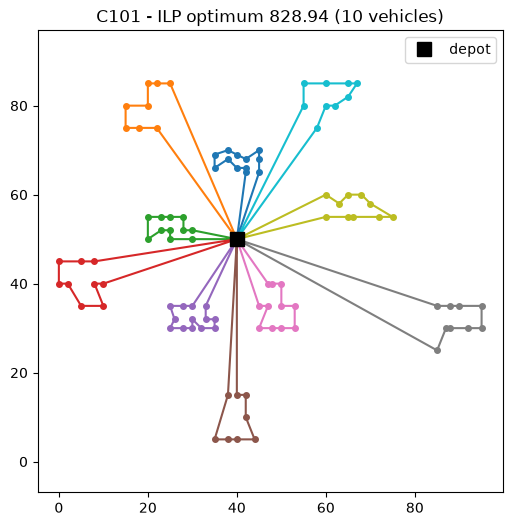

In [3]:
ilp_inst = ilp_load("data/C101.txt")
prob, x = build_ilp(ilp_inst)
print(f"{len(x)} arc variables (out of {ilp_inst['n'] * (ilp_inst['n'] + 1)}), {len(prob.constraints)} constraints")
status, cost, secs = solve_ilp(prob)
routes = ilp_routes(x)
feasible, dist = ilp_check(ilp_inst, routes)
print(f"status: {status} - distance {cost:.2f} with {len(routes)} vehicles - {secs:.1f} s")
print(f"independent check: {'feasible' if feasible else 'INFEASIBLE'}, recomputed distance {dist:.2f}")
ilp_plot(ilp_inst, routes, f"C101 - ILP optimum {cost:.2f} ({len(routes)} vehicles)")

### Lexicographic objective and effect of the big-M

Both experiments use the first 20 customers of RC101 (random + clustered customers, narrow windows), where the ILP is still solved to optimality.
- **Lexicographic:** step 1 minimises the number of vehicles $v^*$, step 2 minimises the distance with $\sum_j x_{0j} \le v^*$.
- **Big-M:** the same model with the tight M of section 5 and with $M = 10^5$. Both have the same integer solutions, so the same optimum; only the linear relaxation (lower bound) changes.

In [4]:
small = ilp_load("data/RC101.txt", n=20)

prob_v, _ = build_ilp(small, objective="vehicles")
status_v, v_star, _ = solve_ilp(prob_v)
prob_d, x_d = build_ilp(small, max_vehicles=round(v_star))
status_d, cost_d, _ = solve_ilp(prob_d)
prob_free, x_free = build_ilp(small)
status_f, cost_f, _ = solve_ilp(prob_free)
print(f"lexicographic: {round(v_star)} vehicles ({status_v}), then distance {cost_d:.2f} ({status_d})")
print(f"distance only: {len(ilp_routes(x_free))} vehicles, distance {cost_f:.2f} ({status_f})\n")

for mode in ("tight", "huge"):
    lp, _ = build_ilp(small, big_m=mode, relaxed=True)
    _, bound, _ = solve_ilp(lp)
    ip, _ = build_ilp(small, big_m=mode)
    status, opt, secs = solve_ilp(ip, time_limit=180)
    print(f"M {mode:5s}: LP relaxation {bound:7.2f} | ILP {opt:7.2f} ({status}) | "
          f"LP gap {100 * (opt - bound) / opt:4.1f} % | {secs:5.1f} s")

lexicographic: 4 vehicles (Optimal Solution Found), then distance 383.28 (Optimal Solution Found)
distance only: 4 vehicles, distance 383.28 (Optimal Solution Found)

M tight: LP relaxation  312.91 | ILP  383.28 (Optimal Solution Found) | LP gap 18.4 % |   1.0 s
M huge : LP relaxation  305.38 | ILP  383.28 (Optimal Solution Found) | LP gap 20.3 % |   0.6 s


**Results.** The independent check confirms the ILP solution of C101: 828.94 with 10 vehicles, the value of the reference solution. On RC101-20, the distance-optimal solution already uses the minimal fleet, so the lexicographic approach gives the same routes. The tight big-M gives a better lower bound (LP gap 18.4 % vs 20.3 %), with the same optimum; at this size both versions are solved in about one second, so the running times are not significant. The bound gap grows with $n$, and on larger instances the huge-M version can stop at its time limit without proving optimality.

## Solution

### 1. Uses of the exact approach

The ILP above is solved with the branch and bound of CBC, through PuLP. Because the CVRPTW is NP-hard, it cannot handle the instances of several thousand customers targeted by the project. It is still useful in four ways.

- **Direct solution of small instances.** When the solver finishes, it returns a **proven optimal** solution. This works for small instances, and for larger ones when the time windows leave little choice. C101, with clustered customers and tight windows, is solved to optimality with its 100 customers. On harder instances, with random customers or wider windows, CBC solves this formulation comfortably only up to about 20 to 30 customers. Beyond that, the solving time explodes.
- **Benchmark for the heuristic.** On every instance the ILP solves, its optimum is the exact reference against which we measure the ALNS: $\text{gap} = 100\,(f_{ALNS} - f^*)/f^*$. On C101, the ALNS reaches the ILP optimum (828.94).
- **Lower bounds.** The **linear relaxation** of the model (with $x_{ij} \in [0,1]$) gives a lower bound on the optimum, $f_{LP} \le f^*$. When the solver stops at its time limit, it still returns its best bound. Either bound lets us say how far a heuristic solution is from the optimum *at most*, even when the optimum itself is unknown. The tighter the big-M values, the closer this bound is to $f^*$.
- **Upper bounds.** Every feasible solution found during the search, by the solver or by the ALNS, is an upper bound $f^* \le f$. A good ALNS solution could also be given to the solver as a starting point, so that it prunes more branches.

The same model also handles a **lexicographic objective**: first minimise the number of vehicles $\sum_j x_{0j}$, then minimise the distance subject to $\sum_j x_{0j} \le v^*$. This is how the Solomon literature ranks solutions.

For the large instances, we therefore need a method that finds good feasible solutions in a limited time, without any proof of optimality: a **metaheuristic**.

### 2. Choice of the metaheuristic: ALNS

We use the **Adaptive Large Neighbourhood Search** (ALNS) of Ropke & Pisinger (2006), which is among the most effective methods for vehicle routing problems with time windows.

**Why large moves.** A classic local search changes a solution only slightly, for example by moving one customer or swapping two. On the CVRPTW, most of these small moves are infeasible, because shifting one customer delays all the following ones and breaks their time windows. The search then gets stuck in a local optimum very quickly. The **Large Neighbourhood Search** (Shaw, 1998) makes much larger moves: it *destroys* part of the solution by removing 5 to 30 % of the customers, then *repairs* it by inserting them back. A single move can change both the assignment of customers to vehicles and the order of visits in several routes at once.

**Why adaptive.** There are many ways to destroy and to repair, and none is the best on every instance or at every stage of the search. ALNS keeps several operators and learns during the run which ones work best on the instance being solved.

**Why it fits our constraints.** The repair step inserts a customer only where capacity and time windows still hold. Every solution the algorithm visits therefore respects capacity and time windows. It may leave some customers unserved (the set $U$ below), which the objective penalises, but no penalty for violated capacity or time windows has to be tuned.

### 3. Definition of a solution

A solution $s$ is a set of routes plus a set of customers that are not served yet:

$$
s = \big(\{R_1, \dots, R_m\},\ U\big), \qquad R_k = (0, i_1, \dots, i_r, 0), \qquad m \le \lvert K\rvert
$$

Each customer of $N$ belongs to exactly one route or to $U$. Each route satisfies the capacity constraint $\sum_{i \in R_k} d_i \le Q$, the time windows and the depot deadline $e_0$. The routes are stored as Python lists of customers, without the depot.

**Objective function.**

$$
f(s) = \sum_{k=1}^{m} \sum_{(i,j) \in R_k} c_{ij} \;+\; \alpha\, m \;+\; \beta\, \lvert U\rvert
$$

- The first term is the total travel time, the quantity we minimise.
- $\alpha$ is a fixed cost per vehicle. It is $0$ by default; a large value (e.g. 1000) makes the search minimise the number of vehicles first.
- $\beta = 10^4$ penalises each customer that could not be inserted. It is larger than any possible saving in distance, so a solution that serves everyone always beats one that does not. The final solution has $U = \emptyset$.

**Initial solution.** We apply a repair operator (regret-2, defined below) to the empty solution $s_0 = (\emptyset, N)$. The same code builds the initial solution and repairs it during the search.

### 4. Feasibility of an insertion

Repair operators test thousands of insertions, so each test must be fast. For each route $(0, c_1, \dots, c_r, 0)$, we store two values at each stop $k$ (Savelsbergh, 1992):

- the **earliest start of service**, computed forwards: $T_k = \max\big(b_{c_k},\ T_{k-1} + s_{c_{k-1}} + \tau_{c_{k-1} c_k}\big)$;
- the **latest start of service** that keeps all later stops on time, computed backwards: $L_k = \min\big(e_{c_k},\ L_{k+1} - \tau_{c_k c_{k+1}} - s_{c_k}\big)$, with $L_{r+1} = e_0$.

Inserting customer $u$ between two consecutive stops $i$ and $j$ is feasible if and only if:

1. **capacity:** $\text{load}(R) + d_u \le Q$;
2. **$u$ is on time:** $T_u = \max(b_u,\ T_i + s_i + \tau_{iu}) \le e_u$;
3. **nobody after $u$ is late:** $\max(b_j,\ T_u + s_u + \tau_{uj}) \le L_j$.

Each test costs $O(1)$ per position, instead of re-simulating the whole route. The cost of the insertion is the detour $\Delta_{u,ij} = c_{iu} + c_{uj} - c_{ij}$.

### 5. Neighbourhood structure: destroy operators

A destroy operator removes $q$ customers from the current solution and puts them in $U$. At each iteration, $q$ is drawn at random between $5\,\%$ and $30\,\%$ of $n$, capped at 40, so the size of the moves varies. The neighbourhood of $s$ is the set of solutions obtained by one destroy step followed by one repair step.

| Operator | Customers removed | Role |
|---|---|---|
| **Random** | $q$ customers chosen uniformly | diversification |
| **Worst** | the customers whose removal saves the most distance, $c_{p u} + c_{u n} - c_{p n}$, where $p$ and $n$ are the stops before and after $u$ | moves badly placed customers |
| **Shaw (related)** | a random seed customer, then customers similar to those already removed | similar customers can be swapped between routes |
| **Route** | one whole route, short routes being more likely | lets the repair rebuild the solution with one vehicle fewer |

**Relatedness** (Shaw removal). Two customers are similar when they are close, open their windows at similar times and have similar demands:

$$
R(i,j) = 9\,\frac{c_{ij}}{\max c} + 3\,\frac{\lvert b_i - b_j\rvert}{e_0} + 2\,\frac{\lvert d_i - d_j\rvert}{\max d}
$$

A smaller value means more related. The weights 9, 3 and 2 come from Ropke & Pisinger (2006).

**Controlled randomness** (Worst and Shaw). The candidates are sorted from best to worst, and the one at index $\lfloor y^p \cdot \lvert L\rvert\rfloor$ is chosen, where $L$ is the sorted list of candidates and $y$ is uniform in $[0, 1)$. A large exponent $p$ almost always picks the first candidate, while $p = 1$ picks uniformly. We use $p = 3$ for Worst and $p = 6$ for Shaw.

### 6. Repair operators

All repair operators repeat the same step: pick a customer of $U$ and insert it at its cheapest feasible position. A new empty route is also offered as long as fewer than $\lvert K\rvert$ vehicles are used. The operators differ only in **which customer is inserted next**:

| Operator | Next customer inserted |
|---|---|
| **Greedy** | the customer with the cheapest insertion $\min_u c_{u,1}$, where $c_{u,h}$ is the cost of inserting $u$ in its $h$-th best route |
| **Greedy with noise** | the same, with a random noise of $\pm 2.5\,\%$ of the largest distance added to each cost |
| **Regret-2** | the customer with the largest regret $c_{u,2} - c_{u,1}$ |
| **Regret-3** | the customer with the largest regret $\sum_{h=2}^{3} (c_{u,h} - c_{u,1})$ |

The **regret** measures how much more a customer will cost if we do not insert it now in its best route. Regret operators therefore insert the "difficult" customers first, those with few good positions left, and keep the easy ones for the end. A customer that fits in only one route gets the highest priority. The noise in the greedy operator lets it build different solutions from the same partial solution.

### 7. Guidance mechanisms

**Adaptive operator selection.** Each destroy and repair operator $o$ has a weight $w_o$, initialised to 1. At each iteration, one destroy and one repair operator are drawn independently by **roulette wheel**:

$$
P(o) = \frac{w_o}{\sum_{o'} w_{o'}}
$$

The chosen pair receives a score $\psi$ depending on the outcome of the iteration:

| Outcome | Score $\psi$ |
|---|---|
| new best solution | $\sigma_1 = 33$ |
| better than the current solution | $\sigma_2 = 9$ |
| strictly worse, but accepted | $\sigma_3 = 13$ |
| same cost as the current solution (accepted) | $0$ |
| rejected | $0$ |

A strictly worse but accepted solution scores more than an improving one ($\sigma_3 > \sigma_2$). This rewards operators that help the search leave a local optimum. A candidate with **the same cost** as the current solution is accepted, so the search can move along a plateau, but it scores 0: it is usually the same solution rebuilt, and rewarding it with $\sigma_3$ would favour the operators that change nothing. Ropke & Pisinger (2006) reach the same goal by rewarding only solutions never visited before.

Every segment of $L = 100$ iterations, the weights are updated with a reaction factor $\rho = 0.1$:

$$
w_o \leftarrow \max\!\Big(0.05,\ (1 - \rho)\, w_o + \rho\, \frac{\pi_o}{\theta_o}\Big)
$$

Here $\pi_o$ is the total score of $o$ during the segment and $\theta_o$ the number of times it was used. Operators that produce good solutions are chosen more and more often. The floor of $0.05$ keeps every operator in play.

**Acceptance: simulated annealing.** A candidate $s'$ always replaces the current solution $s$ if $f(s') < f(s)$. Otherwise it is accepted with probability

$$
P(\text{accept}) = e^{-(f(s') - f(s)) / T}
$$

- The **initial temperature** $T_0$ is set so that a solution $5\,\%$ longer than the initial solution is accepted with probability $0.5$: $T_0 = -0.05\, d(s_0) / \ln 0.5$, where $d(s_0)$ is the **distance** of the initial solution. We do not use $f(s_0)$: when the initial solution leaves customers unserved, $f(s_0)$ contains penalties of $10^4$ each, and $T_0$ would be far too large for the distance scale.
- The temperature then decreases geometrically, $T \leftarrow \gamma\, T$, with $\gamma$ chosen so that $T$ reaches $10^{-4}\, T_0$ at the last iteration.

At the start, many worse solutions are accepted, which favours exploration. At the end, almost only improvements are accepted, which favours intensification. The best solution ever found is stored separately and returned at the end.

**Stopping criterion.** A fixed number of iterations, with an optional time limit. The default of the code is 5000 iterations (`DEFAULT_PARAMS`); the experimental study uses 2000 iterations as its reference budget, and also 500 and 1000.

### 8. Parameters

| Parameter | Value | Role |
|---|---|---|
| iterations | 5000 (2000 in the study) | stopping criterion |
| $q$ | between 5 % and 30 % of $n$, at most 40 | size of the destroy step |
| $p_{\text{worst}}$, $p_{\text{Shaw}}$ | 3, 6 | randomness of Worst and Shaw removal |
| noise | 0.025 | amplitude of the noise in greedy with noise |
| $\sigma_1, \sigma_2, \sigma_3$ | 33, 9, 13 | operator scores |
| $\rho$, $L$ | 0.1, 100 | weight update |
| $T_0$ | 5 % longer than $d(s_0)$ accepted with probability 0.5 | initial temperature |
| $T_{\text{end}}$ | $10^{-4}\, T_0$ | final temperature |
| $\alpha$, $\beta$ | 0, $10^4$ | cost per vehicle, penalty per unserved customer |

Most values come from Ropke & Pisinger (2006). They are natural factors to vary in the experimental study.


# **Implementation**

## Pseudo-Code

The algorithm described in the Solution section is written below in pseudo-code. $f$ is the objective function, $D$ and $R$ are the sets of destroy and repair operators, and $\psi$ is the score of an iteration.

**Main loop**

```
ALNS(instance, N_iter):
    s      ← REPAIR_REGRET2( (∅, N) )             # initial solution: repair the empty solution
    s_best ← s
    T      ← -0.05 · d(s) / ln(0.5)               # d = distance: a 5 % longer solution is accepted with prob. 0.5
    γ      ← (10^-4)^(1 / N_iter)                 # cooling rate: T reaches 10^-4 · T0 at the end
    w_o ← 1,  π_o ← 0,  θ_o ← 0   for every operator o ∈ D ∪ R

    for it = 1 .. N_iter:
        d ← ROULETTE(D, w)                         # P(o) = w_o / Σ w
        r ← ROULETTE(R, w)
        s' ← r( d(s) )                             # destroy q customers, then re-insert them

        if f(s') < f(s_best):                      # new best solution
            s_best ← s' ;  s ← s' ;  ψ ← σ1
        else if f(s') < f(s):                      # improves the current solution
            s ← s' ;  ψ ← σ2
        else if f(s') = f(s):                      # same cost: accepted, not rewarded
            s ← s' ;  ψ ← 0
        else if RANDOM() < exp( -(f(s') - f(s)) / T ):   # strictly worse, accepted by simulated annealing
            s ← s' ;  ψ ← σ3
        else:
            ψ ← 0                                  # rejected

        π_d ← π_d + ψ ;  π_r ← π_r + ψ ;  θ_d ← θ_d + 1 ;  θ_r ← θ_r + 1
        T ← γ · T

        if it mod L = 0:                           # end of a segment: update the weights
            for every operator o used in the segment:
                w_o ← max(0.05, (1 - ρ) · w_o + ρ · π_o / θ_o)
            π ← 0 ;  θ ← 0

    return s_best
```

**Repair (shared by the four repair operators)**

```
REPAIR(s = (routes, U), k):                        # k = 1: greedy, k = 2 or 3: regret-k
    for every u ∈ U and every route R (plus one empty route if m < |K|):
        c[u, R] ← cheapest feasible insertion cost of u in R   (∞ if none)

    while U ≠ ∅ and some c[u, R] < ∞:
        if k = 1:  u* ← argmin_u  min_R c[u, R]
        else:      u* ← argmax_u  Σ_{h=2..k} ( c_{u,h} - c_{u,1} )   # c_{u,h}: h-th best route of u
        insert u* at its cheapest feasible position, in its best route R*
        U ← U \ {u*}
        recompute the column c[·, R*] only             # the other routes did not change

    return (routes, U)                             # customers left in U are penalised by β
```

**Insertion test of customer $u$ between consecutive stops $i$ and $j$**

```
FEASIBLE(R, u, i, j):
    if load(R) + d_u > Q:                         return false     # capacity
    T_u ← max(b_u, T_i + s_i + τ_iu)
    if T_u > e_u:                                 return false     # u is late
    if max(b_j, T_u + s_u + τ_uj) > L_j:          return false     # a later stop becomes late
    return true
```

## Different stages

The program runs in five stages.

**Stage 1: reading the instance.** `load_instance` reads the file with `vrplib` and turns it into numpy arrays: coordinates, demands $d_i$, time windows $[b_i, e_i]$, service times $s_i$ (with $s_0 = 0$), capacity $Q$ and fleet size $\lvert K\rvert$. It then precomputes the two $(n+1) \times (n+1)$ matrices used by the search:
- the exact Euclidean distances $c_{ij} = \tau_{ij}$;
- the relatedness $R(i,j)$ used by the Shaw removal.

Both cost $O(n^2)$ time and memory, once.

**Stage 2: data structures.**
- A **`Solution`** stores its routes as lists of customers, without the depot, and the list $U$ of unserved customers. It computes $f(s)$.
- A **`RouteData`** wraps one route with its cache: load, earliest starts $T_k$ (forward pass) and latest starts $L_k$ (backward pass). The cache is rebuilt in $O(r)$ after each change to the route. In return, `best_insertion` tests **all the positions of the route at once** with numpy vector operations, using the three conditions of the insertion test.

**Stage 3: initial solution.** Regret-2 repair applied to the empty solution: all customers start in $U$ and are inserted one by one.

**Stage 4: main loop.** Each iteration:
1. draws a destroy and a repair operator by roulette wheel;
2. destroys $q$ customers, then repairs. The repair dominates the cost of an iteration. Building the cost matrix tests every removed customer at every position, $O(q \cdot n)$ in total. Each insertion then recomputes only the column of the modified route;
3. evaluates $f(s')$ and applies the acceptance rule;
4. updates the scores, cools the temperature, and every $L = 100$ iterations updates the weights.

The search is **seeded** (`numpy.random.default_rng(seed)`), so a run can be reproduced exactly.

**Stage 5: checking and output.** `check_solution` recomputes the cost of the best solution **from scratch**, without reusing any code from the algorithm. It verifies that each customer is visited exactly once, the fleet size, the capacities, every time window and the return to the depot. If the ALNS had a bug in its fast insertion test, this independent check would detect it. The function `alns` returns the best solution and a history (current and best cost at each iteration, operator weights, runtime) used in the experimental study.

## Implementation

The code uses only `numpy`, `pandas`, `matplotlib` and `vrplib` (plus `pulp` for the ILP and `scipy` / `statsmodels` for the statistics of the study). The instance files are in the `data/` folder of the project.

**Optimisations of the implementation.**
- **Vectorisation (numpy).** The distance and relatedness matrices are built in one broadcast operation, and `best_insertion` tests every position of a route at once instead of looping over positions in Python. The savings of the worst removal are also computed for a whole route at once.
- **Memoisation.** Values that are expensive and reused are computed once and kept: the distance and relatedness matrices (once per instance), the forward and backward passes of each route (`RouteData`, rebuilt only when the route changes), and the matrix of insertion costs of the repair, where only the column of the modified route is recomputed after an insertion.
- **Comprehensions and sets.** Routes are rebuilt with list comprehensions, and the customers to remove are kept in a `set`, so each membership test costs $O(1)$ instead of $O(q)$.
- **Cache of the experiments.** Every run of the study is saved in `results/` and reloaded, so rerunning the notebook does not recompute the 3 700 runs.


### Imports

In [5]:
import time                      # standard library, only used to measure runtimes
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import vrplib

DATA_DIR = "data"

### Stage 1: reading an instance

Node 0 is the depot and nodes $1..n$ are the customers. The relatedness matrix of the Shaw removal is precomputed here. `load_bks` reads a `.sol` file and recomputes its cost with our distances.

In [6]:
def load_instance(path):
    # Solomon files (.txt) need the "solomon" format; .vrptw / .vrp files use the default VRPLIB format
    fmt = "solomon" if path.lower().endswith(".txt") else "vrplib"
    raw = vrplib.read_instance(path, instance_format=fmt)

    n_nodes = len(raw["demand"])          # depot + customers

    # Service time can be given per node (Solomon) or as a single number (.vrptw): we always build an array
    service = np.broadcast_to(np.asarray(raw["service_time"], dtype=float), (n_nodes,)).copy()
    service[0] = 0.0                      # no service at the depot

    # Exact Euclidean distances recomputed from the coordinates (same convention for every file format).
    # Travel time = distance, as in the Solomon benchmark.
    coords = np.asarray(raw["node_coord"], dtype=float)
    dist = np.sqrt(((coords[:, None, :] - coords[None, :, :]) ** 2).sum(axis=2))

    tw = np.asarray(raw["time_window"], dtype=float)
    inst = {
        "name": raw["name"],
        "coords": coords,
        "demand": np.asarray(raw["demand"], dtype=float),
        "capacity": float(raw["capacity"]),
        "n_vehicles": int(raw["vehicles"]),   # fleet size limit
        "ready": tw[:, 0],                    # e_i: earliest service start
        "due": tw[:, 1],                      # l_i: latest service start
        "service": service,                   # s_i
        "dist": dist,                         # d_ij (= travel time t_ij)
        "n_customers": n_nodes - 1,
    }

    # Relatedness between two customers for the Shaw removal (smaller = more similar).
    # Weighted sum of normalised distance, difference of time-window opening and difference of demand.
    # Weights 9 / 3 / 2 come from Ropke & Pisinger (2006).
    d_norm = dist / dist.max()
    t_norm = np.abs(inst["ready"][:, None] - inst["ready"][None, :]) / max(1.0, inst["due"][0])
    q_norm = np.abs(inst["demand"][:, None] - inst["demand"][None, :]) / max(1.0, inst["demand"].max())
    inst["relatedness"] = 9 * d_norm + 3 * t_norm + 2 * q_norm
    return inst


def load_bks(sol_path, inst):
    # Read a .sol file and recompute its cost with OUR distances, so that gaps are measured consistently
    sol = vrplib.read_solution(sol_path)
    d = inst["dist"]
    cost = sum(d[[0] + r, r + [0]].sum() for r in sol["routes"])
    return cost, len(sol["routes"])


inst = load_instance(f"{DATA_DIR}/C101.txt")
print(inst["name"], "|", inst["n_customers"], "customers |", inst["n_vehicles"], "vehicles of capacity", inst["capacity"])
print("Known-best solution (recomputed cost, routes):", load_bks(f"{DATA_DIR}/C101.sol", inst))

C101 | 100 customers | 25 vehicles of capacity 200.0
Known-best solution (recomputed cost, routes): (np.float64(828.9368669428341), 10)


### Stage 2: data structures and fast insertion test

`RouteData.update` runs the forward and backward passes; `best_insertion` applies the three conditions of the insertion test to every position of the route at once.

In [7]:
class RouteData:
    # One route, with the cached information needed to test insertions in O(1) per position

    def __init__(self, inst, customers):
        self.customers = list(customers)   # customers only, without the depot
        self.update(inst)

    def update(self, inst):
        # Recompute the cache after the route changed (forward and backward passes)
        d, s, e, l = inst["dist"], inst["service"], inst["ready"], inst["due"]
        seq = np.array([0] + self.customers + [0])   # full sequence with the depot at both ends
        m = len(seq)
        start = np.empty(m)
        latest = np.empty(m)

        # Forward pass: earliest service start at each stop (waiting is allowed if we arrive early)
        start[0] = e[0]
        for k in range(1, m):
            arrival = start[k - 1] + s[seq[k - 1]] + d[seq[k - 1], seq[k]]
            start[k] = max(arrival, e[seq[k]])

        # Backward pass: latest service start at each stop that keeps the rest of the route feasible
        latest[-1] = l[0]                           # must be back at the depot before it closes
        for k in range(m - 2, -1, -1):
            latest[k] = min(l[seq[k]], latest[k + 1] - d[seq[k], seq[k + 1]] - s[seq[k]])

        self.seq, self.start, self.latest = seq, start, latest
        self.load = inst["demand"][seq].sum()

    def best_insertion(self, inst, u):
        # Return (extra distance, position) of the cheapest FEASIBLE insertion of customer u,
        # or (inf, -1) if u cannot be inserted anywhere in this route
        if self.load + inst["demand"][u] > inst["capacity"]:          # condition 1: capacity
            return np.inf, -1

        d, s, e, l = inst["dist"], inst["service"], inst["ready"], inst["due"]
        prev, nxt = self.seq[:-1], self.seq[1:]   # all (i, j) pairs of consecutive stops, vectorised

        start_u = np.maximum(self.start[:-1] + s[prev] + d[prev, u], e[u])
        arrival_next = start_u + s[u] + d[u, nxt]
        feasible = (start_u <= l[u]) & (np.maximum(arrival_next, e[nxt]) <= self.latest[1:])  # conditions 2 and 3
        if not feasible.any():
            return np.inf, -1

        extra = d[prev, u] + d[u, nxt] - d[prev, nxt]   # detour created by the insertion
        extra = np.where(feasible, extra, np.inf)
        pos = int(np.argmin(extra))
        return float(extra[pos]), pos


class Solution:
    # A solution = list of routes (lists of customers) + list of customers not served yet

    def __init__(self, routes, unassigned):
        self.routes = [list(r) for r in routes if len(r) > 0]   # empty routes are dropped
        self.unassigned = list(unassigned)

    def copy(self):
        return Solution(self.routes, self.unassigned)

    def distance(self, inst):
        d = inst["dist"]
        return sum(d[[0] + r, r + [0]].sum() for r in self.routes)

    def objective(self, inst, params):
        # Total distance + optional fixed cost per vehicle + big penalty per unserved customer
        return (self.distance(inst)
                + params["vehicle_cost"] * len(self.routes)
                + params["unassigned_penalty"] * len(self.unassigned))

### Destroy operators

In [8]:
def removal_size(inst, rng, params):
    # Number of customers to remove: random between q_min and q_max
    n = inst["n_customers"]
    q_min = max(2, int(params["q_min_frac"] * n))
    q_max = max(q_min, min(params["q_max_abs"], int(params["q_max_frac"] * n)))
    return int(rng.integers(q_min, q_max + 1))


def remove_customers(sol, to_remove):
    # Build a new solution where the customers in to_remove are taken out of their routes
    to_remove = set(to_remove)
    routes = [[c for c in r if c not in to_remove] for r in sol.routes]
    return Solution(routes, sol.unassigned + list(to_remove))


def random_removal(sol, inst, rng, params):
    customers = [c for r in sol.routes for c in r]
    q = min(removal_size(inst, rng, params), len(customers))
    return remove_customers(sol, rng.choice(customers, size=q, replace=False).tolist())


def worst_removal(sol, inst, rng, params):
    d = inst["dist"]
    q = removal_size(inst, rng, params)
    routes = [list(r) for r in sol.routes]
    removed = []
    while len(removed) < q:
        # Saving obtained by removing each customer: d(prev,c) + d(c,next) - d(prev,next)
        candidates, savings = [], []
        for r in routes:
            if not r:
                continue
            seq = np.array([0] + r + [0])
            g = d[seq[:-2], seq[1:-1]] + d[seq[1:-1], seq[2:]] - d[seq[:-2], seq[2:]]
            candidates.extend(r)
            savings.extend(g.tolist())
        if not candidates:
            break
        order = np.argsort(savings)[::-1]                              # biggest saving first
        chosen = candidates[order[int(rng.random() ** params["worst_p"] * len(order))]]
        removed.append(chosen)
        for r in routes:                                                # savings change after each removal,
            if chosen in r:                                             # so they are recomputed in the loop
                r.remove(chosen)
                break
    return Solution(routes, sol.unassigned + removed)


def shaw_removal(sol, inst, rng, params):
    R = inst["relatedness"]
    customers = [c for r in sol.routes for c in r]
    if not customers:
        return sol.copy()
    q = min(removal_size(inst, rng, params), len(customers))
    removed = [customers[rng.integers(len(customers))]]            # random seed customer
    remaining = set(customers) - set(removed)
    while len(removed) < q:
        ref = removed[rng.integers(len(removed))]                   # compare with a random removed customer
        rem = np.array(sorted(remaining))
        order = rem[np.argsort(R[ref, rem])]                        # most related first
        chosen = int(order[int(rng.random() ** params["shaw_p"] * len(order))])
        removed.append(chosen)
        remaining.discard(chosen)
    return remove_customers(sol, removed)


def route_removal(sol, inst, rng, params):
    if not sol.routes:
        return sol.copy()
    sizes = np.array([len(r) for r in sol.routes], dtype=float)
    prob = (1 / sizes) / (1 / sizes).sum()                          # small routes are more likely to be removed
    k = rng.choice(len(sol.routes), p=prob)
    return remove_customers(sol, sol.routes[k])

### Repair operators

The four repair operators share `insert_customers`; only the rule that picks the next customer changes (`k_regret`, `noise`).

In [9]:
def insert_customers(sol, inst, rng, params, k_regret=1, noise=False):
    routes = [RouteData(inst, r) for r in sol.routes]
    pending = list(sol.unassigned)
    rng.shuffle(pending)                                   # random tie-breaking
    noise_amp = params["noise"] * inst["dist"].max() if noise else 0.0

    def column(rd):
        # Cheapest insertion cost and position of every pending customer in route rd
        cost = np.empty(len(pending))
        pos = np.empty(len(pending), dtype=int)
        for i, u in enumerate(pending):
            cost[i], pos[i] = rd.best_insertion(inst, u)
        if noise_amp > 0:
            cost = np.maximum(0.0, cost + noise_amp * rng.uniform(-1, 1, len(pending)))
        return cost, pos

    def candidate_routes():
        # Existing routes + one empty route if another vehicle is still available
        return routes + ([RouteData(inst, [])] if len(routes) < inst["n_vehicles"] else [])

    cand = candidate_routes()
    cost = np.empty((len(pending), len(cand)))
    posm = np.empty((len(pending), len(cand)), dtype=int)
    for j, rd in enumerate(cand):
        cost[:, j], posm[:, j] = column(rd)
    cost[:, len(routes):] += params["vehicle_cost"]       # opening a new route has a fixed cost

    while pending:
        best = cost.min(axis=1)                            # best insertion cost of each pending customer
        if np.all(np.isinf(best)):
            break                                          # nobody can be inserted anymore

        # ---- choose which customer to insert ----
        if k_regret <= 1:
            i = int(np.argmin(best))                       # greedy
        else:
            big = 1e9                                      # infeasible routes count as very expensive
            sorted_cost = np.sort(np.where(np.isinf(cost), big, cost), axis=1)
            kk = min(k_regret, sorted_cost.shape[1])
            if kk > 1:
                regret = (sorted_cost[:, 1:kk] - sorted_cost[:, [0]]).sum(axis=1)
            else:
                regret = np.zeros(len(pending))
            regret = np.where(np.isinf(best), -np.inf, regret)   # never pick a customer that fits nowhere
            ties = np.flatnonzero(regret == regret.max())
            i = int(ties[np.argmin(best[ties])])           # tie-break on the cheapest insertion

        # ---- insert it in its best route at its best position ----
        j = int(np.argmin(cost[i]))
        rd = cand[j]
        rd.customers.insert(posm[i, j], pending[i])
        rd.update(inst)
        opened_new_route = j >= len(routes)
        if opened_new_route:
            routes.append(rd)

        pending.pop(i)
        cost = np.delete(cost, i, axis=0)
        posm = np.delete(posm, i, axis=0)
        if not pending:
            break

        # ---- update the cost matrix: only the modified route changed ----
        cost[:, j], posm[:, j] = column(rd)
        if opened_new_route:
            cost, posm = cost[:, :len(routes)], posm[:, :len(routes)]
            cand = candidate_routes()
            if len(cand) > len(routes):                    # offer a new empty route again
                c, p = column(cand[-1])
                cost = np.column_stack([cost, c + params["vehicle_cost"]])
                posm = np.column_stack([posm, p])

    return Solution([rd.customers for rd in routes], pending)


def greedy_repair(sol, inst, rng, params):
    return insert_customers(sol, inst, rng, params, k_regret=1)

def greedy_noise_repair(sol, inst, rng, params):
    return insert_customers(sol, inst, rng, params, k_regret=1, noise=True)

def regret2_repair(sol, inst, rng, params):
    return insert_customers(sol, inst, rng, params, k_regret=2)

def regret3_repair(sol, inst, rng, params):
    return insert_customers(sol, inst, rng, params, k_regret=3)


DESTROY = [random_removal, worst_removal, shaw_removal, route_removal]
REPAIR = [greedy_repair, greedy_noise_repair, regret2_repair, regret3_repair]

### Stage 5: independent solution checker

In [10]:
def check_solution(inst, routes):
    # Return (total distance, list of errors). An empty error list means the solution is feasible.
    d, s, e, l, q = inst["dist"], inst["service"], inst["ready"], inst["due"], inst["demand"]
    errors = []

    # Coverage: a customer served twice (or an unknown node) is a violation; an unserved customer is only
    # an incomplete solution, penalised in the objective. The two cases get different messages
    n = inst["n_customers"]
    visited = np.array([c for r in routes for c in r], dtype=int)
    if np.any((visited < 1) | (visited > n)):
        errors.append("route contains the depot or an unknown node")
    count = np.bincount(visited.clip(0, n), minlength=n + 1)[1:]
    if (count > 1).any():
        errors.append(f"customers served more than once: {(np.flatnonzero(count > 1) + 1).tolist()}")
    if (count == 0).any():
        errors.append(f"{int((count == 0).sum())} customers not served")
    if len(routes) > inst["n_vehicles"]:
        errors.append("too many vehicles")

    total = 0.0
    for k, r in enumerate(routes):
        if q[r].sum() > inst["capacity"] + 1e-9:
            errors.append(f"route {k}: capacity exceeded")
        t, prev = e[0], 0
        for c in r + [0]:                                  # simulate the route, back to the depot
            t = max(t + s[prev] + d[prev, c], e[c])        # wait if early
            if t > l[c] + 1e-9:
                errors.append(f"route {k}: late at node {c}")
                break
            total += d[prev, c]
            prev = c
    return total, errors


# Self-check: a duplicate and a missing customer give two different errors
_inst = load_instance(f"{DATA_DIR}/C101.txt")
_, _err = check_solution(_inst, [[1, 2, 1]] + [[c] for c in range(4, 101)])
assert any("more than once" in e for e in _err) and any(e == "1 customers not served" for e in _err), _err



### Stages 3 and 4: the ALNS main loop

All parameters are gathered in `DEFAULT_PARAMS` (see the parameter table of the Solution section) and can be overridden in a call, e.g. `alns(inst, iterations=1000, seed=2)`.

In [11]:
DEFAULT_PARAMS = dict(
    iterations=5000, time_limit=None, seed=0,
    q_min_frac=0.05, q_max_frac=0.30, q_max_abs=40,
    worst_p=3, shaw_p=6, noise=0.025,
    vehicle_cost=0.0, unassigned_penalty=1e4,
    sigma1=33, sigma2=9, sigma3=13, reaction=0.1, segment=100,
    start_worse=0.05, start_accept=0.5, end_temp_frac=1e-4,
)


def alns(inst, **overrides):
    params = {**DEFAULT_PARAMS, **overrides}
    rng = np.random.default_rng(params["seed"])            # seeded -> reproducible runs
    t0 = time.perf_counter()

    # ---- Step 3: initial solution = repair an empty solution ----
    empty = Solution([], range(1, inst["n_customers"] + 1))
    current = regret2_repair(empty, inst, rng, params)
    f_current = current.objective(inst, params)
    best, f_best = current.copy(), f_current

    # ---- Step 7: simulated annealing temperature ----
    # T0 is computed on the distance of the initial solution, not on f: the penalty of the unserved customers
    # would otherwise make T0 far too large for the distance scale
    T = -params["start_worse"] * current.distance(inst) / np.log(params["start_accept"])
    cooling = params["end_temp_frac"] ** (1.0 / params["iterations"])   # reach T0 * end_temp_frac at the end

    # ---- Step 6: adaptive weights, scores and usage counters ----
    nD, nR = len(DESTROY), len(REPAIR)
    wD, wR = np.ones(nD), np.ones(nR)
    scoreD, scoreR = np.zeros(nD), np.zeros(nR)
    usedD, usedR = np.zeros(nD), np.zeros(nR)
    history = {"current": [], "best": [], "wD": [wD.copy()], "wR": [wR.copy()], "initial": f_current}

    for it in range(params["iterations"]):
        if params["time_limit"] and time.perf_counter() - t0 > params["time_limit"]:
            break                                           # Step 8: optional time limit

        # Roulette-wheel selection of one destroy and one repair operator
        i = rng.choice(nD, p=wD / wD.sum())
        j = rng.choice(nR, p=wR / wR.sum())

        # Destroy then repair
        candidate = REPAIR[j](DESTROY[i](current, inst, rng, params), inst, rng, params)
        f_cand = candidate.objective(inst, params)

        # Acceptance + score of the operator pair
        score = 0
        if f_cand < f_best - 1e-9:                          # new global best
            best, f_best = candidate.copy(), f_cand
            current, f_current = candidate, f_cand
            score = params["sigma1"]
        elif f_cand < f_current - 1e-9:                     # improves the current solution
            current, f_current = candidate, f_cand
            score = params["sigma2"]
        elif f_cand <= f_current + 1e-9:                    # same cost: accepted, but not rewarded
            current, f_current = candidate, f_cand
        elif rng.random() < np.exp(-(f_cand - f_current) / T):   # strictly worse but accepted (SA rule)
            current, f_current = candidate, f_cand
            score = params["sigma3"]

        scoreD[i] += score; scoreR[j] += score
        usedD[i] += 1;      usedR[j] += 1
        T *= cooling
        history["current"].append(f_current)
        history["best"].append(f_best)

        # End of a segment: update the weights  w <- (1 - r) w + r * score / uses
        if (it + 1) % params["segment"] == 0:
            r = params["reaction"]
            wD = np.where(usedD > 0, (1 - r) * wD + r * scoreD / np.maximum(usedD, 1), wD)
            wR = np.where(usedR > 0, (1 - r) * wR + r * scoreR / np.maximum(usedR, 1), wR)
            wD, wR = np.maximum(wD, 0.05), np.maximum(wR, 0.05)   # never let an operator disappear completely
            scoreD[:] = scoreR[:] = usedD[:] = usedR[:] = 0
            history["wD"].append(wD.copy())
            history["wR"].append(wR.copy())

    history["runtime"] = time.perf_counter() - t0
    return best, history

def plot_route(inst, routes, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(20,20))
    coords = inst["coords"]
    ax.scatter(coords[1:, 0], coords[1:, 1], c="blue", label="customers")
    ax.scatter(coords[0, 0], coords[0, 1], c="red", label="depot")
    for k, r in enumerate(routes):
        seq = [0] + r + [0]
        ax.plot(coords[seq, 0], coords[seq, 1], label=f"route {k}")
    ax.set_title(f"{inst['name']} - {len(routes)} routes")
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.plot(*coords[0], marker="*", markersize=20, c="red")  # depot
    ax.legend()
    plt.show()


## Test

ALNS solution is feasible: (np.float64(828.9368669428343), [])


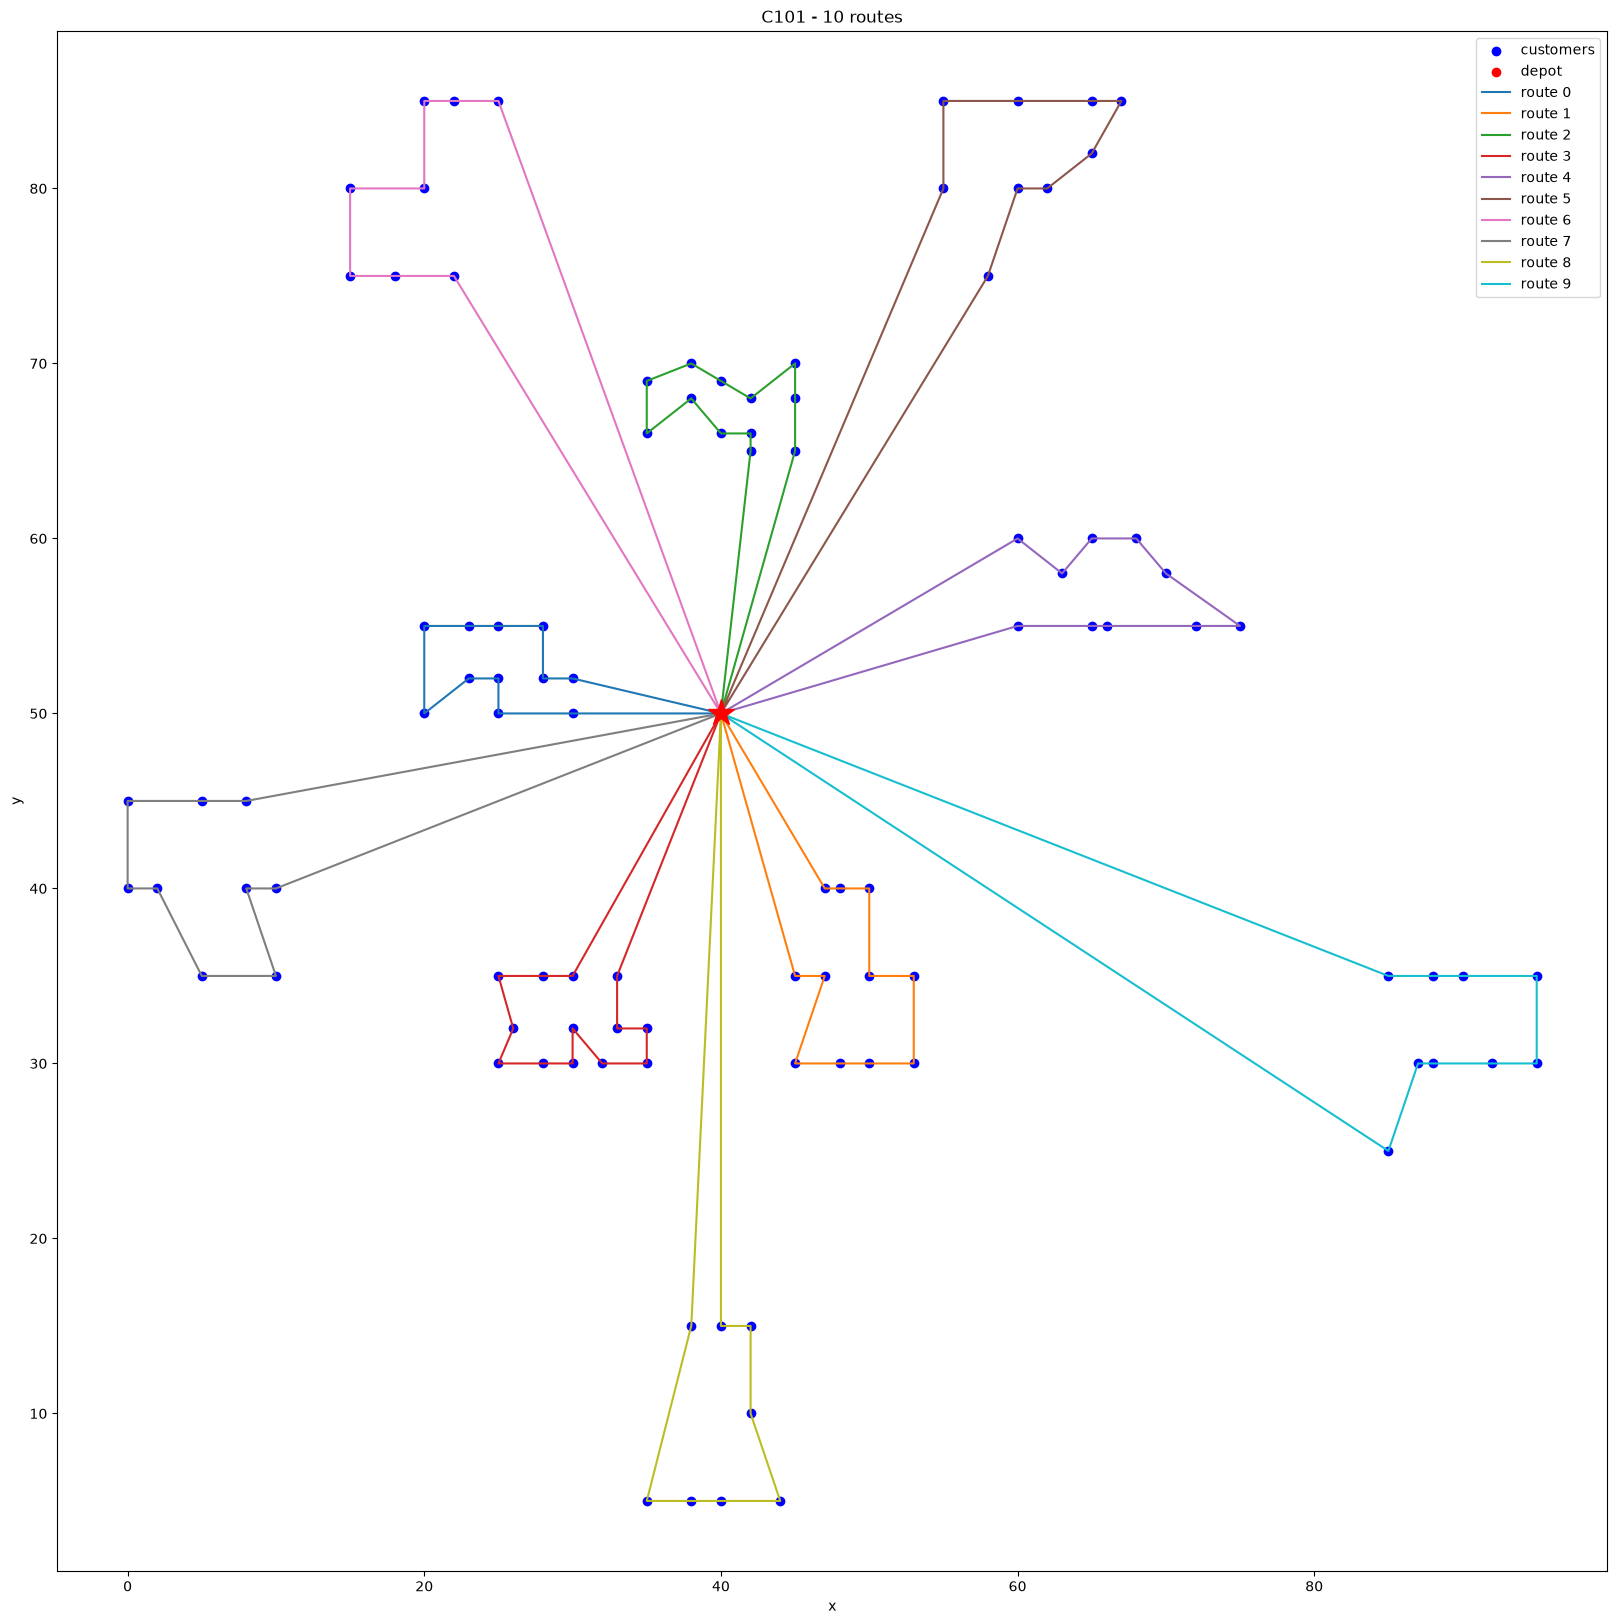

In [12]:
#first try 
inst = load_instance(f"{DATA_DIR}/C101.txt")
alns_solution, alns_history = alns(inst, iterations=2000, seed=0, vehicle_cost=0.0, unassigned_penalty=1e4)
print("ALNS solution is feasible:", check_solution(inst, alns_solution.routes))  # check feasibility
#print("ALNS solution: distance =", alns_solution.distance(inst), ", #vehicles =", len(alns_solution.routes))
#print(alns_solution.routes)
plot_route(inst, alns_solution.routes)

# **Experimental Study**



## Research questions

The questions below were fixed before running the experiments. Each one is answered by one experiment.

| | Question | Experiment |
|---|---|---|
| RQ1 | Which degree of destruction $q$ and which initial temperature $w$ should the ALNS use, and do they interact? | **T** (tuning) |
| RQ2 | How far from the best known solutions is the ALNS, for several iteration budgets, and does the tuned setting beat the default one at equal budget? | **B** (benchmark and budgets) |
| RQ3 | What does each destroy / repair operator contribute, and is the adaptive selection useful? | **A1** (ablation) |
| RQ4 | How do the operator weights evolve, and do they differ between clustered, random and mixed instances? | **A2** (weights) |
| RQ5 | What do the time windows and the limited fleet cost, in distance and in CO$_2$? | **C** (cost of the constraints) |
| RQ6 | How does the time per iteration grow with the number of customers, up to 1000? | **S** (scalability) |

## Environment and code version

In [13]:
import math, os, platform, subprocess, warnings
import importlib.metadata as metadata
import scipy
from scipy import stats
from statsmodels.stats.multitest import multipletests

def git(*args):
    try:
        return subprocess.run(["git", *args], capture_output=True, text=True).stdout.strip()
    except OSError:
        return "unknown"

environment = {"OS": platform.platform(), "CPU": platform.processor(), "logical cores": os.cpu_count(),
               "Python": platform.python_version(),
               **{p: metadata.version(p) for p in ("numpy", "pandas", "scipy", "statsmodels", "matplotlib", "vrplib")},
               "git commit": git("rev-parse", "--short", "HEAD"), "git branch": git("rev-parse", "--abbrev-ref", "HEAD")}
pd.DataFrame({"value": environment})

,value
OS,Windows-11-10.0.26300-SP0
CPU,"Intel64 Family 6 Model 186 Stepping 3, Genuine..."
logical cores,12
Python,3.14.3
numpy,2.5.3
pandas,3.0.6
scipy,1.18.1
statsmodels,0.15.0
matplotlib,3.11.2
vrplib,2.2.0


## Protocol

**Algorithm.** All runs use `alns_exp`, a copy of `alns`; the original is left unchanged. With the same seed and parameters, `alns_exp` returns exactly the same solution (checked below). It only adds the choice of the operators allowed (for A1), $T_0 = 0$ for pure hill climbing (for T), relaxed instances (for C) and extra logs.

**Instances and tuning / test split** (table below).
- *Tuning set*: C101 (100 customers) and C1_2_1 (200, Gehring & Homberger). The parameters $q$ and $w$ are chosen on these two instances only (experiment T).
- *Test set* (18 instances): C102, C103, C201, C202 (clustered), R101, R102, R105, R109, R201, R202, R211 (random), RC101, RC103, RC105, RC108, RC201, RC202 (mixed), all with 100 customers, in series 1 (short horizon, many short routes) and series 2 (long horizon, few long routes), and C1_10_1 (1000 customers). Every conclusion about quality is drawn on these instances, which were not used for tuning. With the tuning set, the study has **20 instances with a reference solution**.
- *Scalability only*: C101-25 and C101-50, the first 25 and 50 customers of C101, and C1_4_1, C1_6_1, C1_8_1 (400, 600 and 800 customers, no reference solution).
- `C1_2_1.txt` is the same instance as `C1_2_1.200.20.vrptw`, but with 50 vehicles instead of 20. We use the version with 20 vehicles, the fleet of the best known solution.

**Quality indicator.** $\text{gap} = 100\,(f - f_{BKS}) / f_{BKS}$ (Eq. 1), where $f$ = distance $+\ 10^4 \times$ (number of unserved customers).
- The 17 Solomon instances (every 100-customer instance except C102): $f_{BKS}$ is the cost of the provided `.sol` file, recomputed with our distances. All these files give the best solutions for total distance, not for the number of vehicles. For R101 and RC101, these are the best solutions for **total distance** (20 and 15 routes). This is also our objective, whereas the SINTEF table ranks solutions by number of vehicles first.
- C102, C1_2_1 and C1_10_1: values from the SINTEF tables (828.94; 2704.57 with 20 vehicles; 42478.95 with 100 vehicles). The fleet limit of the file equals the number of vehicles of the BKS, so comparing distances is fair.
- A run that leaves customers unserved gets a very large gap: each unserved customer adds about 600 % on a 100-customer instance and 24 % on C1_10_1. The mean gap is therefore always reported with the median gap and the share of feasible runs.

**Distances.** Euclidean distances in double precision, without rounding (`EXACT_2D`), and travel time = distance. This is the convention of the Solomon / Gehring & Homberger benchmark used by SINTEF ("distance and time should be calculated with double precision"). The integer rounding of CVRPLIB applies to the CVRP instances, not to these ones. Gaps may be slightly negative (−0.0003 %) because SINTEF rounds its BKS to two decimals.

**Budget.** The budget is a number of iterations (one iteration = one destroy + one repair), so every variant gets the same number of evaluations. 2000 iterations is the reference budget: about 11 s for 100 customers and 2 min for 1000 customers on an idle machine (measured in S). Experiment B also uses 500, 1000 and 5000 iterations. The cooling factor is recomputed from the budget, so $T$ always reaches $10^{-4} T_0$ at the last iteration. A shorter budget is therefore a separate run, not the beginning of a longer one.

**Seeds.** 20 seeds (0 to 19) for every pair (instance, configuration), the same seeds everywhere. The same seed gives the same initial solution for every variant, so the comparisons are paired.

**Statistics.** Rank tests by default (`scipy.stats`):
- paired Wilcoxon signed-rank test for two configurations;
- Friedman test (blocked by seed) for $k$ configurations;
- Fisher exact test for success rates (feasible runs);
- Holm correction for multiple tests (`statsmodels`);
- Vargha–Delaney $A_{12}$ effect size (0.56 / 0.64 / 0.71 = small / medium / large);
- 95 % confidence interval of the mean gap (Student $t$).

**Runtime.** All the experiments were run from scratch with the final version of the algorithm (score 0 for a candidate of the same cost, $T_0$ computed on the distance). Experiments T, B, A1 and C were run with 11 processes in parallel on the machine described above, one thread each. Their times are inflated by this load (the factor is measured in the analysis of S), so they can only be compared with each other. Experiment S was rerun alone, in a single session, for all sizes. Each experiment saves its results in `results/` and reloads them the next time the notebook runs. Only the runs missing from the file are computed, so adding an instance does not rerun the others; delete a file to recompute everything.

In [14]:
# ---- Copy of alns() for the experimental study ----
# Same algorithm, same random draws. Additions:
#   destroy / repair : names of the operators allowed (ablation, single pair)
#   start_worse = 0  : T = 0, i.e. pure hill climbing
#   logs             : weights per operator name, new bests per operator, acceptance of worse candidates,
#                      iteration of the last improvement, initial solution, time spent on the initial solution
def alns_exp(inst, destroy=None, repair=None, **overrides):
    params = {**DEFAULT_PARAMS, **overrides}
    rng = np.random.default_rng(params["seed"])
    t0 = time.perf_counter()
    D = [f for f in DESTROY if destroy is None or f.__name__ in destroy]
    R = [f for f in REPAIR if repair is None or f.__name__ in repair]
    dnames, rnames = [f.__name__ for f in D], [f.__name__ for f in R]

    # Initial solution: always regret-2, even if regret-2 is removed from the pool (same start for every variant)
    empty = Solution([], range(1, inst["n_customers"] + 1))
    current = regret2_repair(empty, inst, rng, params)
    f_current = current.objective(inst, params)
    best, f_best = current.copy(), f_current
    t_init = time.perf_counter() - t0

    T = -params["start_worse"] * current.distance(inst) / np.log(params["start_accept"])   # on the distance, as in alns
    cooling = params["end_temp_frac"] ** (1.0 / params["iterations"])

    nD, nR = len(D), len(R)
    wD, wR = np.ones(nD), np.ones(nR)
    scoreD, scoreR = np.zeros(nD), np.zeros(nR)
    usedD, usedR = np.zeros(nD), np.zeros(nR)
    newD, newR = np.zeros(nD, int), np.zeros(nR, int)
    history = {"current": [], "best": [], "worse_acc": [], "initial": f_current, "t_init": t_init,
               "initial_dist": current.distance(inst), "initial_unassigned": len(current.unassigned),
               "wD": [dict(zip(dnames, wD))], "wR": [dict(zip(rnames, wR))], "last_improvement": 0}

    for it in range(params["iterations"]):
        if params["time_limit"] and time.perf_counter() - t0 > params["time_limit"]:
            break

        i = rng.choice(nD, p=wD / wD.sum())
        j = rng.choice(nR, p=wR / wR.sum())
        candidate = R[j](D[i](current, inst, rng, params), inst, rng, params)
        f_cand = candidate.objective(inst, params)

        score, worse_acc = 0, np.nan                        # worse_acc: 1/0 if a strictly worse candidate is accepted/rejected
        if f_cand < f_best - 1e-9:
            best, f_best = candidate.copy(), f_cand
            current, f_current = candidate, f_cand
            score = params["sigma1"]
            newD[i] += 1; newR[j] += 1
            history["last_improvement"] = it + 1
        elif f_cand < f_current - 1e-9:
            current, f_current = candidate, f_cand
            score = params["sigma2"]
        elif f_cand <= f_current + 1e-9:                    # same cost: accepted, but not rewarded
            current, f_current = candidate, f_cand
        else:                                               # strictly worse
            worse_acc = 0.0
            if T > 0 and rng.random() < np.exp(-(f_cand - f_current) / T):   # T = 0: hill climbing, never accept
                current, f_current = candidate, f_cand
                score = params["sigma3"]
                worse_acc = 1.0

        scoreD[i] += score; scoreR[j] += score
        usedD[i] += 1;      usedR[j] += 1
        T *= cooling
        history["current"].append(f_current)
        history["best"].append(f_best)
        history["worse_acc"].append(worse_acc)

        if (it + 1) % params["segment"] == 0:
            r = params["reaction"]
            wD = np.where(usedD > 0, (1 - r) * wD + r * scoreD / np.maximum(usedD, 1), wD)
            wR = np.where(usedR > 0, (1 - r) * wR + r * scoreR / np.maximum(usedR, 1), wR)
            wD, wR = np.maximum(wD, 0.05), np.maximum(wR, 0.05)
            scoreD[:] = scoreR[:] = usedD[:] = usedR[:] = 0
            history["wD"].append(dict(zip(dnames, wD)))
            history["wR"].append(dict(zip(rnames, wR)))

    history["newbestD"] = dict(zip(dnames, newD.tolist()))
    history["newbestR"] = dict(zip(rnames, newR.tolist()))
    history["runtime"] = time.perf_counter() - t0
    return best, history


DNAMES = [f.__name__ for f in DESTROY]
REPAIR_NAMES = [f.__name__ for f in REPAIR]
SEEDS = range(20)

# ---- Instances: role in the study, label and reference value ----
INSTANCE_FILES = {
    "C101.txt": "tuning", "C1_2_1.200.20.vrptw": "tuning",
    "C102.100.10.vrptw": "test", "R101.txt": "test", "RC101.txt": "test", "C1_10_1.1000.100.vrptw": "test",
    "R105.txt": "test", "R109.txt": "test", "RC105.txt": "test", "RC108.txt": "test",
    "C201.txt": "test", "R201.txt": "test", "RC201.txt": "test",
    "C103.txt": "test", "R102.txt": "test", "RC103.txt": "test",                   # added to reach 20 instances
    "C202.txt": "test", "R202.txt": "test", "RC202.txt": "test", "R211.txt": "test",
    "C101.25.3.vrptw": "scalability only", "C101.50.5.vrptw": "scalability only",
    "C1_4_1.400.40.vrptw": "scalability only", "C1_6_1.600.60.vrptw": "scalability only",
    "C1_8_1.800.80.vrptw": "scalability only",
}
LABELS = {"C101.25.3.vrptw": "C101-25", "C101.50.5.vrptw": "C101-50"}   # these files are also named "C101" inside
SOL_FILES = {n: f"{n}.sol" for n in ("C101", "R101", "R105", "R109", "RC101", "RC105", "RC108", "C201", "R201", "RC201",
                                     "C103", "R102", "RC103", "C202", "R202", "RC202", "R211")}  # cost recomputed with our distances
SINTEF_BKS = {"C102": 828.94, "C1_2_1": 2704.57, "C1_10_1": 42478.95}          # rounded to 2 decimals by SINTEF

INSTANCES = {}
def get_instance(file, relax=None):
    # Each instance is read once and never modified: a relaxed version is a separate copy
    if (file, relax) not in INSTANCES:
        if relax is None:
            inst = load_instance(f"{DATA_DIR}/{file}")
            inst["label"] = LABELS.get(file, inst["name"])
        else:
            inst = dict(get_instance(file))
            if relax == "no time windows":
                inst["ready"] = np.zeros_like(inst["ready"])
                inst["due"] = np.full_like(inst["due"], 1e9)
            elif relax == "unlimited fleet":
                inst["n_vehicles"] = inst["n_customers"]
            else:
                raise ValueError(f"unknown relaxation: {relax}")
        INSTANCES[(file, relax)] = inst
    return INSTANCES[(file, relax)]


BKS = {}
for f in INSTANCE_FILES:
    inst = get_instance(f)
    if inst["label"] in SOL_FILES:
        BKS[inst["label"]] = load_bks(f"{DATA_DIR}/{SOL_FILES[inst['label']]}", inst)[0]
    elif inst["label"] in SINTEF_BKS:
        BKS[inst["label"]] = SINTEF_BKS[inst["label"]]

UNSERVED = "customers not served"   # the only error of check_solution that is an incomplete solution, not a violation


def run_job(job):
    # job = (instance file, seed, variant label, arguments of alns_exp, names of the traces to keep)
    file, seed, label, kw, keep = job
    kw = dict(kw)
    inst = get_instance(file, kw.pop("relax", None))
    sol, h = alns_exp(inst, seed=seed, **kw)
    dist, errors = check_solution(inst, sol.routes)       # independent check: cost recomputed from the routes
    obj = dist + DEFAULT_PARAMS["unassigned_penalty"] * len(sol.unassigned)
    rec = dict(file=file, instance=inst["label"], n=inst["n_customers"], variant=label, seed=seed,
               iterations=len(h["current"]), obj=obj, dist=dist, vehicles=len(sol.routes),
               unassigned=len(sol.unassigned), feasible=not errors,
               violations=sum(not e.endswith(UNSERVED) for e in errors), cost_mismatch=abs(dist - sol.distance(inst)),
               initial_dist=h["initial_dist"], initial_unassigned=h["initial_unassigned"],
               runtime=h["runtime"], iter_time=(h["runtime"] - h["t_init"]) / max(1, len(h["current"])),
               last_improvement=h["last_improvement"])
    rec["gap"] = 100 * (obj - BKS[rec["instance"]]) / BKS[rec["instance"]] if rec["instance"] in BKS else np.nan
    for k in ("current", "best", "worse_acc"):             # traces are large: kept only when needed
        if k not in keep:
            h.pop(k)
    return rec, h


def run_many(jobs):
    # Independent runs: this loop can be replaced by a process pool
    return [run_job(j) for j in jobs]


def cached(name, jobs):
    # Results are saved in results/<name>.pkl and reloaded on the next run. Only the jobs (file, seed, variant)
    # missing from the file are run, and appended to it (delete the file to recompute everything)
    path = f"results/{name}.pkl"
    df, hist = pd.read_pickle(path) if os.path.exists(path) else (pd.DataFrame(), [])
    done = set(zip(df.file, df.seed, df.variant)) if len(df) else set()
    todo = [j for j in jobs if tuple(j[:3]) not in done]
    if todo:
        print(f"{name}: {len(todo)} runs to compute")
        os.makedirs("results", exist_ok=True)
        out = run_many(todo)
        df = pd.concat([df, pd.DataFrame([r for r, _ in out])], ignore_index=True)
        hist = hist + [h for _, h in out]
        pd.to_pickle((df, hist), path)
    return df, hist


# ---- Statistics ----
def ci95(x):
    # 95 % confidence interval of the mean (Student t)
    x = np.asarray(x, float)
    if len(x) < 2 or np.std(x) == 0:
        return x.mean(), x.mean()
    return stats.t.interval(0.95, len(x) - 1, loc=x.mean(), scale=stats.sem(x))


def wilcoxon_p(x, y):
    # Paired Wilcoxon signed-rank test; differences below 1e-6 are ties (dropped). p = 1 if all pairs are equal
    d = np.round(np.asarray(x, float) - np.asarray(y, float), 6)
    return 1.0 if np.all(d == 0) else stats.wilcoxon(d).pvalue


def fisher_p(a, b):
    # Fisher exact test on two success rates (a, b: boolean arrays)
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    return stats.fisher_exact([[a.sum(), (~a).sum()], [b.sum(), (~b).sum()]]).pvalue


def friedman_p(groups):
    # Friedman test over k paired configurations (blocked by seed); nan when every value is identical
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            return stats.friedmanchisquare(*groups).pvalue
        except ValueError:
            return np.nan


def holm(p):
    return multipletests(p, method="holm")[1]


def a12(x, y):
    # Vargha-Delaney A12: P(X > Y) + 0.5 P(X = Y). For gaps, A12 > 0.5 means X is worse than Y
    x, y = np.round(np.asarray(x, float), 6)[:, None], np.round(np.asarray(y, float), 6)[None, :]
    return (x > y).mean() + 0.5 * (x == y).mean()


def describe(g):
    # Descriptive statistics of a group of runs (one instance, one configuration)
    lo, hi = ci95(g.gap)
    return dict(runs=len(g), best_cost=g.obj.min(), mean_cost=g.obj.mean(), median_cost=g.obj.median(),
                std_cost=g.obj.std(), mean_gap=g.gap.mean(), median_gap=g.gap.median(), std_gap=g.gap.std(),
                ci95_low=lo, ci95_high=hi, best_gap=g.gap.min(), feasible_pct=100 * g.feasible.mean(),
                unserved=g.unassigned.mean(), vehicles=g.vehicles.mean(), time_s=g.runtime.mean())


def compare(df, ref):
    # One row per (instance, variant) vs the reference variant: descriptive stats, A12, Wilcoxon and Fisher (Holm)
    rows = []
    for name, g in df.groupby("instance", sort=False):
        base = g[g.variant == ref].sort_values("seed")
        for v, gv in g.groupby("variant", sort=False):
            gv = gv.sort_values("seed")
            rows.append(dict(instance=name, variant=v, **describe(gv), A12=a12(gv.gap, base.gap),
                             p_wilcoxon=np.nan if v == ref else wilcoxon_p(gv.gap, base.gap),
                             p_fisher=np.nan if v == ref else fisher_p(gv.feasible, base.feasible)))
    t = pd.DataFrame(rows)
    for _, g in t[t.variant != ref].groupby("instance"):
        t.loc[g.index, "p_wilcoxon_holm"] = holm(g.p_wilcoxon)
        t.loc[g.index, "p_fisher_holm"] = holm(g.p_fisher)
    return t


assert abs(ci95([1.0, 2.0, 3.0])[0] - (2 - 4.303 * 1 / math.sqrt(3))) < 1e-3
assert a12([2, 2], [1, 1]) == 1.0 and wilcoxon_p([1, 2], [1, 2]) == 1.0

# Checks: the copy reproduces alns(), and the same job gives the same result twice (no hidden state between runs)
inst = get_instance("C101.txt")
s1, _ = alns(inst, iterations=200, seed=1)
s2, _ = alns_exp(inst, iterations=200, seed=1)
assert s1.routes == s2.routes
job = ("R101.txt", 3, "check", dict(iterations=100), ())
assert run_job(job)[0]["obj"] == run_job(job)[0]["obj"]
print("alns_exp reproduces alns, and runs are reproducible from the seed")

alns_exp reproduces alns, and runs are reproducible from the seed


In [15]:
# Instances used in the study
rows = []
for f, role in INSTANCE_FILES.items():
    inst = get_instance(f)
    name = inst["label"]
    kind = "mixed (RC)" if name.startswith("RC") else "random (R)" if name.startswith("R") else "clustered (C)"
    rows.append(dict(instance=name, file=f, role=role, n=inst["n_customers"], distribution=kind,
                     vehicles=inst["n_vehicles"], capacity=inst["capacity"],
                     demand_over_fleet_capacity=inst["demand"].sum() / (inst["n_vehicles"] * inst["capacity"]),
                     horizon=inst["due"][0], mean_window_width=(inst["due"][1:] - inst["ready"][1:]).mean(),
                     BKS=BKS.get(name, np.nan)))
instances_table = pd.DataFrame(rows)
instances_table.round(3)

,instance,file,role,n,distribution,vehicles,capacity,demand_over_fleet_capacity,horizon,mean_window_width,BKS
0,C101,C101.txt,tuning,100,clustered (C),25,200.0,0.362,1236.0,60.760,828.937
1,C1_2_1,C1_2_1.200.20.vrptw,tuning,200,clustered (C),20,200.0,0.882,1351.0,60.355,2704.570
2,C102,C102.100.10.vrptw,test,100,clustered (C),10,200.0,0.905,1236.0,325.690,828.940
3,R101,R101.txt,test,100,random (R),25,200.0,0.292,230.0,10.000,1642.877
4,RC101,RC101.txt,test,100,mixed (RC),25,200.0,0.345,240.0,30.000,1623.557
5,C1_10_1,C1_10_1.1000.100.vrptw,test,1000,clustered (C),100,200.0,0.897,1824.0,59.646,42478.950
6,R105,R105.txt,test,100,random (R),25,200.0,0.292,230.0,30.000,1360.120
7,R109,R109.txt,test,100,random (R),25,200.0,0.292,230.0,58.890,1151.912
8,RC105,RC105.txt,test,100,mixed (RC),25,200.0,0.345,240.0,54.330,1517.930
9,RC108,RC108.txt,test,100,mixed (RC),25,200.0,0.345,240.0,112.330,1117.526


## Experiment T: degree of destruction × acceptance (tuning, RQ1)

**Design.** Full factorial design on the tuning set (C101, C1_2_1), 20 seeds, 2000 iterations:
- $q$ range ∈ {[5 %, 15 %], [10 %, 30 %], [20 %, 40 %]} of $n$, without the cap of 40 customers;
- initial temperature $w$ ∈ {0 (hill climbing), 1 %, 5 %, 20 %}, where $T_0$ accepts a solution $w$ % longer than the initial solution with probability 0.5.

The 12 configurations are compared with a Friedman test per instance, and the feasibility rates with Fisher tests. The traces of seed 0 are kept for the trajectory plots.

*Why the cap is removed.* In `removal_size`, $q_{max} = \max(q_{min}, \min(40, 0.3n))$. For $n = 1000$, $q_{min} = 50 > 40$, so the default $q$ is always exactly 50.

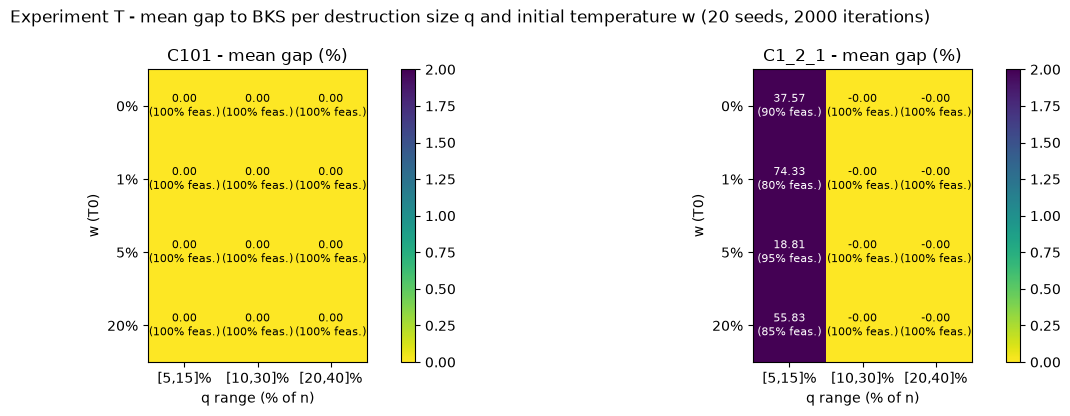

C101: Friedman test over the 12 configurations, all runs identical, no test needed
C1_2_1: Friedman test over the 12 configurations, p = 0.083


,instance,q,w,mean_gap,median_gap,ci95_low,ci95_high,feasible_pct,BKS_reached_pct,last_improvement,time_s
0,C101,"[5,15]%",0%,0.000,0.0,0.000,0.000,100.0,100.0,0.00,19.620
1,C101,"[5,15]%",1%,0.000,0.0,0.000,0.000,100.0,100.0,0.00,19.436
2,C101,"[5,15]%",5%,0.000,0.0,0.000,0.000,100.0,100.0,0.00,19.135
3,C101,"[5,15]%",20%,0.000,0.0,0.000,0.000,100.0,100.0,0.00,19.677
4,C101,"[10,30]%",0%,0.000,0.0,0.000,0.000,100.0,100.0,0.00,40.940
5,C101,"[10,30]%",1%,0.000,0.0,0.000,0.000,100.0,100.0,0.00,41.006
6,C101,"[10,30]%",5%,0.000,0.0,0.000,0.000,100.0,100.0,0.00,40.452
7,C101,"[10,30]%",20%,0.000,0.0,0.000,0.000,100.0,100.0,0.00,41.906
8,C101,"[20,40]%",0%,0.000,0.0,0.000,0.000,100.0,100.0,0.00,68.165
9,C101,"[20,40]%",1%,0.000,0.0,0.000,0.000,100.0,100.0,0.00,68.415


In [16]:
TUNING_FILES = [f for f, r in INSTANCE_FILES.items() if r == "tuning"]
Q_RANGES = {"[5,15]%": (0.05, 0.15), "[10,30]%": (0.10, 0.30), "[20,40]%": (0.20, 0.40)}
W_VALUES = [0.0, 0.01, 0.05, 0.20]

jobs = [(f, s, f"q {qn} | w {w:.0%}", dict(q_min_frac=a, q_max_frac=b, q_max_abs=10**9, start_worse=w, iterations=2000),
         ("current", "best", "worse_acc") if s == 0 else ())
        for f in TUNING_FILES for s in SEEDS for qn, (a, b) in Q_RANGES.items() for w in W_VALUES]
tun, tun_hist = cached("T_q_temperature", jobs)
tun["q"] = tun.variant.str.extract(r"q (\S+)")[0]
tun["w"] = tun.variant.str.extract(r"w (\S+)")[0]
tun["success"] = tun.gap <= 0.01                           # BKS reached (up to the rounding of the BKS)

fig, axes = plt.subplots(1, len(TUNING_FILES), figsize=(6.5 * len(TUNING_FILES), 4.2))
for ax, (name, g) in zip(axes, tun.groupby("instance", sort=False)):
    H = g.pivot_table(index="w", columns="q", values="gap", aggfunc="mean").loc[[f"{w:.0%}" for w in W_VALUES], list(Q_RANGES)]
    F = g.pivot_table(index="w", columns="q", values="feasible", aggfunc="mean").loc[H.index, H.columns]
    im = ax.imshow(np.minimum(H.values, 2), cmap="viridis_r", vmin=0, vmax=2)   # colours capped at 2 % so that
    for (y, x), v in np.ndenumerate(H.values):                                  # one infeasible cell does not hide the rest
        ax.text(x, y, f"{v:.2f}\n({F.values[y, x]:.0%} feas.)", ha="center", va="center", fontsize=8,
                color="w" if v > 1 else "k")
    ax.set_xticks(range(len(H.columns)), H.columns); ax.set_yticks(range(len(H.index)), H.index)
    ax.set_xlabel("q range (% of n)"); ax.set_ylabel("w (T0)"); ax.set_title(f"{name} - mean gap (%)")
    fig.colorbar(im, ax=ax)
fig.suptitle("Experiment T - mean gap to BKS per destruction size q and initial temperature w (20 seeds, 2000 iterations)")
plt.tight_layout(); plt.show()

for name, g in tun.groupby("instance", sort=False):
    groups = [gv.sort_values("seed").gap.to_numpy() for _, gv in g.groupby("variant", sort=False)]
    p = friedman_p(groups)
    print(f"{name}: Friedman test over the 12 configurations, " + ("all runs identical, no test needed" if np.isnan(p) else f"p = {p:.3g}"))

tun_table = pd.DataFrame([dict(instance=name, q=gv.q.iloc[0], w=gv.w.iloc[0], **describe(gv),
                               BKS_reached_pct=100 * gv.success.mean(), last_improvement=gv.last_improvement.mean())
                          for (name, v), gv in tun.groupby(["instance", "variant"], sort=False)])
tun_table[["instance", "q", "w", "mean_gap", "median_gap", "ci95_low", "ci95_high", "feasible_pct",
           "BKS_reached_pct", "last_improvement", "time_s"]].round(3)

In [17]:
# Effect of the factors on the success rate (BKS reached) on C1_2_1: Fisher exact tests, Holm correction
g = tun[tun.instance == "C1_2_1"]
tests = {"q [5,15]% vs q [10,30]% (all w)": (g[g.q == "[5,15]%"].success, g[g.q == "[10,30]%"].success),
         "q [10,30]% vs q [20,40]% (all w)": (g[g.q == "[10,30]%"].success, g[g.q == "[20,40]%"].success),
         "w 0% vs w 5% (q [5,15]%)": (g[(g.q == "[5,15]%") & (g.w == "0%")].success, g[(g.q == "[5,15]%") & (g.w == "5%")].success)}
p = [fisher_p(a, b) for a, b in tests.values()]
pd.DataFrame({"success rate A": [a.mean() for a, _ in tests.values()], "success rate B": [b.mean() for _, b in tests.values()],
              "p (Fisher)": p, "p (Holm)": holm(p)}, index=list(tests)).round({"success rate A": 2, "success rate B": 2})

,success rate A,success rate B,p (Fisher),p (Holm)
"q [5,15]% vs q [10,30]% (all w)",0.69,1.00,6.433530e-09,1.930059e-08
"q [10,30]% vs q [20,40]% (all w)",1.00,1.00,1.000000e+00,1.000000e+00
"w 0% vs w 5% (q [5,15]%)",0.70,0.75,1.000000e+00,1.000000e+00


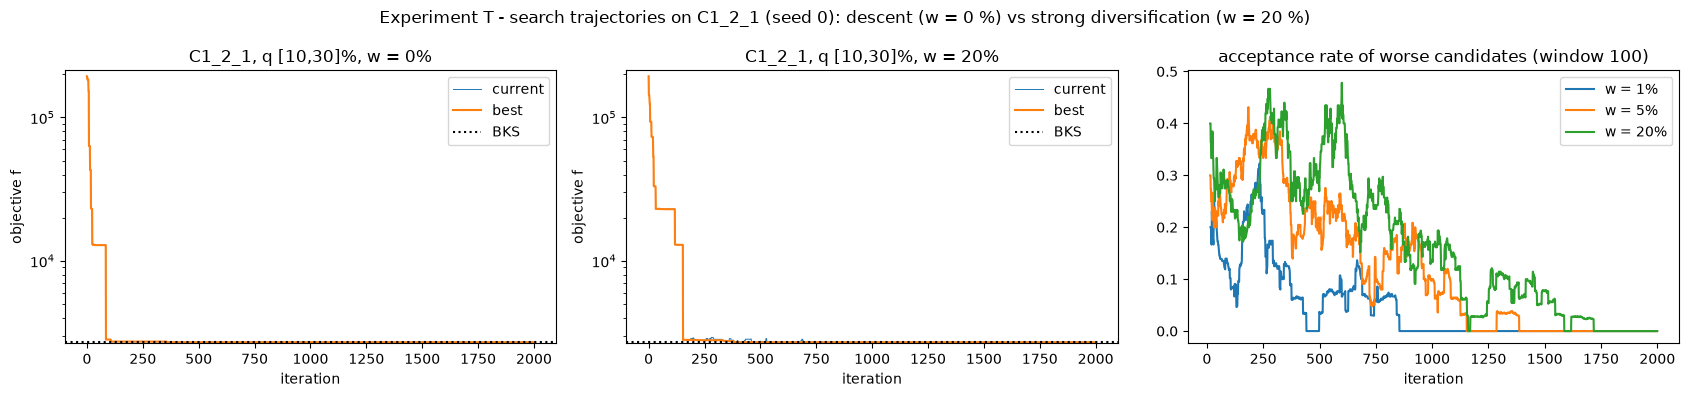

In [18]:
# Trajectories (seed 0, C1_2_1, q in [10,30]%) and acceptance rate of strictly worse candidates
traced = {(r.instance, r.variant): tun_hist[i] for i, r in tun.iterrows() if r.seed == 0}
name = "C1_2_1"
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for w, ax in zip(["0%", "20%"], axes[:2]):
    h = traced[(name, f"q [10,30]% | w {w}")]
    ax.plot(h["current"], lw=.7, label="current"); ax.plot(h["best"], lw=1.5, label="best")
    ax.axhline(BKS[name], color="k", ls=":", label="BKS")
    ax.set_yscale("log")                                    # unserved customers cost 10^4 each: log scale
    ax.set_ylim(BKS[name] * 0.98, max(h["current"]) * 1.1); ax.set_ylabel("objective f")
    ax.set_title(f"{name}, q [10,30]%, w = {w}"); ax.set_xlabel("iteration"); ax.legend()
for w in W_VALUES[1:]:
    h = traced[(name, f"q [10,30]% | w {w:.0%}")]
    axes[2].plot(pd.Series(h["worse_acc"]).rolling(100, min_periods=10).mean(), label=f"w = {w:.0%}")
axes[2].set_title("acceptance rate of worse candidates (window 100)"); axes[2].set_xlabel("iteration")
axes[2].legend()
fig.suptitle("Experiment T - search trajectories on C1_2_1 (seed 0): descent (w = 0 %) vs strong diversification (w = 20 %)")
plt.tight_layout(); plt.show()

### Analysis of T

- **C101 does not discriminate.** The initial regret-2 solution is already the BKS (828.94, 10 vehicles), so the 240 runs all stay at gap 0 and the Friedman test is not applicable. C101 only tells us that no setting degrades a good start.
- **On C1_2_1, $q$ is the parameter that matters.** The initial solution leaves 19 customers unserved. With $q \in [10, 30]\,\%$ or $[20, 40]\,\%$, **all 160 runs reach the BKS** (2704.57 with 20 vehicles), whatever $w$. With $q \in [5, 15]\,\%$, only 55 of 80 runs do (69 %, Fisher $p = 6 \times 10^{-9}$, Holm-corrected $p = 2 \times 10^{-8}$), and 10 runs still leave 1 customer unserved after 2000 iterations. Removing 10 to 30 customers out of 200 is often not enough to move a whole cluster to another route. The Friedman test on the gaps over the 12 configurations is not significant ($p = 0.083$): it works on ranks, and 75 % of the runs are tied at gap 0, so the success rate is the right indicator here.
- **$w$ has no significant effect** (Fisher test of $w = 0\,\%$ vs $w = 5\,\%$ at $q \in [5,15]\,\%$: 70 % vs 75 % success, $p = 1$). Since $T_0$ is computed on the distance, the temperature now acts at the scale of the distance (trajectories above, seed 0, $q \in [10, 30]\,\%$): during the first 500 iterations, 13 %, 29 % and 28 % of the strictly worse candidates are accepted with $w = 1$, 5 and 20 %, and once the solution is feasible the current solution stays within 13 % of the BKS. The acceptance rate falls to almost 0 after iteration 1500 for every $w$. The BKS is reached at about the same iteration with every $w$ (312 to 382), and the mean last improvement at $q \in [10, 30]\,\%$ is 321 to 394. On this instance the diversification comes from $q$, and the temperature changes little.
- **Cost of a larger $q$.** $[20, 40]\,\%$ is as good as $[10, 30]\,\%$ but 1.7 times slower (220 s vs 127 s per run, parallel runs), because each iteration reinserts twice as many customers.

**Choice for the next experiments (tuned configuration):** $q \in [10, 30]\,\%$ of $n$, without the cap of 40 customers (the smallest $q$ that reaches the BKS in every run), and $w = 5\,\%$ unchanged (no evidence to change it). The tuning set (C101, C1_2_1) is not used to evaluate this choice: it is evaluated on the test instances in B.

## Experiment B: benchmark and budgets (RQ2)

**Design.** Two configurations:
- **default**: the parameters of section 8 ($q$ between 5 % and 30 % of $n$ capped at 40, $w = 5\,\%$);
- **tuned**: the setting chosen in experiment T ($q \in [10\,\%, 30\,\%]$ of $n$ without a cap, $w = 5\,\%$).

They are run with 500, 1000 and 2000 iterations on the nineteen instances of 100 and 200 customers, 20 seeds each.

- **Longer budget.** The default configuration is also run with 5000 iterations, the default of the code, to see whether the search has converged at 2000.
- **C1_10_1 (1000 customers).** The default configuration with 2000 iterations, and a variant where $q$ grows with $n$: $q$ between 5 % and 10 % of $n$ without a cap, i.e. 50 to 100 customers per iteration instead of 50. The tuned $q$ (100 to 300 customers) is not run on C1_10_1: the cost of an iteration grows with $q$, so a run would be several times longer.

The benchmark table uses the reference budget of 2000 iterations. The project targets a mean gap below 5 % for $n < 100$ and below 7 % for $n < 200$.

In [19]:
TUNED = dict(q_min_frac=0.10, q_max_frac=0.30, q_max_abs=10**9, start_worse=0.05)   # chosen in experiment T
CONFIGS = {"default": {}, "tuned": TUNED}
BUDGETS = [500, 1000, 2000]
SMALL_FILES = [f for f, r in INSTANCE_FILES.items() if r != "scalability only" and get_instance(f)["n_customers"] <= 200]

jobs = [(f, s, f"{c} | {b}", dict(kw, iterations=b), ("best",) if b == max(BUDGETS) else ())
        for f in SMALL_FILES for s in SEEDS for c, kw in CONFIGS.items() for b in BUDGETS]
jobs += [("C1_10_1.1000.100.vrptw", s, "default | 2000", dict(iterations=2000), ("best",)) for s in SEEDS]
jobs += [(f, s, "default | 5000", dict(iterations=5000), ()) for f in SMALL_FILES for s in SEEDS]        # longer budget
Q_PROP = dict(q_min_frac=0.05, q_max_frac=0.10, q_max_abs=10**9)         # q = 5 to 10 % of n, no cap: 50 to 100 on C1_10_1
jobs += [("C1_10_1.1000.100.vrptw", s, "q ~ n | 2000", dict(Q_PROP, iterations=2000), ()) for s in SEEDS]
bench, bench_hist = cached("B_benchmark_budgets", jobs)
bench["config"] = bench.variant.str.split(" | ", regex=False).str[0]
bench["budget"] = bench.variant.str.split(" | ", regex=False).str[1].astype(int)


def target(n):
    return 5.0 if n < 100 else 7.0 if n < 200 else np.nan


rows = []
for (name, c), g in bench[bench.budget == 2000].groupby(["instance", "config"], sort=False):
    rows.append(dict(instance=name, n=g.n.iloc[0], config=c, BKS=BKS[name], **describe(g),
                     target_gap=target(g.n.iloc[0])))
benchmark = pd.DataFrame(rows)
benchmark["target_met"] = np.where(benchmark.target_gap.isna(), "no target", benchmark.mean_gap < benchmark.target_gap)
benchmark[["instance", "n", "config", "BKS", "best_cost", "mean_cost", "median_cost", "std_cost", "mean_gap",
           "median_gap", "ci95_low", "ci95_high", "best_gap", "feasible_pct", "vehicles", "time_s",
           "target_gap", "target_met"]].round(3)

,instance,n,config,BKS,best_cost,mean_cost,median_cost,std_cost,mean_gap,median_gap,ci95_low,ci95_high,best_gap,feasible_pct,vehicles,time_s,target_gap,target_met
0,C101,100,default,828.937,828.937,828.937,828.937,0.000,0.000,0.000,0.000,0.000,0.000,100.0,10.00,33.213,7.0,True
1,C101,100,tuned,828.937,828.937,828.937,828.937,0.000,0.000,0.000,0.000,0.000,0.000,100.0,10.00,37.069,7.0,True
2,C1_2_1,200,default,2704.570,2704.568,3205.634,2704.568,2240.834,18.527,-0.000,-20.250,57.303,-0.000,95.0,20.00,76.288,NaN,no target
3,C1_2_1,200,tuned,2704.570,2704.568,2704.568,2704.568,0.000,-0.000,-0.000,-0.000,-0.000,-0.000,100.0,20.00,140.235,NaN,no target
4,C102,100,default,828.940,828.937,828.937,828.937,0.000,-0.000,-0.000,-0.000,-0.000,-0.000,100.0,10.00,39.972,7.0,True
5,C102,100,tuned,828.940,828.937,828.937,828.937,0.000,-0.000,-0.000,-0.000,-0.000,-0.000,100.0,10.00,46.211,7.0,True
6,R101,100,default,1642.877,1642.877,1651.657,1650.758,6.183,0.534,0.480,0.358,0.711,0.000,100.0,19.80,84.770,7.0,True
7,R101,100,tuned,1642.877,1643.089,1650.681,1650.105,6.142,0.475,0.440,0.300,0.650,0.013,100.0,19.70,100.819,7.0,True
8,RC101,100,default,1623.557,1644.666,1662.947,1664.290,7.512,2.426,2.509,2.210,2.643,1.300,100.0,16.25,69.376,7.0,True
9,RC101,100,tuned,1623.557,1643.584,1665.641,1663.923,9.768,2.592,2.486,2.311,2.874,1.234,100.0,16.25,78.578,7.0,True


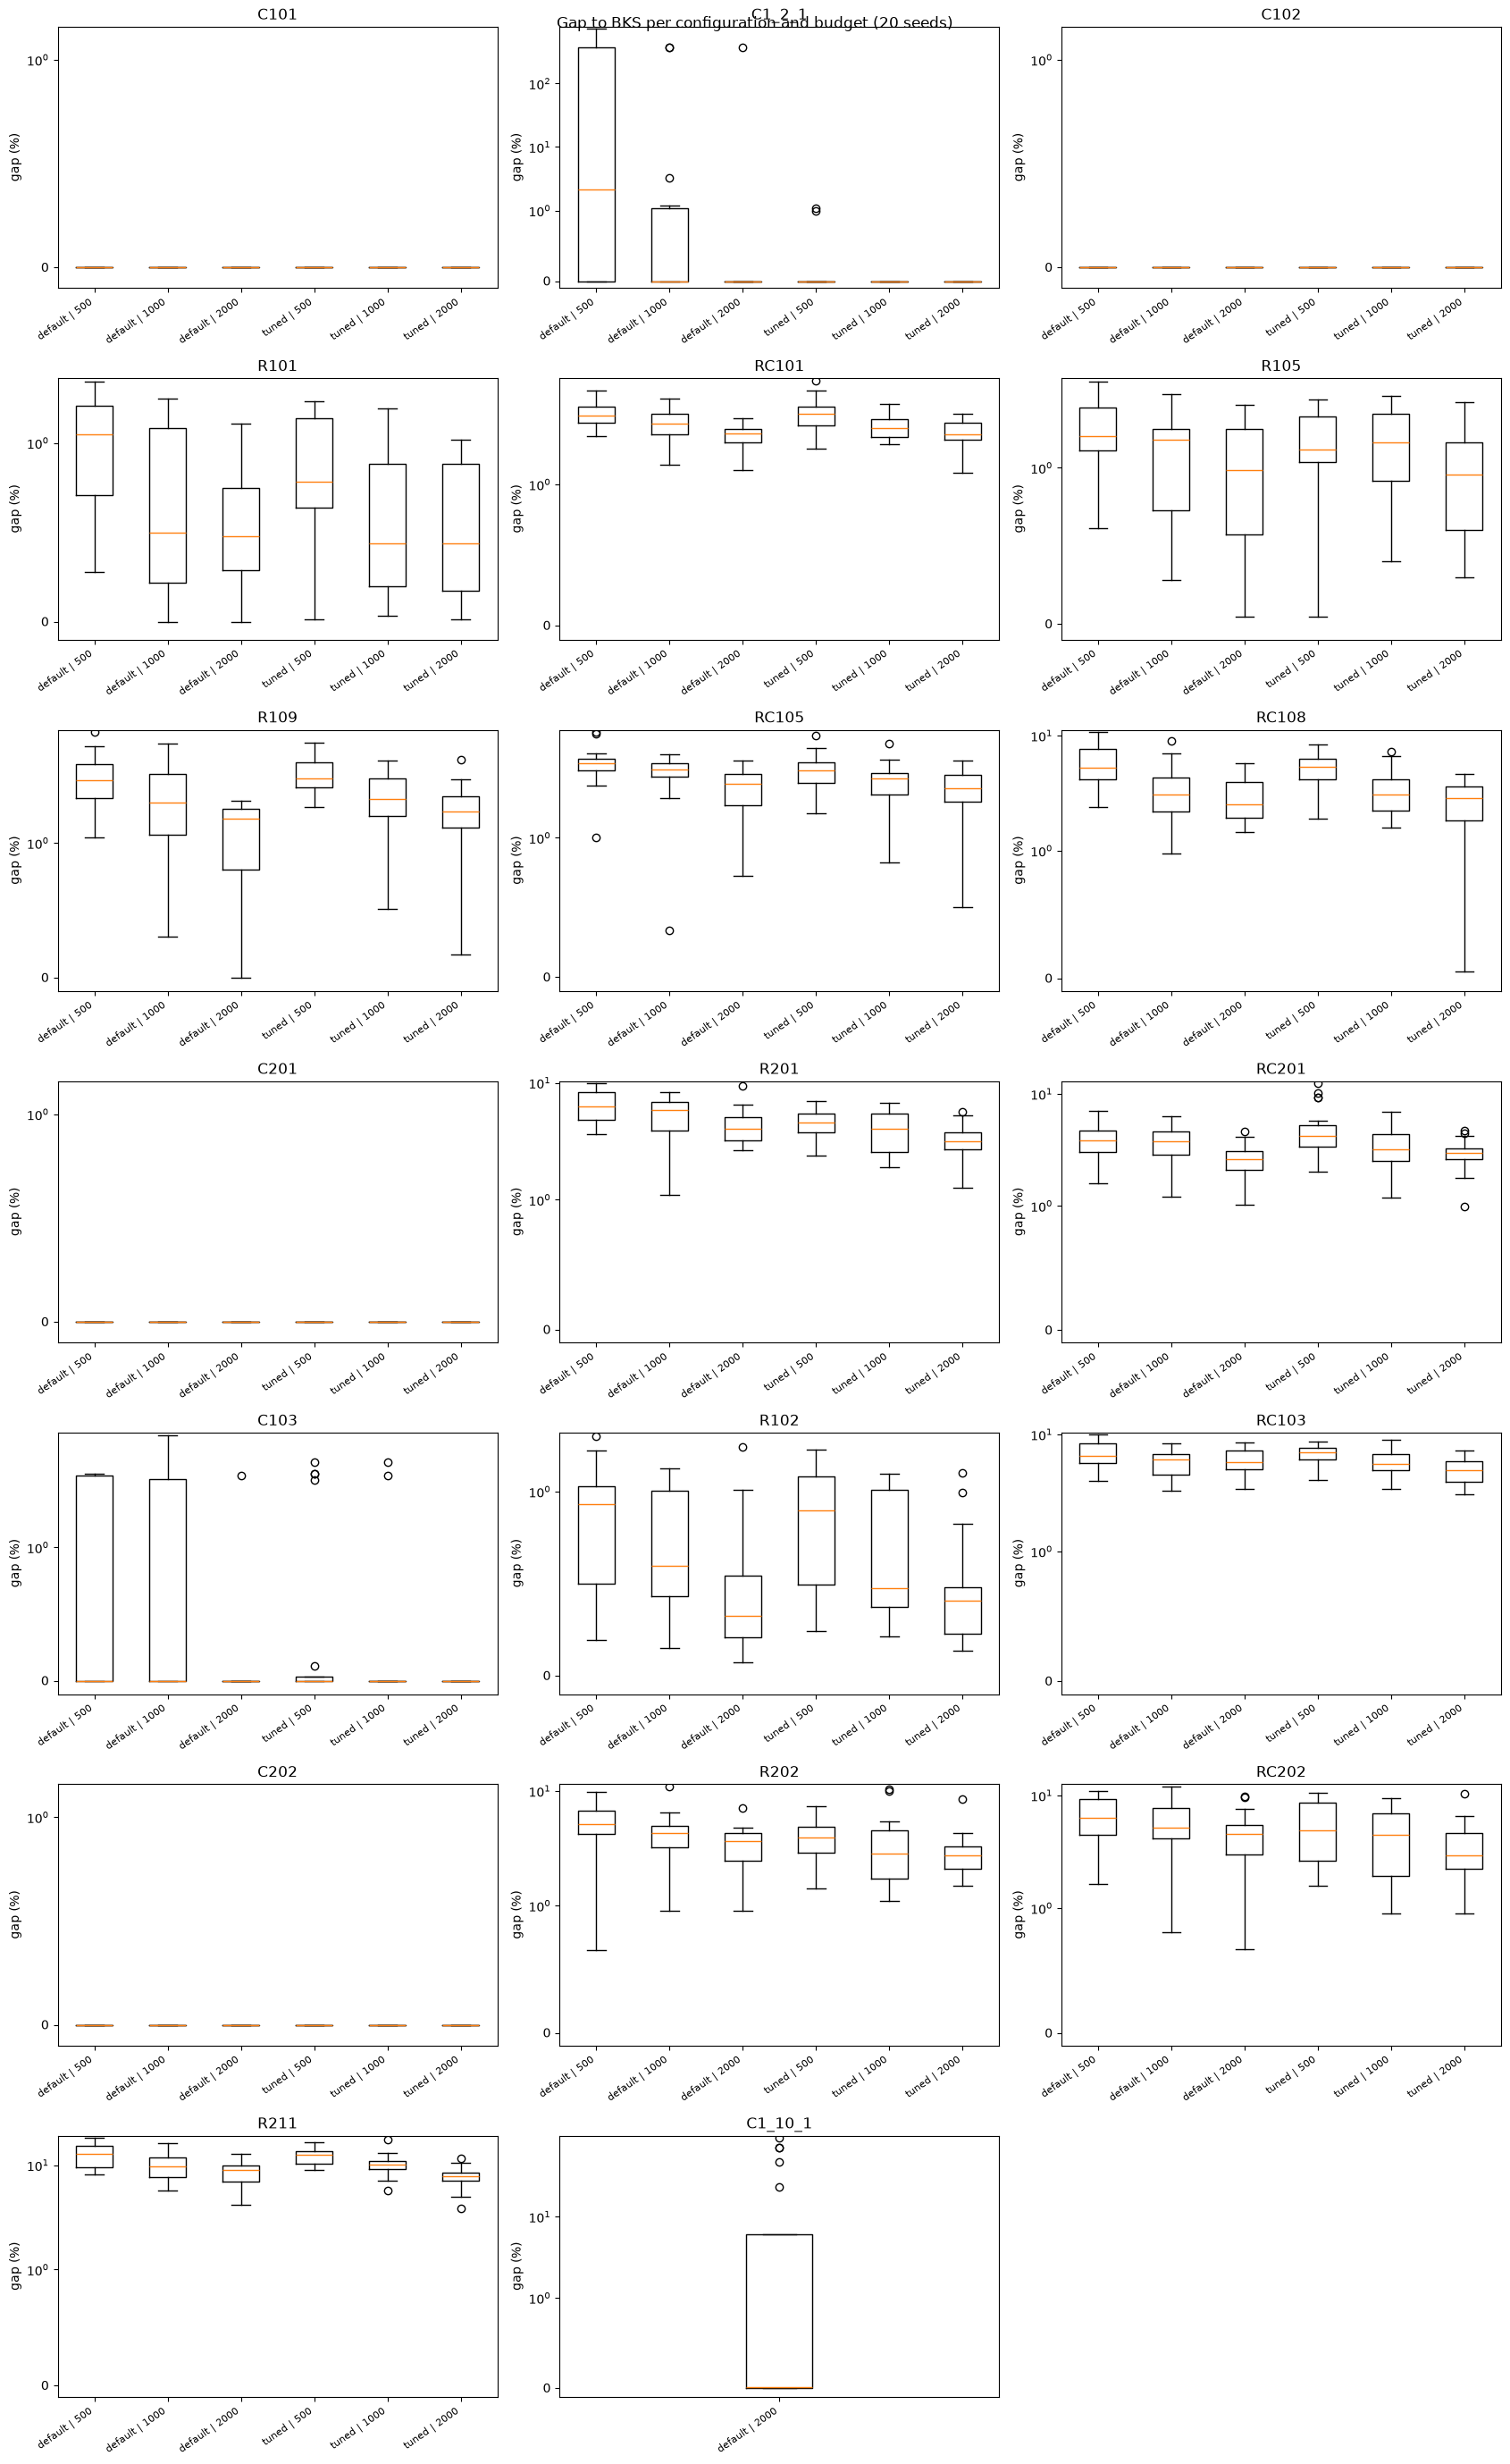

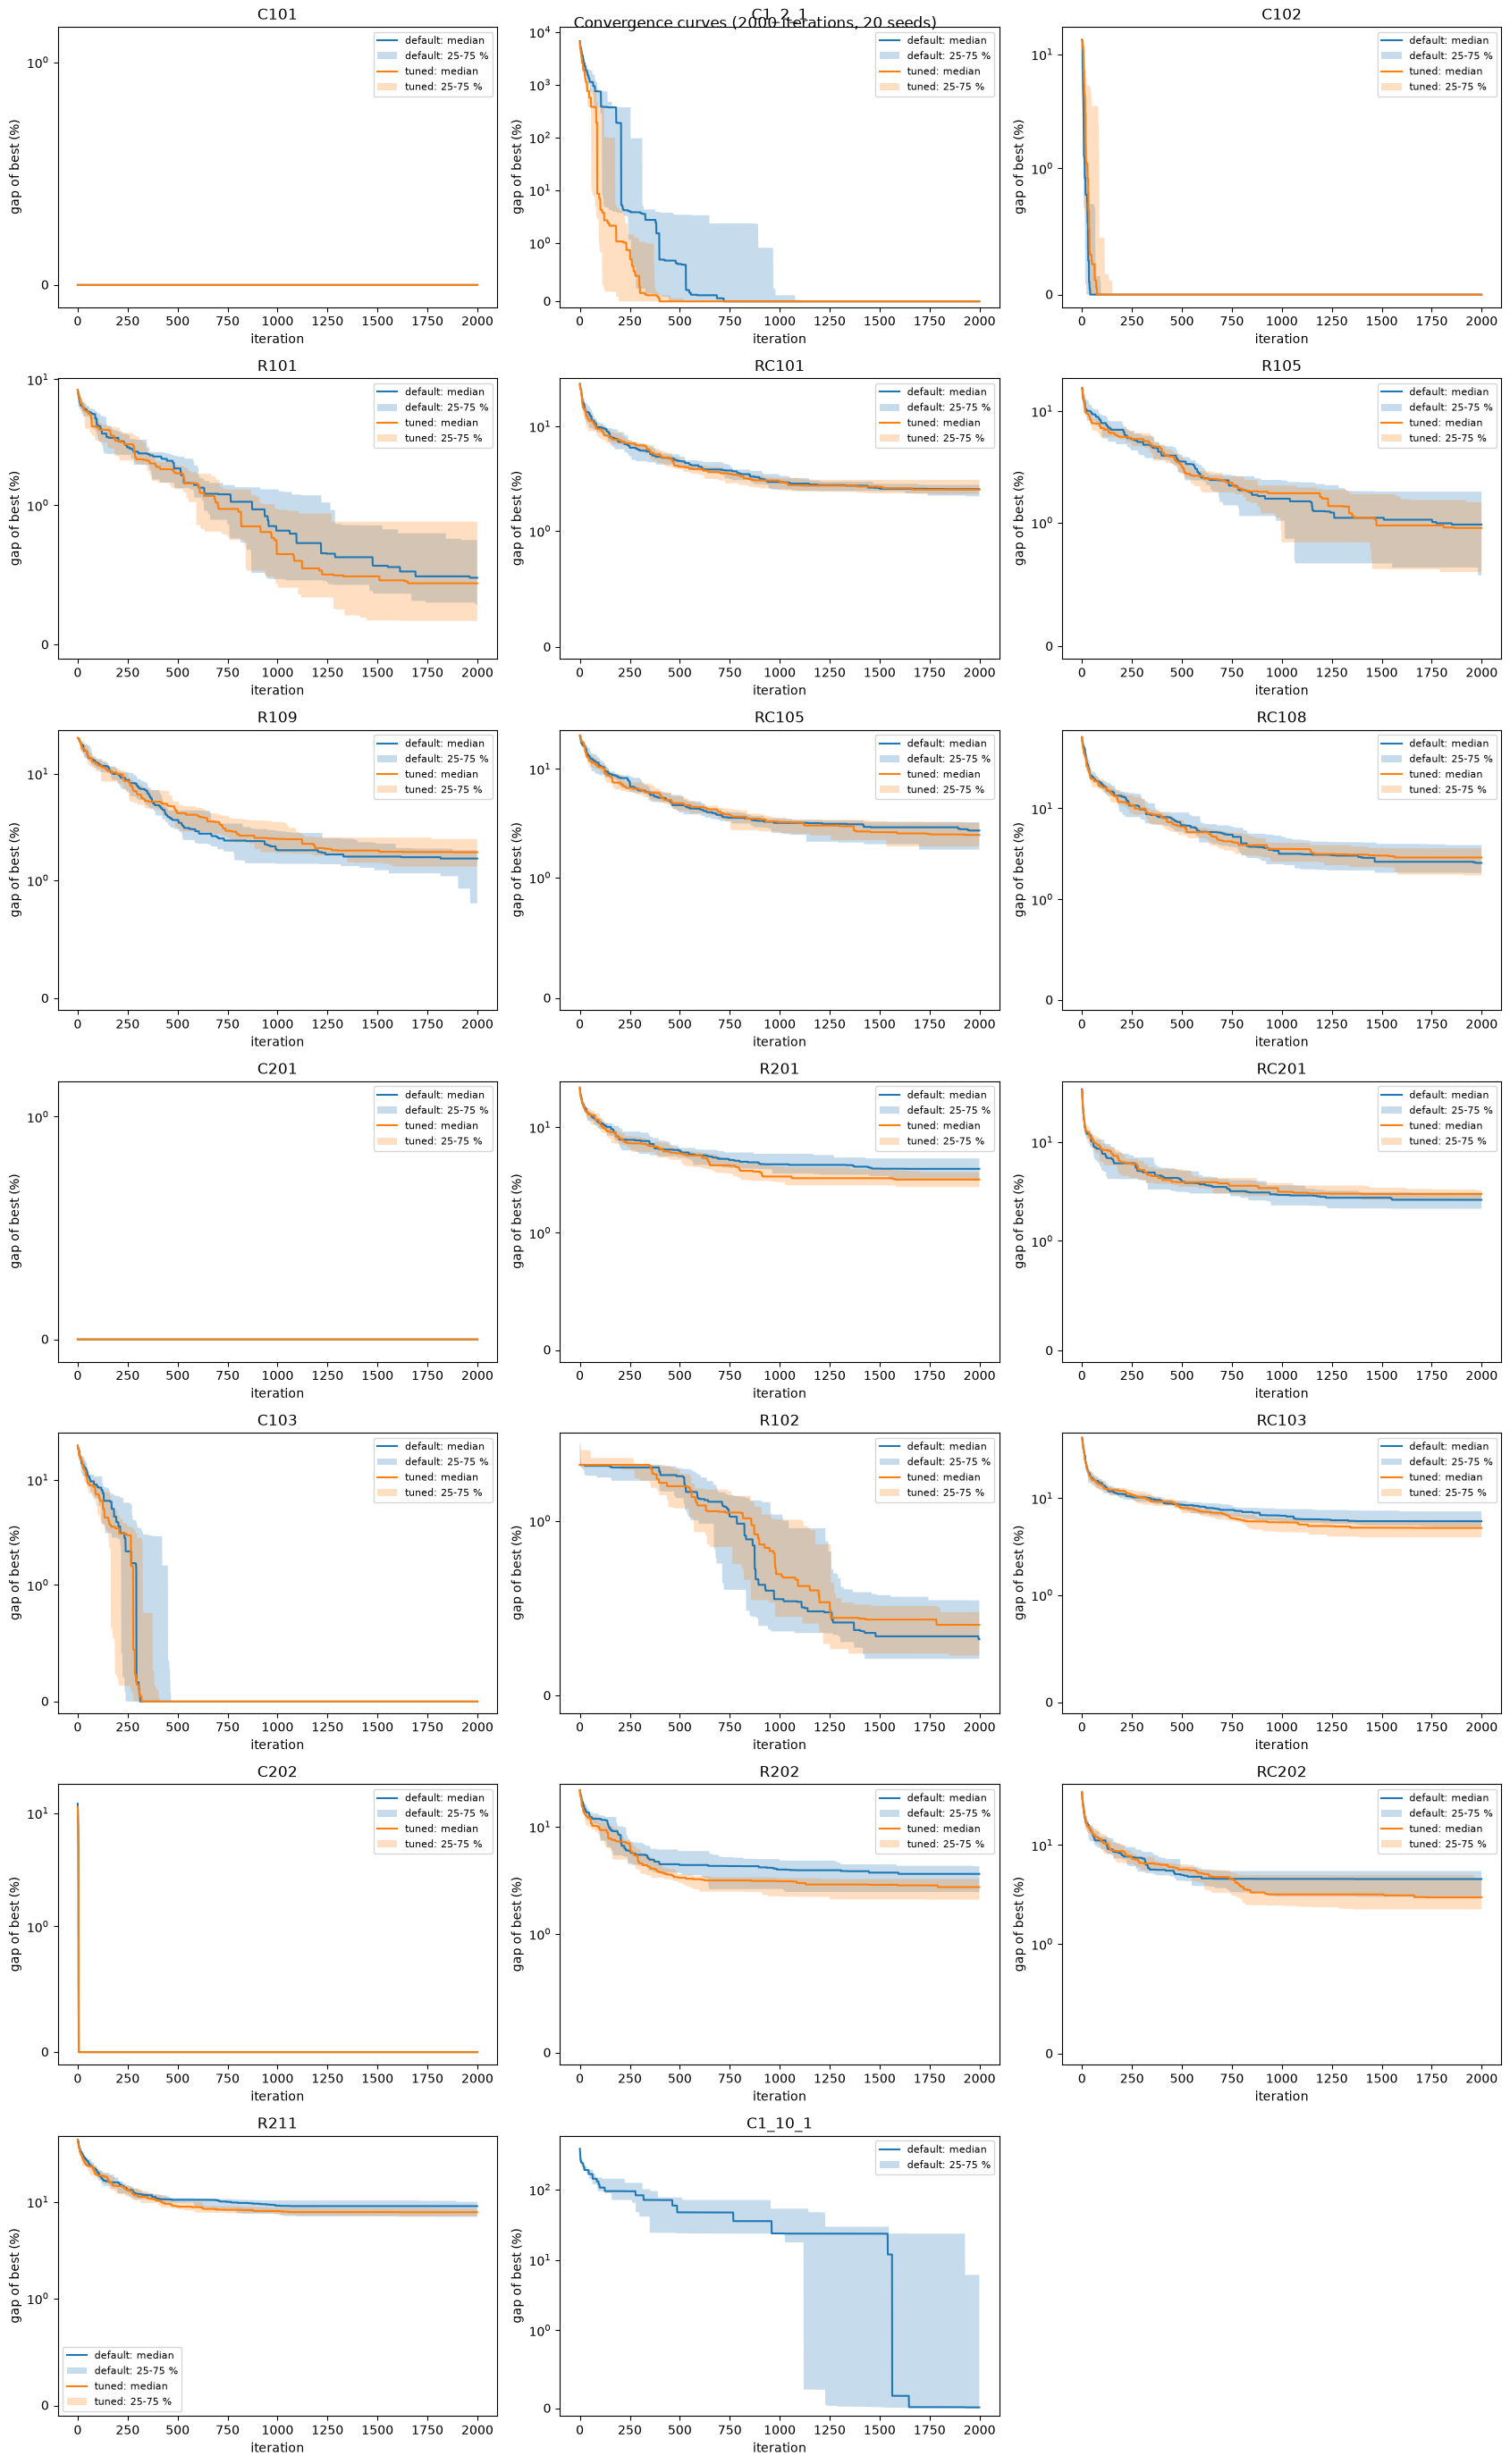

In [20]:
# Gap distribution per configuration and budget (boxplots), and convergence of the best solution (2000 iterations)
names = list(bench.instance.unique())
fig, axes = plt.subplots(math.ceil(len(names) / 3), 3, figsize=(17, 4 * math.ceil(len(names) / 3)))
for ax in axes.flat[len(names):]:
    ax.axis("off")
for ax, name in zip(axes.flat, names):
    g = bench[bench.instance == name]
    labels = [f"{c} | {b}" for c in CONFIGS for b in BUDGETS if f"{c} | {b}" in set(g.variant)]
    ax.boxplot([g[g.variant == v].gap.round(6).clip(lower=0) for v in labels])   # round: float noise around 0
    ax.set_xticks(range(1, len(labels) + 1), labels, rotation=35, ha="right", fontsize=8)
    ax.set_yscale("symlog", linthresh=1)                    # infeasible runs have gaps of hundreds of %
    ax.set_ylim(-0.1, max(1.5, ax.get_ylim()[1])); ax.set_title(name); ax.set_ylabel("gap (%)")
plt.suptitle("Gap to BKS per configuration and budget (20 seeds)"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(math.ceil(len(names) / 3), 3, figsize=(17, 4 * math.ceil(len(names) / 3)))
for ax in axes.flat[len(names):]:
    ax.axis("off")
for ax, name in zip(axes.flat, names):
    for c in CONFIGS:
        idx = bench.index[(bench.instance == name) & (bench.config == c) & (bench.budget == 2000)]
        if len(idx) == 0:
            continue
        G = np.clip((100 * (np.array([bench_hist[i]["best"] for i in idx]) - BKS[name]) / BKS[name]).round(6), 0, None)
        ax.plot(np.median(G, axis=0), label=f"{c}: median")
        ax.fill_between(range(G.shape[1]), np.percentile(G, 25, axis=0), np.percentile(G, 75, axis=0), alpha=.25,
                        label=f"{c}: 25-75 %")
    ax.set_yscale("symlog", linthresh=1); ax.set_ylim(-0.1, max(1.5, ax.get_ylim()[1]))
    ax.set_title(name); ax.set_xlabel("iteration"); ax.set_ylabel("gap of best (%)")
    ax.legend(fontsize=8)
plt.suptitle("Convergence curves (2000 iterations, 20 seeds)"); plt.tight_layout(); plt.show()

In [21]:
# Default vs tuned at the same number of iterations, and tuned 1000 vs default 2000.
# Per iteration, tuned costs 1.0-1.2x the default on the 100-customer instances and 1.7x on C1_2_1 (time_ratio column),
# so equal iterations is also roughly equal time, except on C1_2_1 where tuned 1000 vs default 2000 is the equal-time pair
rows = []
for name, g in bench[bench.instance != "C1_10_1"].groupby("instance", sort=False):
    pairs = [(f"tuned {b} vs default {b}", f"tuned | {b}", f"default | {b}") for b in BUDGETS]
    pairs += [("tuned 1000 vs default 2000", "tuned | 1000", "default | 2000")]
    for label, vx, vy in pairs:
        x, y = g[g.variant == vx].sort_values("seed"), g[g.variant == vy].sort_values("seed")
        rows.append(dict(instance=name, comparison=label, mean_gap_tuned=x.gap.mean(), mean_gap_default=y.gap.mean(),
                         feasible_tuned=100 * x.feasible.mean(), feasible_default=100 * y.feasible.mean(),
                         time_ratio=x.runtime.mean() / y.runtime.mean(), A12=a12(x.gap, y.gap),
                         p_wilcoxon=wilcoxon_p(x.gap, y.gap)))
fair = pd.DataFrame(rows)
fair["p_holm"] = holm(fair.p_wilcoxon)
fair.round(4)

,instance,comparison,mean_gap_tuned,mean_gap_default,feasible_tuned,feasible_default,time_ratio,A12,p_wilcoxon,p_holm
0,C101,tuned 500 vs default 500,0.0000,0.0000,100.0,100.0,1.1901,0.5000,1.0000,1.0000
1,C101,tuned 1000 vs default 1000,0.0000,0.0000,100.0,100.0,1.1302,0.5000,1.0000,1.0000
2,C101,tuned 2000 vs default 2000,0.0000,0.0000,100.0,100.0,1.1161,0.5000,1.0000,1.0000
3,C101,tuned 1000 vs default 2000,0.0000,0.0000,100.0,100.0,0.5798,0.5000,1.0000,1.0000
4,C1_2_1,tuned 500 vs default 500,0.1031,130.8760,100.0,70.0,1.7967,0.1975,0.0015,0.1158
...,...,...,...,...,...,...,...,...,...,...
71,RC202,tuned 1000 vs default 2000,4.7912,4.5961,100.0,100.0,0.5693,0.5038,0.6292,1.0000
72,R211,tuned 500 vs default 500,12.3785,12.6487,100.0,100.0,1.0982,0.4775,0.8124,1.0000
73,R211,tuned 1000 vs default 1000,10.1890,10.0171,100.0,100.0,1.1463,0.5275,0.7562,1.0000
74,R211,tuned 2000 vs default 2000,7.6416,8.4708,100.0,100.0,1.1591,0.3825,0.4524,1.0000


In [22]:
# Effect of a longer budget (default configuration): mean gap at 500, 1000, 2000 and 5000 iterations,
# and paired Wilcoxon test 5000 vs 2000 (Holm over the instances)
d = bench[bench.config == "default"]
budget_table = d.pivot_table(index="instance", columns="budget", values="gap", aggfunc="mean", sort=False)
p5000 = {name: wilcoxon_p(g[g.budget == 5000].sort_values("seed").gap, g[g.budget == 2000].sort_values("seed").gap)
         for name, g in d.groupby("instance", sort=False) if (g.budget == 5000).any()}
budget_table["A12 (5000 vs 2000)"] = pd.Series({name: a12(g[g.budget == 5000].sort_values("seed").gap, g[g.budget == 2000].sort_values("seed").gap)
                                                for name, g in d.groupby("instance", sort=False) if (g.budget == 5000).any()})
budget_table["p_holm (5000 vs 2000)"] = pd.Series(holm(list(p5000.values())), index=list(p5000))
budget_table["time ratio 5000 / 2000"] = d[d.budget == 5000].groupby("instance").runtime.mean() / d[d.budget == 2000].groupby("instance").runtime.mean()
budget_table.round(3)

budget,500,1000,2000,5000,A12 (5000 vs 2000),p_holm (5000 vs 2000),time ratio 5000 / 2000
instance,,,,,,,
C101,0.000,0.000,0.000,0.000,0.500,1.000,3.612
C1_2_1,130.876,37.422,18.527,-0.000,0.475,1.000,2.440
C102,-0.000,-0.000,-0.000,-0.000,0.500,1.000,2.391
R101,1.231,0.784,0.534,0.194,0.215,0.111,1.279
RC101,3.648,3.089,2.426,2.067,0.272,0.279,1.398
R105,1.987,1.545,1.234,0.744,0.325,0.585,1.866
R109,3.569,2.470,1.399,0.683,0.218,0.026,1.499
RC105,3.926,3.299,2.442,2.365,0.478,1.000,2.592
RC108,5.778,3.557,2.899,1.854,0.251,0.095,2.894


### Analysis of B

**Quality (2000 iterations, default / tuned).**
- **Clustered instances are solved.** C101, C102, C201 and C202 reach the BKS in 100 % of the runs with both configurations. On C103, tuned reaches it in every run and default has a mean gap of 0.20 % (median 0). On C1_2_1, one default run leaves 1 customer unserved (mean gap 18.5 %, median 0); tuned reaches the BKS in every run.
- **Random instances, series 1.** Mean gap 0.53 / 0.48 % on R101, 0.47 / 0.43 % on R102, 1.23 / 1.17 % on R105 and 1.40 / 1.95 % on R109. One default run on R109 is even 0.006 % below the reference `.sol` file (1151.84 vs 1151.91).
- **Mixed instances, series 1** are harder: 2.43 / 2.59 % on RC101, 2.44 / 2.41 % on RC105, 2.90 / 2.63 % on RC108 and 5.96 / 4.96 % on RC103. On RC101 the ALNS uses 16.25 vehicles where the reference uses 15: our objective only minimises distance, so it has no incentive to merge a route.
- **Series 2 (long horizon, few long routes)** gives the largest gaps on R and RC: 4.40 / 3.30 % on R201, 3.49 / 2.97 % on R202, 2.65 / 3.01 % on RC201, 4.60 / 3.55 % on RC202 and **8.47 / 7.64 % on R211**. R211 has 3 to 4 routes of about 30 customers: one iteration removes at most 30 customers, and rebuilding such long routes needs many coordinated moves.
- **Project target.** The mean gap is below 7 % on 17 of the 18 instances of 100 customers, and below 5 % on 16 of them (not RC103 default, 5.96 %, nor R211). **R211 misses the 7 % target** (8.47 / 7.64 %; 7.24 % with 5000 iterations; best run 3.85 %). The running times in the table come from parallel runs, which are 3 to 6 times slower than on an idle machine (see S).

**C1_10_1 (1000 customers).** 15 of 20 default runs (75 %) are feasible after 2000 iterations. The feasible ones are very close to the BKS (mean gap 0.04 %, worst 0.3 %), and the 5 others still leave 1 to 4 customers unserved (initial solution: 16). This is why the mean gap is 15 %: it is dominated by the penalty, while the median is 0.01 %. **With $q$ proportional to $n$** (50 to 100 customers instead of 50), the feasibility rate is the same (75 %), but the infeasible runs leave fewer customers unserved (1 or 2, 7 in total against 13), and the feasible runs are closer to the BKS (mean gap 0.002 %). The difference is not significant (Wilcoxon $p = 0.29$), and the infeasible runs are not the same seeds in the two variants. 2000 iterations remain too few to always serve the last customers at this size.

**Tuned vs default.**
- **At equal iterations**, tuned is better on C1_2_1 at 500 and 1000 iterations (100 % feasible against 70 % and 90 %, Wilcoxon $p = 0.002$ and $0.012$, $A_{12} = 0.20$ and $0.30$), but this is no longer significant after Holm correction over the 76 comparisons ($p_{Holm} = 0.12$ and $0.86$). At 2000 iterations, tuned has the lower mean gap on 12 of the 15 instances that are not always solved (default is better on RC101, R109 and RC201). The largest effects are on R201 ($A_{12} = 0.28$, raw $p = 0.048$), RC103 ($A_{12} = 0.32$, raw $p = 0.036$) and R202 ($A_{12} = 0.33$, raw $p = 0.083$), in favour of tuned. No difference is significant after correction.
- **At equal time.** Per iteration, tuned costs 1.05 to 1.24 times the default on the 100-customer instances (`time_ratio`), and 1.8 times on C1_2_1. On C1_2_1, tuned 1000 vs default 2000 is the equal-time pair (time ratio 0.94): tuned reaches the BKS in every run, default misses it once ($p = 0.32$). On the 100-customer instances, tuned 1000 vs default 2000 gives tuned only 52 to 60 % of the time, and default is then better on several R and RC instances (R109: $A_{12}$ of tuned 0.77, raw $p = 0.002$, $p_{Holm} = 0.15$; RC101, R211: raw $p \approx 0.03$). So the tuned $q$ mainly helps when the initial solution leaves customers unserved (C1_2_1); on the 100-customer instances it gives at most a small gain, not significant.
- **Longer budget (budget table).** For the default configuration, the gap keeps decreasing from 2000 to 5000 iterations on every R and RC instance: R101 0.53 → 0.19 %, R109 1.40 → 0.68 %, RC103 5.96 → 3.90 %, RC202 4.60 → 2.65 %, R211 8.47 → 7.24 %; on C1_2_1 every run becomes feasible. The effect sizes are small to large ($A_{12}$ of 5000 vs 2000 between 0.17 and 0.48), but only R109 and RC103 remain significant after Holm correction ($p_{Holm} = 0.026$ and $0.019$). The median last improvement at 2000 iterations is between iterations 900 and 1600 on all the R and RC instances. The ALNS has not converged at 2000 iterations: a larger budget still helps, with diminishing returns. The 5000-iteration runs take 1.3 to 3.6 times as long as the 2000-iteration ones (2.5 would be expected): the parallel load varied during the experiment.

## Lower bound: linear relaxation of the ILP

The gap of B is measured against the best known solution (BKS), which is an **upper bound** on the optimum: it tells how far we are from the best solution ever published, not from the optimum. To bound the true optimality gap, we solve the **linear relaxation** of the two-index ILP (section "ILP implementation", `build_ilp(..., relaxed=True)`): the same constraints (1) to (8), with the tight big-M values and the valid inequality (3'), but with $x_{ij} \in [0, 1]$. It takes every constraint of the problem into account, and its optimum $f_{LP}$ satisfies $f_{LP} \le f^* \le f_{BKS}$. For any ALNS solution $f$:

$$\text{gap}_{LB} = 100\,\frac{f - f_{LP}}{f_{LP}} \;\ge\; 100\,\frac{f - f^*}{f^*}$$

so $\text{gap}_{LB}$ is a **guaranteed** upper bound on the distance to the optimum, while the gap to the BKS is tighter but not guaranteed. The LP is solved on the 19 instances of 100 and 200 customers. On C1_10_1 the model has about 18 000 arcs per 100 customers and is not solved here.

In [23]:
# LP relaxation (lower bound) of every instance of B with at most 200 customers, compared with the BKS and the ALNS
rows = []
for f in SMALL_FILES:
    name = get_instance(f)["label"]
    lp, x = build_ilp(ilp_load(f"{DATA_DIR}/{f}"), relaxed=True)
    status, f_lp, secs = solve_ilp(lp, time_limit=600)
    assert status == "Optimal Solution Found", (name, status)     # a stopped LP would not be a valid bound
    g = bench[(bench.instance == name) & (bench.variant == "default | 2000")]
    rows.append(dict(instance=name, n=get_instance(f)["n_customers"], arcs=len(x), LP_bound=f_lp, LP_time_s=secs,
                     BKS=BKS[name], BKS_over_LB_pct=100 * (BKS[name] - f_lp) / f_lp,
                     alns_best=g.obj.min(), alns_mean=g.obj.mean(),
                     mean_gap_BKS_pct=g.gap.mean(), mean_gap_LB_pct=100 * (g.obj.mean() - f_lp) / f_lp,
                     best_gap_LB_pct=100 * (g.obj.min() - f_lp) / f_lp))
lower_bounds = pd.DataFrame(rows)
lower_bounds.to_csv("results/LB_lp_relaxation.csv", index=False)
lower_bounds.round(2)

,instance,n,arcs,LP_bound,LP_time_s,BKS,BKS_over_LB_pct,alns_best,alns_mean,mean_gap_BKS_pct,mean_gap_LB_pct,best_gap_LB_pct
0,C101,100,4512,822.20,0.57,828.94,0.82,828.94,828.94,0.00,0.82,0.82
1,C1_2_1,200,16386,2697.53,1.57,2704.57,0.26,2704.57,3205.63,18.53,18.84,0.26
2,C102,100,6682,705.16,0.76,828.94,17.55,828.94,828.94,-0.00,17.55,17.55
3,R101,100,3233,1617.56,0.32,1642.88,1.56,1642.88,1651.66,0.53,2.11,1.56
4,RC101,100,3637,1180.76,0.43,1623.56,37.50,1644.67,1662.95,2.43,40.84,39.29
5,R105,100,4253,1140.24,0.68,1360.12,19.28,1360.78,1376.91,1.23,20.76,19.34
6,R109,100,6024,788.48,0.72,1151.91,46.09,1151.84,1168.03,1.40,48.14,46.08
7,RC105,100,5237,940.64,0.58,1517.93,61.37,1528.98,1555.00,2.44,65.31,62.55
8,RC108,100,9305,668.06,0.97,1117.53,67.28,1133.83,1149.93,2.90,72.13,69.72
9,C201,100,5220,591.56,0.69,591.56,-0.00,591.56,591.56,0.00,-0.00,-0.00


### Analysis of the lower bound

- **The LP relaxation is cheap**: less than 1 s on every instance (3 000 to 16 000 arc variables after preprocessing), so it costs nothing next to the ALNS.
- **On a few instances it proves that the ALNS is (almost) optimal.** On C201 the LP bound equals the BKS (591.56), so the BKS is optimal and every ALNS run reaches it. The best ALNS run is at most 0.26 % from the optimum on C1_2_1, 0.82 % on C101 and 1.6 % on R101 (2.1 % for the mean run), and at most 5.7 % on C202. These guarantees hold whatever the true optimum is.
- **On the other instances the bound is weak**: the BKS is 15 to 79 % above it, so the guaranteed gap of the ALNS (18 to 85 % for the best run) says more about the bound than about the ALNS. C102 and C103 show it clearly: every run reaches the BKS, yet the guaranteed gap is 17.6 % and 39.8 %.
- **The bound gets weaker as the time windows get wider.** For R1, R101 → R105 → R109 (window width 10, 30, 59) gives a BKS 1.6 %, 19 % and 46 % above the bound; for RC1, RC101 → RC105 → RC108 (30, 54, 112) gives 38 %, 61 % and 67 %; for C1, C101 → C102 → C103 (61, 326, 588) gives 0.8 %, 18 % and 40 %; and C201 → C202 (160, 938) gives 0 % and 5.7 %. R102 (52 %) and RC103 (79 %) follow the same logic: a part of their customers have a window that covers almost the whole horizon. With wide windows, the big-M constraints (6) let a fractional $x_{ij}$ cross many time windows at almost no cost. Stronger formulations (cuts, column generation) would be needed for a useful bound there.
- **Consequence for the study.** The gap to the BKS stays the main quality indicator, because the BKS is much closer to the optimum than the LP bound on most instances. The LP bound adds a guarantee where it is tight, and shows that the ALNS is optimal or within 2 % of the optimum on C101, C1_2_1, C201 and R101.

## Effect of the instance parameters on quality and time

The Solomon instances differ in three ways: the **distribution** of the customers (C, R, RC), the **series** (1: short horizon, small vehicles, many short routes; 2: long horizon, large vehicles, few long routes) and the **width of the time windows**. The table groups the runs of B (2000 iterations, 100-customer instances, default and tuned) by each feature and gives the gap and the running time as mean ± standard deviation and median ± MAD (median absolute deviation, robust to the few bad runs). The window width is the mean width over the customers of the instance (instance table).

In [24]:
from scipy.stats import median_abs_deviation as mad


def spread(df, by, cols):
    # mean, std, median and MAD of each column, per group
    g = df.groupby(by, sort=False, observed=True)[cols]
    out = pd.concat({"mean": g.mean(), "std": g.std(), "median": g.median(), "MAD": g.agg(mad)}, axis=1)
    out = out.swaplevel(axis=1)[[(c, s) for c in cols for s in ("mean", "std", "median", "MAD")]]
    grp = df.groupby(by, sort=False, observed=True)
    return out.assign(instances=grp.instance.nunique(), runs=grp.size())


features = instances_table.set_index("instance")[["distribution", "mean_window_width"]]
b100 = bench[(bench.budget == 2000) & (bench.n == 100)].join(features, on="instance")
b100["series"] = "series " + b100.instance.str[-3]                     # C101 -> 1, RC201 -> 2
b100["window width"] = pd.cut(b100.mean_window_width, [0, 40, 80, 400], labels=["narrow (<= 40)", "medium (40-80)", "wide (> 80)"])
by_feature = pd.concat({f: spread(b100, f, ["gap", "runtime"]) for f in ("distribution", "series", "window width")})
by_feature.index.names = ["feature", "level"]
by_feature.round(2)

gap                    runtime                \
                             mean   std median   MAD    mean    std median   
feature      level                                                           
distribution clustered (C)   0.02  0.28   0.00  0.00   49.07  10.10  50.29   
             random (R)      2.71  2.78   1.82  1.37   64.83  29.70  55.23   
             mixed (RC)      3.34  1.74   2.96  0.85   50.32  14.06  47.28   
series       series 1        1.55  1.78   0.94  0.94   58.83  26.62  52.71   
             series 2        3.15  2.94   2.89  2.02   50.57  10.36  48.70   
window width medium (40-80)  1.14  1.20   0.61  0.61   56.29  24.52  52.00   
             wide (> 80)     2.78  2.23   2.86  1.48   44.82   7.51  44.55   
             narrow (<= 40)  1.40  1.02   1.10  0.79   80.29  31.42  73.25   

                                   instances runs  
                               MAD                 
feature      level                                 
distribution clustered (C)    8.06         5  200  
             random (R)      12.19         7  280  
             mixed (RC)       8.52         6  240  
series       series 1        12.22        11  440  
             series 2         6.88         7  280  
window width medium (40-80)  10.29         4  160  
             wide (> 80)      5.69         8  320  
             narrow (<= 40)   9.58         3  120

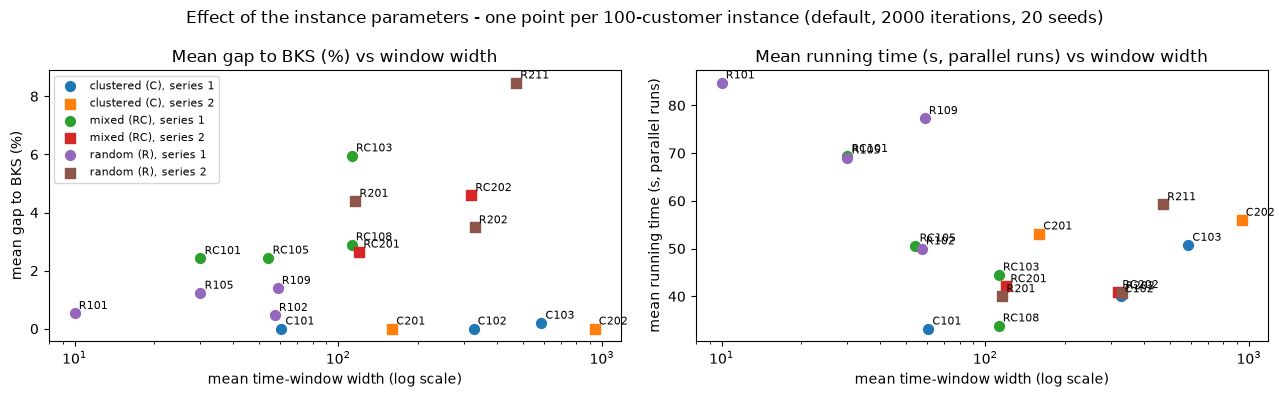

In [25]:
# Gap and time per instance against the window width (one point per instance, mean of the 20 default runs)
per_inst = b100[b100.config == "default"].groupby("instance").agg(gap=("gap", "mean"), time=("runtime", "mean"),
                                                                  width=("mean_window_width", "first"), kind=("distribution", "first"),
                                                                  series=("series", "first"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, label in ((axes[0], "gap", "mean gap to BKS (%)"), (axes[1], "time", "mean running time (s, parallel runs)")):
    for (kind, series), g in per_inst.groupby(["kind", "series"]):
        ax.scatter(g.width, g[col], s=50, marker="o" if series == "series 1" else "s", label=f"{kind}, {series}")
    for name, r in per_inst.iterrows():
        ax.annotate(name, (r.width, r[col]), fontsize=8, xytext=(3, 3), textcoords="offset points")
    ax.set_xscale("log"); ax.set_xlabel("mean time-window width (log scale)"); ax.set_ylabel(label)
    ax.set_title(label[0].upper() + label[1:] + " vs window width")
axes[0].legend(fontsize=8)
fig.suptitle("Effect of the instance parameters - one point per 100-customer instance (default, 2000 iterations, 20 seeds)")
plt.tight_layout(); plt.show()

### Analysis of the instance parameters

The table pools the 18 instances of 100 customers, both configurations, 2000 iterations.

- **Distribution is the strongest factor.** The clustered instances are almost always solved to the BKS (mean gap 0.02 ± 0.28 %, median 0; only C103 with the default configuration is above). The random ones have a mean gap of 2.7 ± 2.8 % (median 1.8 ± 1.4), and the mixed ones 3.3 ± 1.7 % (median 3.0 ± 0.9). A likely reason is that in RC the clusters and the isolated customers have to share the same routes, which makes good insertions rarer. The large standard deviation of R comes from R211 (8 %).
- **Series 2 is harder.** Its mean gap is 3.2 ± 2.9 % (median 2.9) against 1.6 ± 1.8 % (median 0.9) in series 1. With 3 to 8 long routes, an iteration touches only a small part of the routes, and rebuilding a long route needs many coordinated moves. Its runs are slightly faster (median 49 s against 53 s, parallel runs).
- **Window width: wider windows tend to give larger gaps**, 2.8 % for the wide windows (> 80) against 1.1 to 1.4 % for the narrow and medium ones. Within a family, the trend is clear on RC1 (RC101, RC105: 2.4 to 2.5 %; RC103: 5.5 %) and on R2 (R201: 3.9 %, R202: 3.2 %, R211: 8.1 %). But the mean width is not enough to describe an instance: R102 has a mean width of 57, yet a gap of only 0.45 %, because 75 % of its customers have a narrow window (10) and the mean is pulled up by the others. With wide windows, many more insertions are feasible, so the search space is larger; the time windows also cost much less distance in that case (experiment C).
- **Time** depends mostly on the number of routes: the narrow-window instances use the most vehicles (15 to 20) and have the longest runs (median 73 s against 45 s for the wide windows). The standard deviations of the time (8 to 31 s) come largely from the parallel runs, so medians and MAD are the figures to read.

## Effect of the algorithm parameters on time, with dispersion

The tables below give the running time and the iteration of the last improvement (how long the search keeps finding better solutions) as mean, standard deviation, median and MAD, for the three algorithm parameters that change the cost of an iteration: the destruction size $q$ (T, on C1_2_1), the configuration default / tuned (B, 100-customer instances, 2000 iterations) and the repair operator (S, time per iteration in ms over the 3 seeds).

In [26]:
t_q = spread(tun[tun.instance == "C1_2_1"], "q", ["runtime", "last_improvement"])
t_cfg = spread(b100.assign(iter_ms=1000 * b100.iter_time), "config", ["runtime", "iter_ms", "last_improvement"])
display(t_q.round(1), t_cfg.round(1))

runtime                   last_improvement                       \
            mean   std median  MAD             mean    std median    MAD   
q                                                                          
[5,15]%     53.4   4.2   53.2  3.8            897.4  476.9  814.5  319.0   
[10,30]%   126.5   9.3  125.6  7.2            357.4  174.6  362.5  117.0   
[20,40]%   219.9  18.7  224.3  9.9            222.5  123.1  195.5   74.0   

         instances runs  
                         
q                        
[5,15]%          1   80  
[10,30]%         1   80  
[20,40]%         1   80

runtime                   iter_ms                   last_improvement  \
           mean   std median  MAD    mean   std median  MAD             mean   
config                                                                         
default    52.0  20.6   47.3  9.0    25.8  10.3   23.5  4.5            974.0   
tuned      59.3  23.1   53.6  9.6    29.4  11.5   26.6  4.8            952.3   

                              instances runs  
           std  median    MAD                 
config                                        
default  674.9  1084.0  560.5        18  360  
tuned    646.0  1027.5  546.5        18  360

### Analysis of the algorithm parameters on time

- **Destruction size $q$ (C1_2_1).** The running time grows almost linearly with $q$: 53 ± 4 s, 127 ± 9 s and 220 ± 19 s for $q$ in [5, 15], [10, 30] and [20, 40] %, because the repair inserts $q$ customers per iteration. In return, the last improvement comes much earlier: iteration 897 ± 477, 357 ± 175 and 223 ± 123. The time needed to reach the final solution is therefore about the same, 23 to 25 s ($\text{time} \times \text{last improvement} / 2000$), but only $q \ge 10\,\%$ reaches the BKS in every run (T).
- **Configuration.** Per iteration, tuned costs 29.4 ± 11.5 ms against 25.8 ± 10.3 ms for the default (median 26.6 vs 23.5, i.e. +13 %). The last improvement is the same on average (about iteration 960) and very dispersed (std 650): it is close to 0 on the instances that start at the BKS and between 900 and 1600 on the R and RC instances, which have not converged at 2000 iterations.
- **Repair operator (S, dispersion table in the S section below).** At a given size, the operators differ by at most 10 to 15 %, of the same order as the dispersion between the 3 seeds, and no operator is the slowest at every size (regret-2 at $n = 50$ and 100, regret-3 at 200 and 600, greedy at 400). At $n = 1000$ they all cost 50 to 53 ms per iteration. The choice of the repair operator is therefore driven by quality (A1, A2), not by time.

## Experiment A1: ablation of the operators (RQ3)

**Design.** On the test instances C102 (clustered), R101 and R105 (random), RC101 and RC105 (mixed) and R201 (series 2), with the default configuration, 2000 iterations and 20 seeds:
1. full ALNS (the "default | 2000" runs of experiment B, same seeds);
2. full ALNS minus one operator (8 variants);
3. full ALNS with $r = 0$: the weights stay at 1, so selection is uniform;
4. a single pair (LNS without adaptation): the destroy and the repair operator that found the most new best solutions in the full ALNS runs of the instance.

The ablation uses the default configuration, which is the algorithm described in section 2. The tuned configuration, which costs 1.0 to 1.2 times more per iteration on the 100-customer instances, is not ablated.

**Analysis.** Each variant is compared with full ALNS using a paired Wilcoxon test on the gap and a Fisher test on the feasibility rate, both with Holm correction per instance, and $A_{12}$. A Friedman test compares all variants at once.

In [27]:
A1_FILES = ["C102.100.10.vrptw", "R101.txt", "RC101.txt", "R105.txt", "RC105.txt", "R201.txt"]

variants = {"r = 0 (uniform)": {"reaction": 0.0}}
for o in DNAMES:
    variants[f"- {o}"] = {"destroy": [x for x in DNAMES if x != o]}
for o in REPAIR_NAMES:
    variants[f"- {o}"] = {"repair": [x for x in REPAIR_NAMES if x != o]}

jobs = [(f, s, label, dict(kw, iterations=2000), ()) for f in A1_FILES for s in SEEDS for label, kw in variants.items()]
abl, abl_hist = cached("A1_ablation", jobs)

full_idx = bench.index[bench.file.isin(A1_FILES) & (bench.variant == "default | 2000")]
full = bench.loc[full_idx].assign(variant="full")
full_hist = {name: [bench_hist[i] for i in full_idx[(full.instance == name).to_numpy()]] for name in full.instance.unique()}

# Single best pair, chosen from the new bests of the full ALNS runs of each instance
best_pair = {}
for f in A1_FILES:
    hs = full_hist[get_instance(f)["label"]]
    best_pair[f] = (max(DNAMES, key=lambda o: sum(h["newbestD"][o] for h in hs)),
                    max(REPAIR_NAMES, key=lambda o: sum(h["newbestR"][o] for h in hs)))
print("Best pair per instance:", best_pair)
jobs = [(f, s, "best pair only", dict(destroy=[d], repair=[r], iterations=2000), ())
        for f, (d, r) in best_pair.items() for s in SEEDS]
pair, _ = cached("A1_best_pair", jobs)

a1_all = pd.concat([full, abl, pair], ignore_index=True)
for name, g in a1_all.groupby("instance", sort=False):
    groups = [gv.sort_values("seed").gap.to_numpy() for _, gv in g.groupby("variant", sort=False)]
    print(f"{name}: Friedman test over the {len(groups)} variants, p = {friedman_p(groups):.3g}")

a1_table = compare(a1_all, ref="full")
a1_table[["instance", "variant", "mean_gap", "median_gap", "std_gap", "ci95_low", "ci95_high", "best_gap", "feasible_pct",
          "A12", "p_wilcoxon", "p_wilcoxon_holm", "p_fisher_holm", "time_s"]].round(3)

Best pair per instance: {'C102.100.10.vrptw': ('worst_removal', 'regret2_repair'), 'R101.txt': ('shaw_removal', 'regret2_repair'), 'RC101.txt': ('random_removal', 'regret2_repair'), 'R105.txt': ('worst_removal', 'regret2_repair'), 'RC105.txt': ('random_removal', 'regret2_repair'), 'R201.txt': ('random_removal', 'regret2_repair')}
C102: Friedman test over the 11 variants, p = 0.497
R101: Friedman test over the 11 variants, p = 0.0717
RC101: Friedman test over the 11 variants, p = 0.476
R105: Friedman test over the 11 variants, p = 0.0683
RC105: Friedman test over the 11 variants, p = 1.75e-05
R201: Friedman test over the 11 variants, p = 0.00066


,instance,variant,mean_gap,median_gap,std_gap,ci95_low,ci95_high,best_gap,feasible_pct,A12,p_wilcoxon,p_wilcoxon_holm,p_fisher_holm,time_s
0,C102,full,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,100.0,0.500,NaN,NaN,NaN,39.972
1,C102,r = 0 (uniform),-0.000,-0.000,0.000,-0.000,-0.000,-0.000,100.0,0.500,1.000,1.000,1.0,89.936
2,C102,- random_removal,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,100.0,0.500,1.000,1.000,1.0,89.787
3,C102,- worst_removal,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,100.0,0.500,1.000,1.000,1.0,86.643
4,C102,- shaw_removal,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,100.0,0.500,1.000,1.000,1.0,87.905
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,R201,- greedy_repair,4.104,4.469,1.104,3.588,4.621,2.103,100.0,0.482,0.869,1.000,1.0,36.101
62,R201,- greedy_noise_repair,3.842,3.622,1.460,3.158,4.525,1.812,100.0,0.389,0.409,1.000,1.0,35.385
63,R201,- regret2_repair,3.508,3.138,1.288,2.905,4.111,0.843,100.0,0.350,0.090,0.807,1.0,35.520
64,R201,- regret3_repair,3.681,3.626,1.353,3.048,4.314,1.251,100.0,0.385,0.177,1.000,1.0,35.275


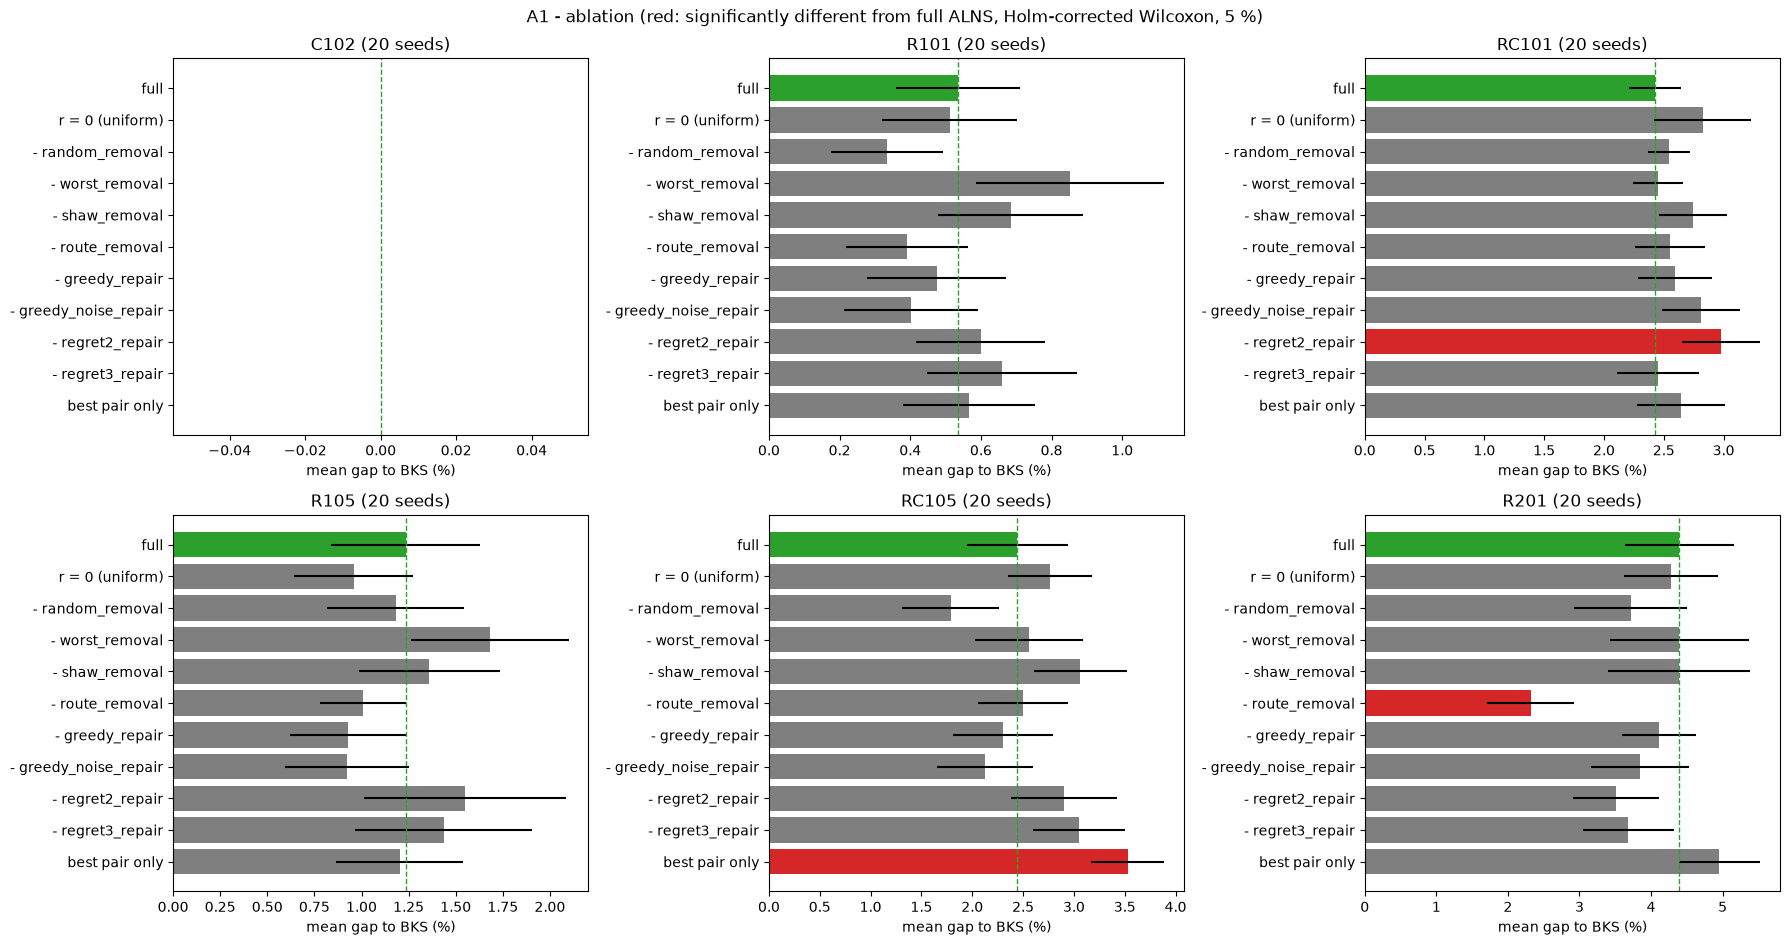

In [28]:
# Mean gap with 95 % confidence interval per variant (one panel per instance)
fig, axes = plt.subplots(math.ceil(len(A1_FILES) / 3), 3, figsize=(18, 4.8 * math.ceil(len(A1_FILES) / 3)))
for ax, (name, t) in zip(axes.flat, a1_table.groupby("instance", sort=False)):
    mean_gap = t.mean_gap.clip(lower=0)                     # gaps of -0.0003 % come from the BKS rounded to 2 decimals
    err = np.vstack([mean_gap - t.ci95_low.clip(lower=0), t.ci95_high.clip(lower=0) - mean_gap])
    colors = ["tab:green" if v == "full" else ("tab:red" if p < 0.05 else "tab:gray")
              for v, p in zip(t.variant, t.p_wilcoxon_holm.fillna(1))]
    ax.barh(t.variant, mean_gap, xerr=err, color=colors)
    ax.axvline(mean_gap[t.variant == "full"].iloc[0], color="tab:green", ls="--", lw=1)
    ax.invert_yaxis(); ax.set_title(f"{name} (20 seeds)"); ax.set_xlabel("mean gap to BKS (%)")
fig.suptitle("A1 - ablation (red: significantly different from full ALNS, Holm-corrected Wilcoxon, 5 %)")
plt.tight_layout(); plt.show()

### Analysis of A1

- **C102 does not discriminate**: every variant reaches the BKS in every run (Friedman $p = 0.50$). The Friedman test over the 11 variants is significant on RC105 ($p = 2 \times 10^{-5}$) and R201 ($p = 7 \times 10^{-4}$), close to 5 % on R101 and R105 ($p = 0.07$), and not significant on RC101 ($p = 0.48$).
- **Three differences survive the Holm correction:**
  - on R201, **removing route removal improves** the mean gap from 4.40 % to 2.32 % ($A_{12} = 0.11$, $p_{Holm} = 0.006$);
  - on RC105, **the best pair only** (random removal + regret-2) is worse than the full portfolio (3.53 % vs 2.44 %, $A_{12} = 0.83$, $p_{Holm} < 0.001$);
  - on RC101, **removing regret-2** is worse (2.98 % vs 2.43 %, $A_{12} = 0.71$, $p_{Holm} = 0.049$).
- **Trends that do not survive the correction**, but are consistent across instances:
  - *without worst removal*, the gap rises on R101 (0.85 % vs 0.53 %, raw $p = 0.09$) and R105 (1.68 % vs 1.23 %, raw $p = 0.07$);
  - *without Shaw removal*, it rises on R101, RC101, R105 and RC105 (3.06 % vs 2.44 %, raw $p = 0.10$);
  - *without regret-3*, it rises on R101, R105 and RC105;
  - *without random removal*, it decreases on R101 (0.33 %), RC105 (1.79 %, raw $p = 0.044$) and R201 (3.71 %); *without a greedy repair*, it decreases on R105 and RC105. These operators seem to use iterations without bringing much.
- **Adaptive weights.** The uniform selection ($r = 0$) is never significantly different from the adaptive one ($p_{Holm} \ge 0.80$). It is slightly worse on RC101 (2.83 %) and RC105 (2.76 %), slightly better on R105 (0.96 %) and R201. With 20 segments and $r = 0.1$, the weights have little time to move (see A2), so the adaptive layer brings little in 2000 iterations.

## Experiment A2: operator usage and weight dynamics (RQ4)

**Design.** We reuse the full ALNS runs of A1 (C102, R101, RC101, R105, RC105, R201). The weights are logged at the end of every segment (100 iterations). Selection probability $= w_o / \sum w$, averaged over the 20 seeds.

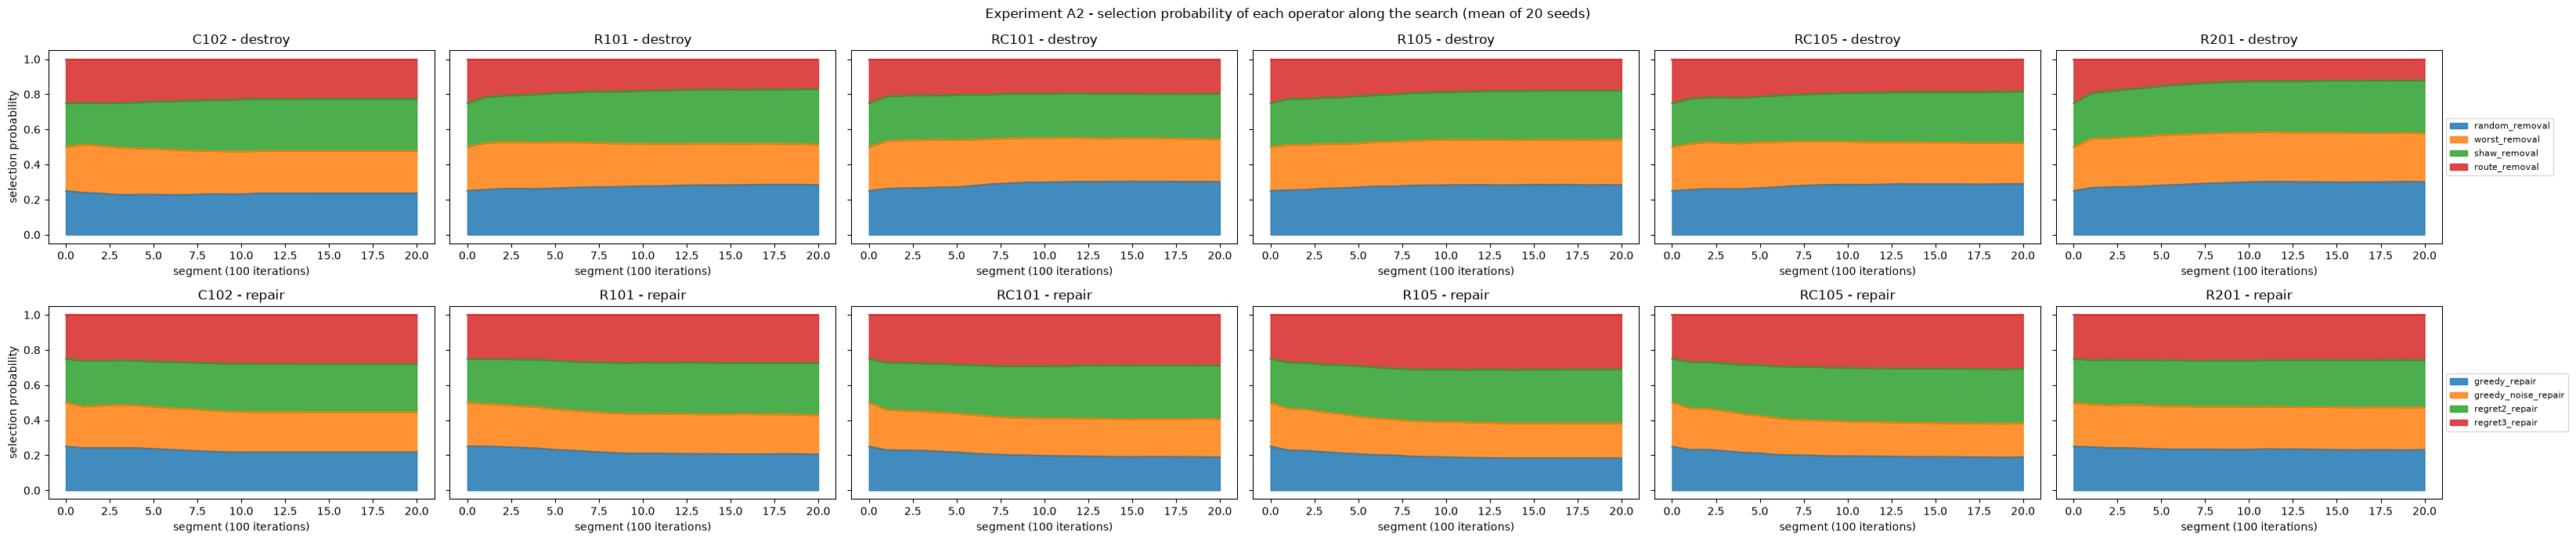

In [29]:
names = list(full_hist)
fig, axes = plt.subplots(2, len(names), figsize=(5.5 * len(names), 7), sharey=True)
for c, name in enumerate(names):
    for row, key in enumerate(("wD", "wR")):
        probs = [pd.DataFrame(h[key]).pipe(lambda W: W.div(W.sum(axis=1), axis=0)) for h in full_hist[name]]
        P = sum(probs) / len(probs)                         # selection probability, averaged over the seeds
        P.plot.area(ax=axes[row, c], alpha=.85, legend=False)
        axes[row, c].set_title(f"{name} - {'destroy' if key == 'wD' else 'repair'}")
        axes[row, c].set_xlabel("segment (100 iterations)"); axes[row, c].set_ylabel("selection probability")
        if c == len(names) - 1:
            axes[row, c].legend(*axes[row, c].get_legend_handles_labels(), loc="center left", bbox_to_anchor=(1, .5), fontsize=8)
fig.suptitle("Experiment A2 - selection probability of each operator along the search (mean of 20 seeds)")
plt.tight_layout(); plt.show()

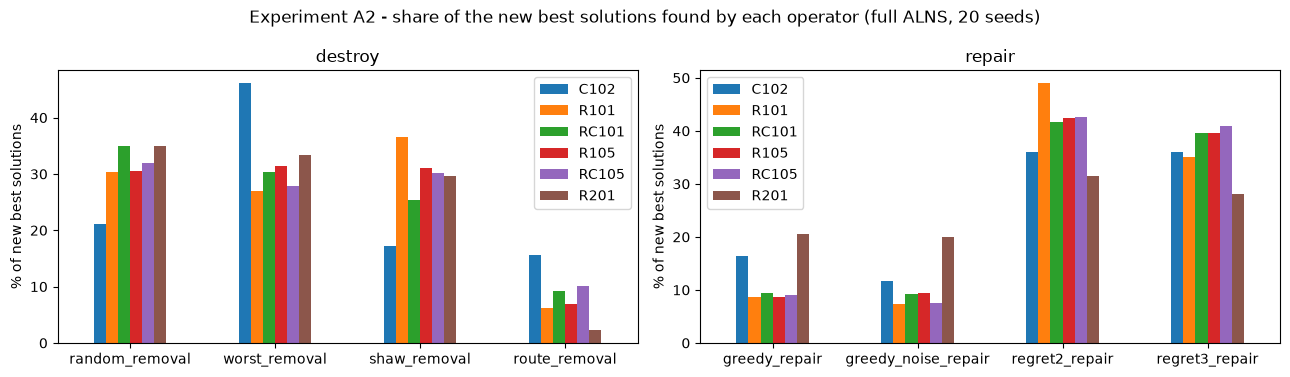

C102  R101  RC101  R105  RC105  R201
newbestD random_removal       21.1  30.3   35.0  30.5   31.9  34.9
         worst_removal        46.1  27.0   30.4  31.5   27.8  33.3
         shaw_removal         17.2  36.5   25.3  31.1   30.2  29.6
         route_removal        15.6   6.2    9.3   6.9   10.1   2.2
newbestR greedy_repair        16.4   8.7    9.4   8.7    9.1  20.5
         greedy_noise_repair  11.7   7.3    9.3   9.4    7.5  19.9
         regret2_repair       35.9  49.0   41.6  42.4   42.6  31.5
         regret3_repair       35.9  35.1   39.7  39.5   40.9  28.1

In [30]:
# Share of the new best solutions found by each operator (full ALNS runs)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
shares = {}
for ax, key, ops in ((axes[0], "newbestD", DNAMES), (axes[1], "newbestR", REPAIR_NAMES)):
    share = pd.DataFrame({name: {o: sum(h[key][o] for h in full_hist[name]) for o in ops} for name in names})
    shares[key] = 100 * share / share.sum()
    shares[key].plot.bar(ax=ax, rot=0)
    ax.set_ylabel("% of new best solutions"); ax.set_title("destroy" if key == "newbestD" else "repair")
fig.suptitle("Experiment A2 - share of the new best solutions found by each operator (full ALNS, 20 seeds)")
plt.tight_layout(); plt.show()
pd.concat(shares).round(1)

### Analysis of A2

- **Destroy operators:** the selection probabilities stay close to uniform (0.23 to 0.32) on every instance, except route removal, which falls to 0.17 to 0.20 on the series-1 R and RC instances and to 0.12 on R201. Shaw removal gains a little (0.26 to 0.32 at the end of the run). **R201 is the clearest case:** with 6 long routes, removing a whole route destroys about 15 % of the solution, which is rarely accepted. This matches A1, where removing route removal gives a significantly better gap on R201.
- **Repair operators:** the two regret repairs gain probability, from 0.50 to 0.55 on C102, 0.58 to 0.62 on the series-1 R and RC instances, and 0.53 on R201. The greedy repairs keep 0.18 to 0.24 each. The weights move less than in a version where an unchanged solution was rewarded: a candidate of the same cost now scores 0, so only real improvements and accepted worse moves change the weights.
- **New best solutions:** regret-2 and regret-3 find **72 to 85 % of the new best solutions** on the series-1 instances (60 % on R201), the greedy repairs only 15 to 40 %. On the destroy side, the new best solutions are spread between random, worst and Shaw removal (17 to 46 % each), and route removal finds only 2 to 16 % of them, which is consistent with A1.

## Experiment C: cost of the time windows and of the limited fleet (RQ5)

**Design.** On the eighteen 100-customer instances, we compare the ALNS on the original problem with the ALNS on two relaxed problems, removing one constraint at a time:
- **no time windows**: every window is opened to $[0, +\infty)$, which turns the problem into a CVRP;
- **unlimited fleet**: as many vehicles as customers.

Default configuration, 2000 iterations, 20 seeds; the original runs are the "default | 2000" runs of B. The cost of a constraint is the extra distance it causes: $\Delta = d_{\text{original}} - d_{\text{relaxed}}$, measured on the mean and on the best of the 20 runs. Both problems are solved heuristically, so $\Delta$ is an estimate.

**Fleet where it is tight.** On the 100-customer instances the fleet (25 vehicles) is larger than what a good solution uses, except on C102. We therefore also relax the fleet on C1_2_1 and C1_10_1, whose fleet equals the number of vehicles of the BKS (20 and 100), and compare the feasibility rate and the distance.

In [31]:
C_FILES = [f for f in SMALL_FILES if get_instance(f)["n_customers"] == 100]      # every 100-customer instance
TIGHT_FLEET = ["C1_2_1.200.20.vrptw", "C1_10_1.1000.100.vrptw"]                  # fleet = vehicles of the BKS
RELAX = ["no time windows", "unlimited fleet"]
jobs = [(f, s, r, dict(relax=r, iterations=2000), ()) for f in C_FILES for s in SEEDS for r in RELAX]
jobs += [(f, s, "unlimited fleet", dict(relax="unlimited fleet", iterations=2000), ()) for f in TIGHT_FLEET for s in SEEDS]
cons, _ = cached("C_constraints", jobs)
base = bench[bench.file.isin(C_FILES + TIGHT_FLEET) & (bench.variant == "default | 2000")].assign(variant="original")
cc = pd.concat([base, cons], ignore_index=True)

rows = []
for name, g in cc.groupby("instance", sort=False):
    o = g[g.variant == "original"].sort_values("seed")
    for r in RELAX:
        x = g[g.variant == r].sort_values("seed")
        if x.empty:                                          # C1_2_1 and C1_10_1: fleet relaxation only
            continue
        rows.append(dict(instance=name, constraint=r.replace("no ", "").replace("unlimited fleet", "fleet limit"),
                         mean_dist_original=o.dist.mean(), mean_dist_relaxed=x.dist.mean(),
                         best_dist_original=o.dist.min(), best_dist_relaxed=x.dist.min(),
                         vehicles_original=o.vehicles.mean(), vehicles_relaxed=x.vehicles.mean(),
                         cost_mean_pct=100 * (o.dist.mean() - x.dist.mean()) / x.dist.mean(),
                         cost_best_pct=100 * (o.dist.min() - x.dist.min()) / x.dist.min(),
                         p_wilcoxon=wilcoxon_p(o.dist, x.dist), feasible_original=100 * o.feasible.mean(),
                         feasible_relaxed=100 * x.feasible.mean(), unserved_original=o.unassigned.mean(),
                         unserved_relaxed=x.unassigned.mean()))
constraint_cost = pd.DataFrame(rows)
constraint_cost["p_holm"] = holm(constraint_cost.p_wilcoxon)
constraint_cost.round(3)

,instance,constraint,mean_dist_original,mean_dist_relaxed,best_dist_original,best_dist_relaxed,vehicles_original,vehicles_relaxed,cost_mean_pct,cost_best_pct,p_wilcoxon,feasible_original,feasible_relaxed,unserved_original,unserved_relaxed,p_holm
0,C101,time windows,828.937,826.385,828.937,819.558,10.00,10.00,0.309,1.144,0.586,100.0,100.0,0.00,0.0,1.000
1,C101,fleet limit,828.937,828.937,828.937,828.937,10.00,10.00,0.000,0.000,1.000,100.0,100.0,0.00,0.0,1.000
2,C1_2_1,fleet limit,2705.634,2704.568,2704.568,2704.568,20.00,20.00,0.039,0.000,0.317,95.0,100.0,0.05,0.0,1.000
3,C102,time windows,828.937,824.176,828.937,819.558,10.00,10.00,0.578,1.144,0.059,100.0,100.0,0.00,0.0,1.000
4,C102,fleet limit,828.937,828.937,828.937,828.937,10.00,10.00,-0.000,-0.000,1.000,100.0,100.0,0.00,0.0,1.000
5,R101,time windows,1651.657,835.958,1642.877,828.262,19.80,8.00,97.576,98.352,0.000,100.0,100.0,0.00,0.0,0.000
6,R101,fleet limit,1651.657,1650.913,1642.877,1642.877,19.80,19.85,0.045,0.000,0.317,100.0,100.0,0.00,0.0,1.000
7,RC101,time windows,1662.947,986.447,1644.666,977.447,16.25,9.00,68.579,68.261,0.000,100.0,100.0,0.00,0.0,0.000
8,RC101,fleet limit,1662.947,1662.947,1644.666,1644.666,16.25,16.25,0.000,0.000,1.000,100.0,100.0,0.00,0.0,1.000
9,R105,time windows,1376.906,835.066,1360.783,827.393,15.25,8.00,64.886,64.466,0.000,100.0,100.0,0.00,0.0,0.000


### Analysis of C

- **Time windows are the expensive constraint on random and mixed instances.** Without them, the mean distance drops by a large amount on all 13 R and RC instances (Wilcoxon, $p_{Holm} < 0.001$ for each). The cost of the windows ranges from **+17 % (RC108) to +98 % (R101)**: +98, +77, +65, +40 % on R101, R102, R105, R109; +69, +36, +58, +17 % on RC101, RC103, RC105, RC108; +80, +60, +22 % on R201, R202, R211; +94, +71 % on RC201, RC202. The relaxed problem uses 2 to 9 vehicles instead of 3 to 20.
- **The cost decreases when the windows get wider.** R109 (width 59) costs 40 % against 98 % for R101 (10); RC108 (112) 17 % against 69 % for RC101 (30); R211 (472) 22 % against 80 % for R201 (116); RC202 (319) 71 % against 94 % for RC201 (120). With narrow windows, a vehicle can only serve a few customers in a row. R102 and RC103 are in between because only a part of their customers have a narrow window. In series 2 the relaxed problem merges the 3 to 8 routes into 2 vehicles, hence a large cost even with wide windows.
- **On the clustered instances, the time windows cost almost nothing** (+0.3 to +1.2 % on the mean, +1.0 to +1.8 % on the best run; none significant after correction). The customers of a cluster have compatible windows, so the routes that respect the windows are also short routes.
- **The fleet limit costs nothing on the 100-customer instances.** The runs with an unlimited fleet are identical to the original ones (same seeds, same solutions), except one run on R101 (+0.05 %, not significant). On 17 of these instances the ALNS uses 3 to 20 vehicles out of 25, so the constraint is not active; on C102 it is active (10 used out of 10) but relaxing it changes nothing.
- **Where the fleet is tight, it limits feasibility.** On C1_2_1 (20 vehicles, as many as the BKS), 95 % of the original runs are feasible against 100 % with an unlimited fleet, and the distances are the same. On C1_10_1 (100 vehicles, as many as the BKS), 75 % of the original runs are feasible (0.65 unserved customers per run) against **100 %** with an unlimited fleet, but the relaxed runs use 103.4 vehicles and are **3.5 % longer** on average (best run 43 251 against 42 477; $p_{Holm} < 0.001$). Without the limit, the ALNS serves the last customers with extra routes instead of finding room in the existing ones, and 2000 iterations are not enough to merge them back. The fleet limit therefore costs feasibility on C1_10_1, not distance.
- Both problems are solved heuristically, so these costs are estimates, and the bias can go either way. On C101, for example, the relaxed runs are far from their own best (mean 826.4 against a best run of 819.6), so the relaxed problem is not solved to optimality and the cost of the windows is underestimated there. On the R and RC instances the differences (17 to 98 %) are far larger than this noise.

## CO$_2$ impact

**Emission factor.** We assume that one distance unit is 1 km and that the routes are driven by 19 t rigid diesel trucks. We use **EF = 0.84 kg CO$_2$e per km**, the value for a 19 t rigid truck computed from the ADEME *Base Empreinte* factor for road diesel (as published by Celsius, *Émissions CO2 d'un camion*, projetcelsius.com). The ADEME factor for diesel itself is about 3.1 kg CO$_2$e per litre. A different vehicle only scales every value by the same factor (for example about 0.5 kg/km for a light commercial vehicle).

**Measures.** Emissions of one execution of the routes, $\text{CO}_2 = \text{EF} \times d$. We report them for the construction heuristic (initial regret-2 solution), the default and tuned ALNS (mean over 20 runs, 2000 iterations) and the BKS. We also report the cost of each constraint from experiment C, and a yearly figure assuming the same routes are driven 250 days a year.

In [32]:
EF = 0.84          # kg CO2e per km (19 t rigid diesel truck, ADEME Base Empreinte); assumption: 1 distance unit = 1 km
DAYS = 250         # working days per year, for the yearly figures

rows = []
for name, g in bench[bench.budget == 2000].groupby("instance", sort=False):
    init = g[g.initial_unassigned == 0].initial_dist      # the construction is only comparable when it serves everyone
    row = dict(instance=name, construction_kg=EF * init.mean() if len(init) else np.nan)
    for c in CONFIGS:
        gc = g[(g.config == c) & g.feasible]
        row[f"alns_{c}_kg"] = EF * gc.dist.mean() if len(gc) else np.nan
    row["BKS_kg"] = EF * BKS[name]
    best_alns = pd.Series([row[f"alns_{c}_kg"] for c in CONFIGS]).min()   # nan if no feasible run
    row["saving_vs_construction_pct"] = 100 * (1 - best_alns / row["construction_kg"])
    row["saving_vs_construction_t_per_year"] = (row["construction_kg"] - best_alns) * DAYS / 1000
    row["excess_vs_BKS_pct"] = 100 * (best_alns / row["BKS_kg"] - 1)
    rows.append(row)
co2 = pd.DataFrame(rows)
display(co2.round(2))

co2_constraints = constraint_cost[["instance", "constraint"]].assign(
    extra_kg_per_day=EF * (constraint_cost.mean_dist_original - constraint_cost.mean_dist_relaxed),
    extra_t_per_year=EF * (constraint_cost.mean_dist_original - constraint_cost.mean_dist_relaxed) * DAYS / 1000)
co2_constraints.round(2)

,instance,construction_kg,alns_default_kg,alns_tuned_kg,BKS_kg,saving_vs_construction_pct,saving_vs_construction_t_per_year,excess_vs_BKS_pct
0,C101,696.31,696.31,696.31,696.31,-0.00,-0.00,0.00
1,C1_2_1,NaN,2271.84,2271.84,2271.84,NaN,NaN,-0.00
2,C102,790.15,696.31,696.31,696.31,11.88,23.46,-0.00
3,R101,1493.73,1387.39,1386.57,1380.02,7.17,26.79,0.48
4,RC101,1710.32,1396.88,1399.14,1363.79,18.33,78.36,2.43
5,R105,1327.61,1156.60,1155.81,1142.50,12.94,42.95,1.16
6,R109,1177.15,981.15,986.43,967.61,16.65,49.00,1.40
7,RC105,1533.40,1306.20,1305.83,1275.06,14.84,56.89,2.41
8,RC108,1515.66,965.94,963.42,938.72,36.44,138.06,2.63
9,C201,496.91,496.91,496.91,496.91,-0.00,-0.00,0.00


,instance,constraint,extra_kg_per_day,extra_t_per_year
0,C101,time windows,2.14,0.54
1,C101,fleet limit,0.00,0.00
2,C1_2_1,fleet limit,0.90,0.22
3,C102,time windows,4.00,1.00
4,C102,fleet limit,-0.00,-0.00
5,R101,time windows,685.19,171.30
6,R101,fleet limit,0.63,0.16
7,RC101,time windows,568.26,142.06
8,RC101,fleet limit,0.00,0.00
9,R105,time windows,455.15,113.79


### Analysis of the CO$_2$ impact

- **Optimisation vs construction.** On the instances where the regret-2 construction serves every customer, the ALNS reduces the emissions by **2 to 36 %**: 2.2 % on R102, 7.2 % on R101, 12 to 19 % on C102, C202, R105, RC105, R202, R109, R201, C103 and RC101, 24 to 26 % on RC201, RC202, R211 and RC103, and 36 % on RC108. This is **7 to 138 t CO$_2$e per year** for a single daily tour. On C101 and C201 the construction is already optimal; on C1_2_1 and C1_10_1 it leaves customers unserved, so it cannot be compared.
- **Remaining margin.** The ALNS routes are 0 to 7.6 % above the BKS: improving the algorithm further would save at most about 53 kg per day (13 t per year, R211). The gain from optimising at all is much larger than the gain from optimising better (550 kg per day on RC108).
- **Time windows.** The time windows of the R and RC instances cost 125 (R211) to 685 kg CO$_2$e per day (R101), i.e. 31 to 171 t per year, compared with free delivery times. This quantifies the environmental cost of narrow delivery slots, while it is below 7 kg per day on the clustered instances.
- **Fleet limit.** It costs nothing on the 100-customer instances and 0.9 kg per day on C1_2_1. On C1_10_1 the limited fleet emits 1250 kg per day **less** than the unlimited one, but at the price of unserved customers in 25 % of the runs.
- These figures scale linearly with the emission factor and assume that a distance unit is 1 km and that the routes are driven every working day.

## Experiment S: time per iteration vs $n$ (RQ6)

**Design.** 100 iterations, 3 seeds, on eight clustered instances from 25 to 1000 customers. We measure full ALNS (default configuration) and ALNS restricted to each repair operator, excluding the time of the initial solution. This experiment was run alone on the machine, in a single session for all sizes, so its times are not inflated by parallel runs and can be compared with each other.

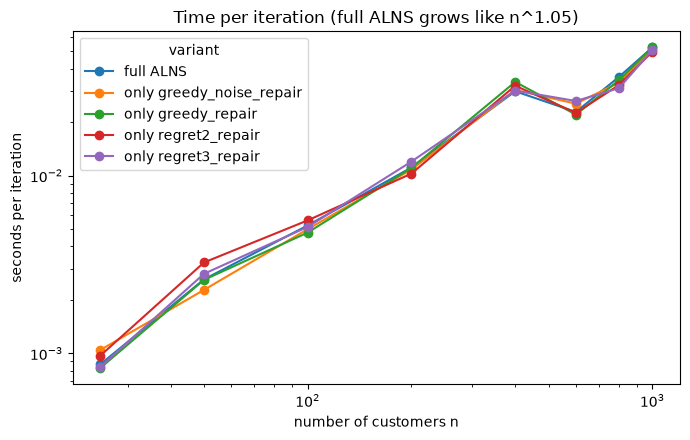

,initial solution (s)
n,
25,0.01
50,0.04
100,0.09
200,0.28
400,1.49
600,3.02
800,5.15
1000,6.62


variant,full ALNS,only greedy_noise_repair,only greedy_repair,only regret2_repair,only regret3_repair
n,,,,,
25,0.0009,0.0010,0.0008,0.0010,0.0008
50,0.0026,0.0023,0.0026,0.0032,0.0028
100,0.0052,0.0050,0.0048,0.0056,0.0051
200,0.0111,0.0108,0.0111,0.0103,0.0120
400,0.0298,0.0303,0.0337,0.0320,0.0301
600,0.0228,0.0254,0.0220,0.0225,0.0263
800,0.0359,0.0334,0.0344,0.0323,0.0311
1000,0.0527,0.0512,0.0527,0.0499,0.0510


In [33]:
SIZE_FILES = ["C101.25.3.vrptw", "C101.50.5.vrptw", "C101.txt", "C1_2_1.200.20.vrptw", "C1_4_1.400.40.vrptw",
              "C1_6_1.600.60.vrptw", "C1_8_1.800.80.vrptw", "C1_10_1.1000.100.vrptw"]
size_variants = {"full ALNS": {}, **{f"only {o}": {"repair": [o]} for o in REPAIR_NAMES}}
jobs = [(f, s, label, dict(kw, iterations=100), ()) for f in SIZE_FILES for s in range(3)
        for label, kw in size_variants.items()]
sz, _ = cached("S_time_per_iteration", jobs)

Tn = sz.groupby(["variant", "n"]).iter_time.mean().unstack(0)
ax = Tn.plot(marker="o", logx=True, logy=True, figsize=(7, 4.5))
ax.set_xlabel("number of customers n"); ax.set_ylabel("seconds per iteration")
slope = np.polyfit(np.log(Tn.index), np.log(Tn["full ALNS"]), 1)[0]
ax.set_title(f"Time per iteration (full ALNS grows like n^{slope:.2f})")
plt.tight_layout(); plt.show()
init_time = (sz.runtime - sz.iter_time * sz.iterations).groupby(sz.n).mean()
display(pd.DataFrame({"initial solution (s)": init_time}).round(2))
Tn.round(4)

In [34]:
# Dispersion of the time per iteration over the 3 seeds (ms): mean, std, median and MAD per operator and size
spread(sz.assign(iter_ms=1000 * sz.iter_time), ["variant", "n"], ["iter_ms"]).drop(columns=["instances", "runs"]).round(2) 

iter_ms                   
                                 mean   std median   MAD
variant                  n                              
full ALNS                25      0.87  0.30   0.74  0.10
only greedy_repair       25      0.83  0.16   0.80  0.13
only greedy_noise_repair 25      1.04  0.40   1.26  0.03
only regret2_repair      25      0.97  0.21   1.06  0.05
only regret3_repair      25      0.84  0.07   0.83  0.06
full ALNS                50      2.61  0.39   2.80  0.06
only greedy_repair       50      2.59  0.35   2.78  0.03
only greedy_noise_repair 50      2.27  0.43   2.24  0.37
only regret2_repair      50      3.24  1.64   2.87  1.05
only regret3_repair      50      2.80  0.90   2.69  0.74
full ALNS                100     5.24  0.65   4.93  0.12
only greedy_repair       100     4.78  0.68   4.46  0.15
only greedy_noise_repair 100     5.00  1.19   4.51  0.38
only regret2_repair      100     5.60  0.34   5.58  0.32
only regret3_repair      100     5.15  0.39   5.18  0.34
full ALNS                200    11.11  1.55  10.38  0.33
only greedy_repair       200    11.06  1.18  11.33  0.76
only greedy_noise_repair 200    10.82  0.73  10.65  0.47
only regret2_repair      200    10.26  0.66  10.57  0.14
only regret3_repair      200    12.00  2.27  11.90  2.13
full ALNS                400    29.82  1.84  29.60  1.49
only greedy_repair       400    33.67  3.86  35.41  0.95
only greedy_noise_repair 400    30.31  0.64  30.08  0.26
only regret2_repair      400    32.04  3.87  34.14  0.27
only regret3_repair      400    30.09  4.49  28.39  1.69
full ALNS                600    22.81  0.61  22.60  0.27
only greedy_repair       600    22.04  0.90  22.17  0.69
only greedy_noise_repair 600    25.39  3.79  23.47  0.54
only regret2_repair      600    22.53  1.23  21.89  0.13
only regret3_repair      600    26.28  2.43  24.95  0.14
full ALNS                800    35.93  2.66  35.06  1.24
only greedy_repair       800    34.41  4.29  35.36  2.79
only greedy_noise_repair 800    33.39  5.15  34.36  3.62
only regret2_repair      800    32.34  4.09  31.33  2.49
only regret3_repair      800    31.06  3.02  32.47  0.66
full ALNS                1000   52.65  1.81  51.88  0.53
only greedy_repair       1000   52.66  4.13  50.33  0.09
only greedy_noise_repair 1000   51.25  2.02  51.02  1.67
only regret2_repair      1000   49.85  2.65  50.83  1.03
only regret3_repair      1000   50.97  2.45  51.34  1.87

### Analysis of S

- **Growth with $n$.** The time per iteration of the full ALNS is 0.9 ms at $n = 25$, 5.2 ms at $n = 100$, 11 ms at $n = 200$, 30 ms at $n = 400$, 23 ms at $n = 600$, 36 ms at $n = 800$ and 53 ms at $n = 1000$. The log-log fit over the eight sizes gives $n^{1.05}$; from 200 customers on it gives $n^{0.84}$.
- **Why the growth is about linear.** For $n \ge 134$, $q$ is capped at 40 (and equals 5 % of $n$ from 800 on: 50 at $n = 1000$), so each iteration reinserts a bounded number of customers. Each of them is still tested in every route, and the number of routes grows with $n$, so the cost of an iteration is $O(q \cdot n)$: linear in $n$ once $q$ is bounded. Without the cap, $q$ grows with $n$ and the cost becomes quadratic (tuned configuration in B: 1.8 times slower per iteration on C1_2_1).
- **The bump at $n = 400$ is real, not noise** (std 1.8 ms over the 3 seeds). On C1_4_1 the initial solution leaves 34 customers unserved, and 12 are still unserved after 100 iterations; the repair tries to insert all of them at every iteration. C1_6_1 and C1_8_1 start feasible, hence a lower time at $n = 600$. The time per iteration therefore depends on the number of unserved customers, not only on $n$.
- **Dispersion** is small: for the full ALNS, the standard deviation over the 3 seeds is below 10 % of the mean from $n = 400$ on, and 12 to 35 % below $n = 400$, where an iteration takes only a few milliseconds (dispersion table above).
- **Repair operators** cost about the same per iteration (see the analysis of the algorithm parameters above).
- **Initial solution.** The regret-2 construction takes 0.09 s at $n = 100$, 1.5 s at $n = 400$ and 6.6 s at $n = 1000$, i.e. the equivalent of about 125 ALNS iterations at $n = 1000$.
- **Parallel load.** Compared with S, the runs of T, B, A1 and C (11 processes in parallel on 12 logical cores, with about 2 GB of free memory) are 3.1 times slower per iteration on C101, 3.4 times on C1_2_1 and 6.2 times on C1_10_1. Their times can only be compared with each other.
- **Practical consequence:** on an idle machine, 2000 iterations take about 11 s at $n = 100$ and 2 min at $n = 1000$. At $n = 1000$ this budget leaves 25 % of the runs infeasible (B), so the budget should grow with $n$; a $q$ proportional to $n$ reduces the number of unserved customers without making the iterations slower.

## Correctness and raw data

Every final solution of every run is checked by `check_solution`, which is independent of the ALNS code: it checks that no customer is served twice and counts the unserved customers (two separate messages), the fleet size, the capacity of each route and the time windows, and it recomputes the cost from the routes. Below we check that no run violates a constraint (an unserved customer is reported as an incomplete solution, not as a violation; a customer served twice would be a violation), and that the recomputed cost equals the cost computed by the ALNS. The raw results of every run are exported as CSV files in `results/`.

In [35]:
all_runs = pd.concat([tun.assign(experiment="T"), bench.assign(experiment="B"), abl.assign(experiment="A1"),
                      pair.assign(experiment="A1"), cons.assign(experiment="C"), sz.assign(experiment="S")],
                     ignore_index=True)
assert (all_runs.violations == 0).all(), "a final solution violates capacity, time windows or fleet size"
assert (all_runs.cost_mismatch < 1e-6).all(), "recomputed cost differs from the ALNS cost"

for name, df in {"T_q_temperature": tun, "B_benchmark_budgets": bench, "A1_ablation": abl, "A1_best_pair": pair,
                 "C_constraints": cons, "S_time_per_iteration": sz}.items():
    df.to_csv(f"results/{name}.csv", index=False)

all_runs.groupby("experiment", sort=False).agg(runs=("seed", "size"), feasible_pct=("feasible", "mean"),
    violations=("violations", "sum"), max_cost_mismatch=("cost_mismatch", "max")).assign(
    feasible_pct=lambda d: 100 * d.feasible_pct)

,runs,feasible_pct,violations,max_cost_mismatch
experiment,,,,
T,480,97.916667,0,4.092726e-12
B,2700,99.296296,0,8.731149e-11
A1,1200,100.000000,0,1.818989e-12
C,760,100.000000,0,7.275958e-11
S,120,62.500000,0,8.003553e-11


## Conclusions

| RQ | Answer |
|---|---|
| RQ1 ($q$, $w$) | $q$ is the parameter that matters: $q \ge 10\,\%$ of $n$ always reaches the BKS of C1_2_1, $q \in [5,15]\,\%$ only in 69 % of the runs. $w$ has no significant effect: with $T_0$ computed on the distance, the temperature controls the acceptance of worse solutions, but the diversification needed on this instance comes from $q$. |
| RQ2 (quality, budget) | At 2000 iterations, mean gap 0 to 0.2 % on the clustered instances, 0.4 to 2 % on R1, 2.4 to 6 % on RC1, 2.6 to 4.6 % on series 2 except R211 (7.6 to 8.5 %, the only instance above the 7 % target). On C1_10_1, 75 % of the runs are feasible and those are within 0.3 % of the BKS; $q$ proportional to $n$ reduces the number of unserved customers but not significantly. Tuned and default are not significantly different after Holm correction; tuned is mostly useful when the initial solution is infeasible (C1_2_1). The gap still decreases from 2000 to 5000 iterations (significant on R109 and RC103). The LP relaxation proves that the ALNS is optimal or within 2 % of the optimum on C101, C1_2_1, C201 and R101, but the bound is weak (15 to 79 % below the BKS) on the instances with wide windows. |
| RQ3 (ablation) | Three effects survive the Holm correction: removing route removal improves R201, the best pair alone is worse on RC105, and removing regret-2 is worse on RC101. Worst and Shaw removal and the regret repairs tend to help, random removal and the greedy repairs tend to use iterations for little gain. Adaptive weights are not better than uniform selection in 2000 iterations. |
| RQ4 (operator usage) | Destroy weights stay almost uniform, except route removal, which loses weight (0.12 on R201). Regret repairs take 55 to 62 % of the selection and produce 72 to 85 % of the new best solutions (60 % on R201). |
| RQ5 (constraints) | Time windows cost +17 to +98 % of distance on the R / RC instances, more when the windows are narrow, and almost nothing on the clustered instances. The fleet limit costs nothing on the 100-customer instances; where it is tight (C1_10_1), it makes 25 % of the runs infeasible, and relaxing it serves every customer with 3.4 more vehicles and 3.5 % more distance. |
| RQ6 (scalability) | Time per iteration grows like $n^{1.05}$ over 25 to 1000 customers, and like $n^{0.84}$ from 200 customers, because $q$ is bounded (cost $O(q \cdot n)$ per iteration): 5 ms at $n = 100$, 53 ms at $n = 1000$ on an idle machine. It also grows with the number of unserved customers. The initial solution takes 6.6 s at $n = 1000$. |

**Limits.**
- Only one algorithm (ALNS) is studied in this notebook, so the comparison between algorithms of the guide (same tuning effort for GRASP, TS, ALNS) does not apply. Within the ALNS, both configurations are compared at equal iterations, and at roughly equal time with the pair tuned 1000 vs default 2000.
- The tuning was done on 2 instances, and C101 turned out to be non-informative (optimal initial solution). A larger tuning set would make the choice of $q$ more robust.
- The objective only minimises distance (with a penalty for unserved customers), not the number of vehicles. The reference solutions of the Solomon instances are the best known for total distance, so this is a fair reference for our objective.
- The running times of T, B, A1 and C come from 11 parallel processes and are 3 to 6 times larger than on an idle machine. Only S was timed alone.
- The CO$_2$ factor comes from a secondary source (Celsius, quoting ADEME Base Empreinte) and assumes 1 distance unit = 1 km.

## Checklist status

| Item | Status | Where / justification |
|---|---|---|
| Research questions written before running experiments | Done | RQ1 to RQ6 at the top of the study |
| Instances listed, with features (n, distribution) and tuning/test split | Done | 20 instances with a reference solution (2 tuning, 18 test), plus 5 sizes for scalability. Instance table (n, distribution, fleet, tightness, window width, BKS, role). `C1_2_1.txt` is not used: same instance as `C1_2_1.200.20.vrptw` with 50 vehicles instead of 20 |
| Quality indicator (gap, Eq. 1) and budget defined and justified | Done | Protocol section (gap with the penalty, 2000 iterations as reference budget, 500 / 1000 / 2000 / 5000 in B) |
| ≥ 20 runs per (instance, configuration), same seeds everywhere | Done | 20 seeds (0 to 19) in T, B, A1, C; 3 seeds only in S, which measures time, not quality |
| Every final solution checked for feasibility and cost recomputed | Done | `check_solution` on every run, assertions in the correctness section (0 violations, cost mismatch < $10^{-10}$) |
| Distances follow the CVRPLIB rounding convention | Justified deviation | These are Solomon / Gehring & Homberger instances: their BKS (SINTEF) use double-precision distances, so we do the same. Integer rounding would make the gaps meaningless |
| Caches / global state reset between runs; runs reproducible from the seed | Done | Assertions: `alns_exp` reproduces `alns`, and the same job run twice gives the same result. Each run uses its own seeded RNG |
| Benchmark table: instance, BKS, best & mean cost, gap, time, #vehicles | Done | Benchmark table of B |
| Mean, median, std, CI reported; boxplots and convergence curves | Done | `describe` (scipy `t.interval` for the CI), boxplots and convergence curves of B |
| Trajectory plots used to explain behaviour | Done | Trajectories and acceptance rate in T (diversification with $w = 20\,\%$ vs descent with $w = 0$) |
| Parameter sensitivity: ALNS (operators, $q$, acceptance) | Done | T ($q$ × $w$), A1 (operators, adaptive weights). GRASP $\alpha$ and TS tenure: not applicable (no GRASP / TS in this project) |
| Ablation of at least one component | Done | A1: each operator removed, uniform weights, best pair only |
| Statistical tests, multiple-comparison correction, effect sizes | Done | scipy: `wilcoxon`, `friedmanchisquare`, `fisher_exact`; statsmodels `multipletests` (Holm); Vargha–Delaney $A_{12}$ |
| Fair comparison (same budget, same tuning effort), several budgets | Partial | Same budgets (500 / 1000 / 2000), with the time ratio of each pair, an equal-time pair (tuned 1000 vs default 2000), and a longer budget (5000). "Same tuning effort" across algorithms does not apply to a single algorithm |
| Scalability study up to ≥ 1000 customers | Done | S (25 to 1000 customers) and C1_10_1 in B |
| Average gap < 5 % / < 7 %, or justification | Partial | < 7 % on 17 of the 18 instances of 100 customers (< 5 % on 16). R211 misses it (7.6 to 8.5 %, 7.2 % with 5000 iterations), explained in B. C1_10_1 (no target) discussed in B |
| Lower bound computed | Done | LP relaxation of the two-index ILP on the 19 instances of 100 and 200 customers (section "Lower bound") |
| Effect of instance and algorithm parameters on quality and time, with dispersion | Done | Tables by distribution, series and window width; time and last improvement by $q$, configuration and operator (mean, std, median, MAD) |
| Two extra constraints studied (cost of each constraint) | Done | C: time windows and fleet limit, with the fleet also relaxed where it is tight (C1_2_1, C1_10_1) |
| CO$_2$ impact quantified with a stated emission factor | Done | 0.84 kg CO$_2$e/km (19 t truck, ADEME via Celsius) |
| Environment table, code version, raw data and analysis scripts delivered | Done | Environment table (versions, git commit), raw CSV of every run in `results/`, all analysis code in this notebook |

## References

- Gehring, H., & Homberger, J. (1999). A parallel hybrid evolutionary metaheuristic for the vehicle routing problem with time windows. *Proceedings of EUROGEN99*, 57–64. Benchmark of 200 to 1000 customers.
- Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics*, 6(2), 65–70.
- Karp, R. M. (1972). Reducibility among combinatorial problems. In *Complexity of Computer Computations* (pp. 85–103). Springer. https://doi.org/10.1007/978-1-4684-2001-2_9
- Miller, C. E., Tucker, A. W., & Zemlin, R. A. (1960). Integer programming formulation of traveling salesman problems. *Journal of the ACM*, 7(4), 326–329. https://doi.org/10.1145/321043.321046
- Ropke, S., & Pisinger, D. (2006). An adaptive large neighborhood search heuristic for the pickup and delivery problem with time windows. *Transportation Science*, 40(4), 455–472. https://doi.org/10.1287/trsc.1050.0135
- Savelsbergh, M. W. P. (1985). Local search in routing problems with time windows. *Annals of Operations Research*, 4(1), 285–305. https://doi.org/10.1007/BF02022044
- Savelsbergh, M. W. P. (1992). The vehicle routing problem with time windows: minimizing route duration. *ORSA Journal on Computing*, 4(2), 146–154. https://doi.org/10.1287/ijoc.4.2.146
- Shaw, P. (1998). Using constraint programming and local search methods to solve vehicle routing problems. In *Principles and Practice of Constraint Programming – CP98* (LNCS 1520, pp. 417–431). Springer. https://doi.org/10.1007/3-540-49481-2_30
- Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research*, 35(2), 254–265. https://doi.org/10.1287/opre.35.2.254
- Toth, P., & Vigo, D. (Eds.) (2014). *Vehicle Routing: Problems, Methods, and Applications* (2nd ed.). SIAM. https://doi.org/10.1137/1.9781611973594
- Vargha, A., & Delaney, H. D. (2000). A critique and improvement of the CL common language effect size statistics of McGraw and Wong. *Journal of Educational and Behavioral Statistics*, 25(2), 101–132. https://doi.org/10.3102/10769986025002101

**Data and software.**
- SINTEF, *TOP – VRPTW benchmark, best known solutions*: https://www.sintef.no/projectweb/top/vrptw/
- PyVRP, *VRPLIB* instances and `vrplib` reader: https://github.com/PyVRP/VRPLIB
- Mitchell, S., O'Sullivan, M., & Dunning, I. (2011). *PuLP: a linear programming toolkit for Python*. CBC solver: COIN-OR Branch and Cut, https://github.com/coin-or/Cbc
- ADEME, *Base Empreinte* (emission factors), quoted by Celsius, *Émissions CO2 d'un camion*, projetcelsius.com.